# Per-User, Per-Hour Active Directory Behavioural Baseline & Risk Scoring

**Windows Security + Sysmon telemetry → user attribution → 10-minute windows → behavioural features →
Day 1-7 baselines → Day 8-12 scoring → explainable risk alerts.**

---

### What this notebook builds

| Stage | Output |
|---|---|
| Normalisation | one event-level dataframe covering every Security + Sysmon record |
| User attribution | evidence-based mapping of each event to a security principal (3 tiers + an explicit "cannot attribute" bucket) |
| Windowing | a **complete** `user x 10-minute window` grid - empty windows are kept, never dropped |
| Features | ~70 numeric features + 11 categorical behaviour dimensions per window |
| Baseline | robust `user x hour-of-day` statistics + per-user behavioural inventories, learned from the 7 normal days only |
| Scoring | 5 complementary anomaly signals fused into a bounded `risk_score` in [0, 1] |
| Explainability | ranked, human-readable reasons for every alert |
| Evaluation | precision / recall / PR-AUC / detection rate / **false positives per user per day**, against the scenario ground truth |

### Design commitments

1. **The baseline is user-specific and hour-specific, and deliberately *not* day-of-week specific.**
   `alice + hour 09` pools all six 10-minute windows of 09:00-10:00 from all seven training days (42 observations).
2. **No leakage.** Baselines, inventories, rarity tables and the ML model are fitted on days 1-7 only.
   Training-fold scores are produced by **leave-one-day-out** re-fitting so the "normal" score
   distribution is honest and usable for threshold selection.
3. **Anomaly is not maliciousness.** The output is a behavioural-deviation score with risk *bands*,
   plus the evidence that produced it.
4. **Assumptions are reported, never hidden.** Section 08 and the closing section list every event class
   that could not be attributed, every principal without a usable baseline, and every ground-truth step
   for which the dataset contains no attributable evidence.

> **How to run**
> 1. Put `updatedevents.jsonl` (and, when you have it, `GROUND_TRUTH.md`) in the folder you start Jupyter from,
>    or set `GT_PATH` in section 01.
> 2. Always use **Kernel → Restart & Run All**. Re-running single cells can leave stale outputs, which is how the
>    old confusion matrix showed numbers from a different version of its own code.
> 3. **No ground truth:** every evaluation cell prints `skipped` and the rest runs (alerts, incidents, artefacts).
>    **With ground truth:** section 20 builds the labels and the confusion matrix (20.7). Built-in checks stop the
>    notebook if the timeline doesn't parse, if an attack falls inside the training days, if no window gets labelled,
>    or if the confusion matrix disagrees with the operating-point numbers.


---
## 01. Project Configuration

Everything that a reviewer might want to change - paths, the timezone the "day" and "hour" are measured in,
the window length, the train/test split, the fusion weights - lives in this one cell.

**Timezone: everything is UTC.** Every timestamp in `events.jsonl` is UTC, and every timestamp in the
`## Timeline` and `## Red Herrings` tables of `GROUND_TRUTH.md` is explicitly suffixed `UTC`. The only place
that file mentions another zone is one header line describing *its own* suggested split
(`Baseline fit window : 2026-07-29 .. 2026-08-04 (7 days, local IST)`). Since the project configuration below
fixes its own split, no conversion is applied anywhere: `hour` means UTC hour, `date` means UTC date, and
window boundaries are UTC. Nothing in the pipeline shifts a clock.

**Capture coverage.** The log starts at `2026-07-28T18:30:21Z` and ends at `2026-08-09T18:29:57Z`, so the
first and last configured days are only partly covered by the sensor. Section 06 detects this from the data
and marks the uncovered windows `has_telemetry = False`. Those windows are excluded from the baseline and
from scoring - **not** because they are empty, but because "no sensor" and "user was idle" are different
facts and only the second one is behaviour. Every empty window *inside* the capture range is kept.

In [1]:
import os

# --- paths -----------------------------------------------------------------------
ROOT        = os.getcwd()          # run the notebook from the folder holding events.jsonl
EVENTS_PATH = os.path.join(ROOT, "days20.jsonl")
GT_PATH     = os.environ.get("GT_PATH", os.path.join(ROOT, "GROUND_TRUTH20.md"))
CACHE_DIR   = os.path.join(ROOT, "cache2")
OUT_DIR     = os.path.join(ROOT, "baseline_output2")
os.makedirs(CACHE_DIR, exist_ok=True)
os.makedirs(OUT_DIR, exist_ok=True)

# --- time ------------------------------------------------------------------------
# All analysis happens in UTC, which is the zone every timestamp in events.jsonl and in
# GROUND_TRUTH.md is already recorded in. No timezone conversion happens anywhere below.
TZ               = "UTC"
WINDOW           = "10min"     # the behavioural window length
WINDOWS_PER_HOUR = 6           # 60 / 10
WINDOWS_PER_DAY  = 144         # 24 * 6

# Baseline period: assumed to contain only normal activity.
TRAIN_DATES = ["2026-07-28", "2026-07-29", "2026-07-30", "2026-07-31",
               "2026-08-01", "2026-08-02", "2026-08-03"]
# Scoring period: may contain malicious activity. The first ground-truth attack event is
# 2026-08-04 21:40:06 UTC, so the whole attack chain falls inside this window.
TEST_DATES  = ["2026-08-04", "2026-08-05", "2026-08-06",
               "2026-08-07", "2026-08-08", "2026-08-09","2026-08-10","2026-08-11","2026-08-12","2026-08-13","2026-08-14","2026-08-15","2026-08-16","2026-08-17"]
ALL_DATES   = TRAIN_DATES + TEST_DATES

# --- scoping ---------------------------------------------------------------------
MIN_TRAIN_EVENTS = 200      # a principal below this cannot support a 24-hour baseline
BS = chr(92)                # backslash - Windows paths appear everywhere below

# --- scoring hyper-parameters ----------------------------------------------------
Z0, Z1        = 9.0, 22.0   # robust-z band where the statistical severity ramps 0 -> 1
K_STAT        = 1.6         # saturation constants for each component's squash
K_NOV         = 4.5
K_RARE        = 1.2
K_ACT         = 2.5
W_STAT, W_NOV, W_RARE, W_ACT, W_ML = 0.55, 0.88, 0.90, 0.80, 0.12   # noisy-OR fusion caps
# Option 2: temporal context. This is NOT a separate weekend behavioural baseline.
DAYTYPE_TZ = "Asia/Kolkata"   # weekday/weekend in the scenario's local time (GROUND_TRUTH.md), not UTC
TEMP_ALPHA = 4.0              # smoothing strength for sparse user/day_type/hour cells
W_TEMP = 0.10                 # noisy-OR cap; NOT tuned on test labels
FULL_W = {"s_stat": W_STAT, "s_nov": W_NOV, "s_rare": W_RARE, "s_act": W_ACT,
          "s_ml": W_ML, "s_temp": W_TEMP}

RISK_BANDS = [(0.25, "NORMAL"), (0.45, "LOW"), (0.60, "MEDIUM"), (0.80, "HIGH"), (1.01, "CRITICAL")]
# Operational alert budget: about one alert per user per five days - a queue a small
# SOC can actually work. The alert threshold is DERIVED
# from this on the baseline null in section 18; it is never tuned on the scored days.
FP_BUDGET_PER_USER_DAY = 0.20

# How a beacon row ("Beacon to IP:port (N attempts, Hh)") is labelled:
#   False -> only the window of its timestamp (what GROUND_TRUTH20.md asks for: ~140-150 cells)
#   True  -> every window in the declared duration with a connection to that IP
BEACON_EXPANSION = False

RANDOM_STATE = 0
assert os.path.exists(EVENTS_PATH), (
    f"events.jsonl not found in {ROOT!r} - start Jupyter from the folder that contains it, "
    "or set ROOT explicitly above")
# ---- ground truth is OPTIONAL ----------------------------------------------------
# Present -> section 20 labels the scored windows and builds the confusion matrix.
# Absent  -> every cell marked %%requires_ground_truth prints "skipped" and the rest still runs.
HAS_GT = os.path.exists(GT_PATH)

from IPython.core.magic import register_cell_magic

@register_cell_magic
def requires_ground_truth(line, cell):
    if not HAS_GT:
        print(f"skipped - no ground-truth file at {GT_PATH}")
        return
    get_ipython().run_cell(cell).raise_error()   # an error inside still stops the notebook

print("configuration loaded")
print(f"  ground truth : {'found - evaluation will run' if HAS_GT else 'NOT found - evaluation cells will be skipped'}")
print(f"  timezone : {TZ} (no conversion applied anywhere)")
print(f"  window   : {WINDOW}  ->  {WINDOWS_PER_HOUR}/hour, {WINDOWS_PER_DAY}/day")
print(f"  train    : {TRAIN_DATES[0]} -> {TRAIN_DATES[-1]}  ({len(TRAIN_DATES)} calendar days)")
print(f"  test     : {TEST_DATES[0]} -> {TEST_DATES[-1]}  ({len(TEST_DATES)} calendar days)")

configuration loaded
  ground truth : found - evaluation will run
  timezone : UTC (no conversion applied anywhere)
  window   : 10min  ->  6/hour, 144/day
  train    : 2026-07-28 -> 2026-08-03  (7 calendar days)
  test     : 2026-08-04 -> 2026-08-17  (14 calendar days)


---
## 02. Imports

In [2]:
import json, re, math, warnings, textwrap
from collections import Counter, defaultdict

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Patch

from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor
from sklearn.svm import OneClassSVM
from sklearn.metrics import (average_precision_score, roc_auc_score,
                             precision_recall_curve, roc_curve, f1_score)

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 60)
pd.set_option("display.max_colwidth", 70)

# ---- chart system ---------------------------------------------------------------
# Validated categorical order (adjacent-pair CVD-safe), one sequential blue ramp,
# reserved status colours. Colour is assigned by role, never by rank.
CAT = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948"]
SEQ = ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"]
STATUS = {"good": "#0ca30c", "warning": "#fab219", "serious": "#ec835a", "critical": "#d03b3b"}
INK, INK2, MUTED = "#0b0b0b", "#52514e", "#898781"
GRID, AXIS, SURFACE = "#e1e0d9", "#c3c2b7", "#fcfcfb"
BLUES = LinearSegmentedColormap.from_list("blues", SEQ)

mpl.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.family": "sans-serif",
    "font.sans-serif": ["Segoe UI", "DejaVu Sans", "sans-serif"],
    "font.size": 9.5, "axes.titlesize": 11, "axes.titleweight": "600",
    "axes.labelsize": 9.5, "axes.labelcolor": INK2, "axes.edgecolor": AXIS,
    "axes.titlecolor": INK, "axes.linewidth": 0.8, "axes.grid": True, "axes.axisbelow": True,
    "grid.color": GRID, "grid.linewidth": 0.7, "grid.linestyle": "-",
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelsize": 8.5, "ytick.labelsize": 8.5,
    "legend.frameon": False, "legend.fontsize": 8.5,
    "figure.dpi": 110, "lines.linewidth": 2.0, "lines.markersize": 5,
})

def finish(ax, title=None, sub=None, xlabel=None, ylabel=None, xgrid=False):
    """Recessive chrome: hairline grid on the value axis only, no top/right spines."""
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)
    ax.spines["left"].set_color(AXIS); ax.spines["bottom"].set_color(AXIS)
    ax.grid(axis="x" if xgrid else "y")
    ax.grid(axis="y" if xgrid else "x", visible=False)
    if title:
        ax.set_title(title, loc="left", pad=21 if sub else 8)
    if sub:
        ax.text(0, 1.012, sub, transform=ax.transAxes, color=MUTED, fontsize=8.5, va="bottom")
    if xlabel: ax.set_xlabel(xlabel)
    if ylabel: ax.set_ylabel(ylabel)
    return ax

print("numpy", np.__version__, "| pandas", pd.__version__, "| matplotlib", mpl.__version__)

numpy 2.5.3 | pandas 3.0.5 | matplotlib 3.11.2


---
## 03. Load Dataset

`events.jsonl` is ~795 MB of one-JSON-object-per-line records that were flattened from
`windows_event_security.xml` and `windows_event_sysmon.xml`. 172 distinct keys appear across the file,
but only a subset carries identity or behaviour; the loader keeps that subset and writes a compact
parquet cache so the notebook can be re-run cheaply.

Two normalisations happen here:

* the namespaced `{http://manifests.microsoft.com/...}SubjectUserName` fields emitted by Event 1102 are
  folded onto their plain names;
* Sysmon's inconsistent `SourceProcessGUID` / `SourceProcessGuid` casing is unified.

In [3]:
KEEP_FIELDS = [
    "timestamp", "EventID", "Channel", "Computer", "Provider", "EventRecordID",
    # Security - identity & session
    "SubjectUserName", "SubjectDomainName", "SubjectLogonId",
    "TargetUserName", "TargetDomainName", "TargetLogonId", "TargetSid",
    "LogonType", "LogonGuid", "LogonProcessName", "AuthenticationPackageName", "WorkstationName",
    "IpAddress", "IpPort", "Status", "SubStatus", "FailureReason", "ElevatedToken",
    "PrivilegeList", "SessionId", "PackageName", "Workstation",
    # Security - process / object
    "NewProcessId", "NewProcessName", "ParentProcessName", "ProcessId", "ProcessName",
    "CommandLine", "TokenElevationType", "TargetServerName", "ServiceName",
    "MemberName", "SamAccountName", "ServiceFileName", "ServiceAccount", "TaskName",
    # Security 5156 (filtering-platform connection)
    "ProcessID", "Application", "Direction", "SourceAddress", "SourcePort",
    "DestAddress", "DestPort", "Protocol",
    # Sysmon - common
    "User", "ProcessGuid", "Image", "IntegrityLevel", "TerminalSessionId", "LogonId",
    "ParentProcessGuid", "ParentProcessId", "ParentImage", "ParentUser", "OriginalFileName",
    # Sysmon 3 / 22 / 11 / 12-14 / 7 / 8 / 10
    "Initiated", "SourceIp", "DestinationIp", "DestinationHostname",
    "DestinationPort", "DestinationPortName",
    "QueryName", "QueryStatus", "TargetFilename", "EventType", "TargetObject",
    "ImageLoaded", "Signed", "SignatureStatus",
    "SourceProcessGuid", "SourceProcessGUID", "SourceProcessId", "SourceImage", "SourceUser",
    "TargetProcessGuid", "TargetProcessGUID", "TargetProcessId", "TargetImage", "TargetUser",
    "GrantedAccess", "StartModule", "StartFunction",
]
_NS = "{http://manifests.microsoft.com/win/2004/08/windows/eventlog}"
_NSMAP = {_NS + k: k for k in
          ["SubjectUserName", "SubjectDomainName", "SubjectLogonId", "SubjectUserSid"]}
_KEEP = set(KEEP_FIELDS)
CHUNK = 100_000


FINAL_COLS = [c for c in KEEP_FIELDS if not c.endswith("GUID")] + ["SubjectUserSid"]


def _chunk_frame(buf):
    """Fixed schema per chunk so the parquet writer stays happy across chunks."""
    d = pd.DataFrame(buf)
    for alt, canon in [("SourceProcessGUID", "SourceProcessGuid"),
                       ("TargetProcessGUID", "TargetProcessGuid")]:
        if alt in d.columns:
            d[canon] = d[canon].fillna(d[alt]) if canon in d.columns else d[alt]
            d = d.drop(columns=[alt])
    d = d.reindex(columns=FINAL_COLS)
    return d.astype("string")


def load_events(path=EVENTS_PATH, cache=os.path.join(CACHE_DIR, f"events_raw_{os.path.basename(EVENTS_PATH)}_{os.path.getsize(EVENTS_PATH)}.parquet"), rebuild=False):
    """Stream the JSONL in chunks, project onto KEEP_FIELDS, normalise, cache as parquet.

    The raw file is ~795 MB. Materialising all 811k records at once needs several GB, so chunks
    are written straight through to parquet and the tidy frame is read back once at the end.
    """
    import gc
    import pyarrow as pa, pyarrow.parquet as pq

    if not (os.path.exists(cache) and not rebuild):
        writer, buf, malformed, n = None, [], 0, 0

        def flush(b):
            nonlocal writer
            tbl = pa.Table.from_pandas(_chunk_frame(b), preserve_index=False)
            if writer is None:
                writer = pq.ParquetWriter(cache, tbl.schema, compression="snappy")
            writer.write_table(tbl)

        with open(path, "r", encoding="utf-8") as fh:
            for line in fh:
                try:
                    e = json.loads(line)
                except Exception:
                    malformed += 1
                    continue
                r = {}
                for k, v in e.items():
                    if k in _NSMAP:
                        r[_NSMAP[k]] = v
                    elif k in _KEEP:
                        r[k] = v
                buf.append(r); n += 1
                if len(buf) >= CHUNK:
                    flush(buf); buf = []; gc.collect()
                    print(f"   parsed {n:,} lines ...")
        if buf:
            flush(buf)
        writer.close()
        del buf; gc.collect()
        print(f"parsed {n:,} events ({malformed} malformed lines skipped) -> {cache}")

    df = pd.read_parquet(cache)
    df["EventID"] = df["EventID"].astype("int32")
    df["timestamp"] = pd.to_datetime(df["timestamp"], format="ISO8601", utc=True)
    if not df.timestamp.is_monotonic_increasing:
        df = df.sort_values("timestamp", ignore_index=True)
        print("   (records were not time-ordered on disk; sorted)")
    print(f"loaded {len(df):,} events x {df.shape[1]} retained fields "
          f"({os.path.getsize(cache)/1e6:.0f} MB cached)")
    return df


raw = load_events()
raw.head(3)[["timestamp", "EventID", "Channel", "Computer", "TargetUserName", "User"]]

loaded 1,526,857 events x 87 retained fields (53 MB cached)


,timestamp,EventID,Channel,Computer,TargetUserName,User
0,2026-07-28 18:30:05.382551+00:00,4624,Security,PC-005.corp.local,LOCAL SERVICE,<NA>
1,2026-07-28 18:30:05.382820+00:00,4672,Security,PC-005.corp.local,<NA>,<NA>
2,2026-07-28 18:30:05.975003+00:00,5156,Security,DC-01.corp.local,<NA>,<NA>


---
## 04. Dataset Profiling

In [4]:
n_events = len(raw)
t0, t1 = raw.timestamp.min(), raw.timestamp.max()
print(f"files parsed        : 1 consolidated JSONL ({raw.Provider.notna().sum():,} provider-tagged records)")
print(f"total events        : {n_events:,}")
print(f"UTC range           : {t0}  ->  {t1}")
print(f"analysis tz         : {TZ} (source timestamps are already UTC)")
print(f"span                : {(t1 - t0).total_seconds() / 86400:.3f} days")
print()
print("channel distribution")
for ch, n in raw.Channel.value_counts().items():
    print(f"  {ch:40s} {n:>9,}  ({n / n_events:5.1%})")

_local = raw.timestamp.dt.tz_convert(TZ)
per_day = _local.dt.strftime("%Y-%m-%d").value_counts().sort_index()
print()
print("events per UTC day  (train / test as configured in section 01)")
for d, n in per_day.items():
    tag = "train" if d in TRAIN_DATES else ("test " if d in TEST_DATES else "  -  ")
    print(f"  {d}  {tag}  {n:>7,}")

print()
print("missing-value profile of the identity fields that matter")
idf = ["TargetUserName", "SubjectUserName", "User", "SourceUser", "Computer",
       "LogonId", "LogonGuid", "ProcessGuid", "IpAddress"]
prof = pd.DataFrame({
    "present": [int(raw[c].notna().sum()) for c in idf],
    "missing_pct": [f"{1 - raw[c].notna().mean():.1%}" for c in idf],
    "distinct": [int(raw[c].nunique()) for c in idf],
}, index=idf)
prof

files parsed        : 1 consolidated JSONL (1,526,857 provider-tagged records)
total events        : 1,526,857
UTC range           : 2026-07-28 18:30:05.382551+00:00  ->  2026-08-17 18:29:45.290618+00:00
analysis tz         : UTC (source timestamps are already UTC)
span                : 20.000 days

channel distribution
  Security                                 1,152,864  (75.5%)
  Microsoft-Windows-Sysmon/Operational       373,993  (24.5%)



events per UTC day  (train / test as configured in section 01)
  2026-07-28  train   14,972
  2026-07-29  train   85,456
  2026-07-30  train   80,798
  2026-07-31  train   79,027
  2026-08-01  train   54,869
  2026-08-02  train   55,244
  2026-08-03  train   85,360
  2026-08-04  test    85,136
  2026-08-05  test    84,842
  2026-08-06  test    83,141
  2026-08-07  test    84,077
  2026-08-08  test    56,739
  2026-08-09  test    55,838
  2026-08-10  test    85,059
  2026-08-11  test    88,550
  2026-08-12  test    87,280
  2026-08-13  test    87,448
  2026-08-14  test    81,756
  2026-08-15  test    57,875
  2026-08-16  test    57,544
  2026-08-17  test    75,846

missing-value profile of the identity fields that matter


,present,missing_pct,distinct
TargetUserName,393680,74.2%,39
SubjectUserName,273505,82.1%,12
User,315445,79.3%,12
SourceUser,58548,96.2%,10
Computer,1526857,0.0%,12
LogonId,76561,95.0%,2813
LogonGuid,275289,82.0%,9450
ProcessGuid,315445,79.3%,76872
IpAddress,256641,83.2%,28


findfont: Failed to find font weight 600 for DejaVu Sans, now using 700.


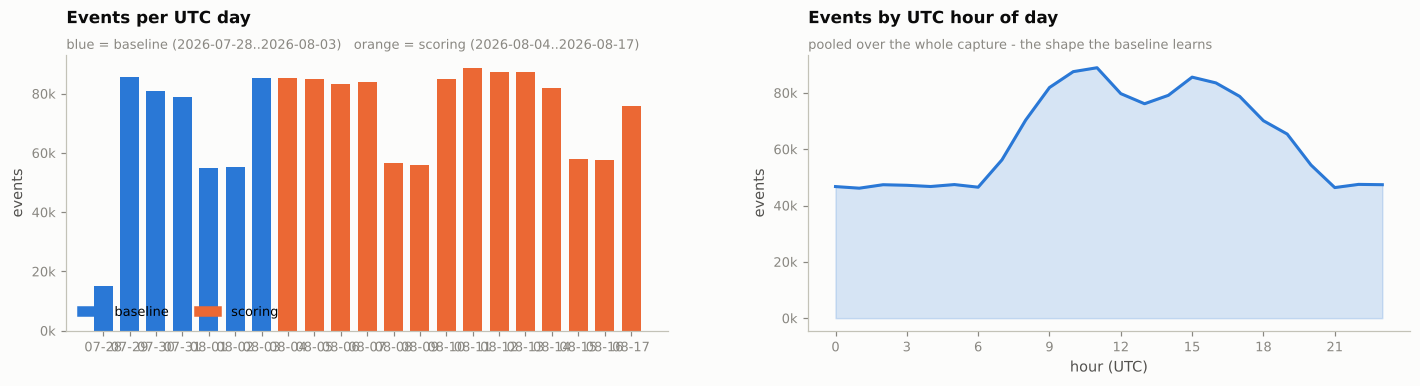

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.6))

ax = axes[0]
days = list(per_day.index)
colors = [CAT[0] if d in TRAIN_DATES else CAT[1] for d in days]
ax.bar(range(len(days)), per_day.values, color=colors, width=0.72)
ax.set_xticks(range(len(days)))
ax.set_xticklabels([d[5:] for d in days], rotation=0)
ax.yaxis.set_major_formatter(mpl.ticker.FuncFormatter(lambda v, p: f"{v/1000:.0f}k"))
finish(ax, "Events per UTC day",
       f"blue = baseline ({TRAIN_DATES[0]}..{TRAIN_DATES[-1]})   "
       f"orange = scoring ({TEST_DATES[0]}..{TEST_DATES[-1]})", ylabel="events")
ax.legend(handles=[Patch(color=CAT[0], label="baseline"), Patch(color=CAT[1], label="scoring")],
          loc="lower left", ncols=2)

ax = axes[1]
hourly = _local.dt.hour.value_counts().sort_index()
ax.fill_between(hourly.index, hourly.values, color=CAT[0], alpha=0.18)
ax.plot(hourly.index, hourly.values, color=CAT[0])
ax.set_xticks(range(0, 24, 3))
ax.yaxis.set_major_formatter(mpl.ticker.FuncFormatter(lambda v, p: f"{v/1000:.0f}k"))
finish(ax, "Events by UTC hour of day", "pooled over the whole capture - the shape the baseline learns",
       xlabel="hour (UTC)", ylabel="events")
plt.tight_layout(); plt.show()

---
## 05. Event ID Analysis

Nothing about the event set is assumed. The table below is generated from the data: for every Event ID
actually present we report its volume, which identity field carries the *actor*, and the attribution
route that will be used in section 07-08.

The "actor" choice is deliberate and follows Windows semantics:

* **`TargetUserName`** is the actor for authentication events (`4624/4625/4634/4768/4769/4771/4776/4800/4801`) -
  the account that logged on, failed to log on, or was targeted by a ticket request.
* **`SubjectUserName`** is the actor for events performed *by* a session
  (`4688/4689/4672/4648/4720/4728/4697/4698/1102` ...).
* **`User` / `SourceUser`** is the actor for Sysmon.
* `5156` carries **no** identity field at all and must be correlated (section 08).

In [6]:
SECURITY_ACTOR_FIELD = {
    4624: "TargetUserName", 4625: "TargetUserName", 4634: "TargetUserName", 4647: "TargetUserName",
    4768: "TargetUserName", 4769: "TargetUserName", 4770: "TargetUserName", 4771: "TargetUserName",
    4776: "TargetUserName", 4800: "TargetUserName", 4801: "TargetUserName",
    4688: "SubjectUserName", 4689: "SubjectUserName", 4672: "SubjectUserName",
    4648: "SubjectUserName", 4720: "SubjectUserName", 4722: "SubjectUserName",
    4724: "SubjectUserName", 4726: "SubjectUserName", 4738: "SubjectUserName",
    4740: "SubjectUserName", 4728: "SubjectUserName", 4732: "SubjectUserName",
    4756: "SubjectUserName", 4697: "SubjectUserName", 4698: "SubjectUserName",
    1102: "SubjectUserName",
}
SYSMON_ACTOR_FIELD = {
    1: "User", 2: "User", 3: "User", 5: "User", 6: "User", 7: "User", 11: "User", 12: "User",
    13: "User", 14: "User", 15: "User", 17: "User", 18: "User", 22: "User", 23: "User", 25: "User",
    8: "SourceUser", 10: "SourceUser",
}
EVENT_MEANING = {
    1: "Sysmon process create", 3: "Sysmon network connection", 5: "Sysmon process terminated",
    7: "Sysmon image loaded", 8: "Sysmon CreateRemoteThread", 10: "Sysmon process access",
    11: "Sysmon file create", 13: "Sysmon registry value set", 22: "Sysmon DNS query",
    1102: "Security log cleared", 4624: "Logon success", 4625: "Logon failure",
    4634: "Logoff", 4648: "Logon with explicit credentials", 4672: "Special privileges assigned",
    4688: "Process creation", 4689: "Process exit", 4697: "Service installed",
    4698: "Scheduled task created", 4720: "User account created", 4724: "Password reset attempt",
    4728: "Member added to global group", 4738: "User account changed",
    4768: "Kerberos TGT requested", 4769: "Kerberos service ticket requested",
    4770: "Kerberos ticket renewed", 4771: "Kerberos pre-auth failed",
    4776: "NTLM credential validation", 4800: "Workstation locked", 4801: "Workstation unlocked",
    5156: "Filtering platform allowed a connection",
}

rows = []
for eid, n in raw.EventID.value_counts().items():
    sub = raw[raw.EventID == eid]
    ch = sub.Channel.iloc[0]
    if eid in SYSMON_ACTOR_FIELD:
        fld, route = SYSMON_ACTOR_FIELD[eid], "direct (Sysmon)"
    elif eid in SECURITY_ACTOR_FIELD:
        fld, route = SECURITY_ACTOR_FIELD[eid], "direct (Security)"
    elif eid == 5156:
        fld, route = "-", "correlated (PID + host + time)"
    else:
        fld, route = "-", "NOT ATTRIBUTABLE"
    cov = f"{sub[fld].notna().mean():.0%}" if fld in sub.columns and fld != "-" else "-"
    rows.append({"event_id": eid, "channel": "Sysmon" if "Sysmon" in str(ch) else "Security",
                 "count": n, "pct": n / n_events, "actor_field": fld, "field_coverage": cov,
                 "attribution": route, "meaning": EVENT_MEANING.get(eid, "?")})

event_catalog = pd.DataFrame(rows).sort_values("count", ascending=False).reset_index(drop=True)
event_catalog["pct"] = event_catalog["pct"].map(lambda v: f"{v:.2%}")
event_catalog["count"] = event_catalog["count"].map(lambda v: f"{v:,}")
event_catalog

,event_id,channel,count,pct,actor_field,field_coverage,attribution,meaning
0,5156,Security,"652,912",42.76%,-,-,correlated (PID + host + time),Filtering platform allowed a connection
1,4769,Security,"110,081",7.21%,TargetUserName,100%,direct (Security),Kerberos service ticket requested
2,22,Sysmon,"101,794",6.67%,User,100%,direct (Sysmon),Sysmon DNS query
3,4624,Security,"83,476",5.47%,TargetUserName,100%,direct (Security),Logon success
4,4688,Security,"76,561",5.01%,SubjectUserName,100%,direct (Security),Process creation
5,1,Sysmon,"76,561",5.01%,User,100%,direct (Sysmon),Sysmon process create
6,5,Sysmon,"76,200",4.99%,User,100%,direct (Sysmon),Sysmon process terminated
7,4689,Security,"74,142",4.86%,SubjectUserName,100%,direct (Security),Process exit
8,10,Sysmon,"57,713",3.78%,SourceUser,100%,direct (Sysmon),Sysmon process access
9,4768,Security,"55,178",3.61%,TargetUserName,100%,direct (Security),Kerberos TGT requested


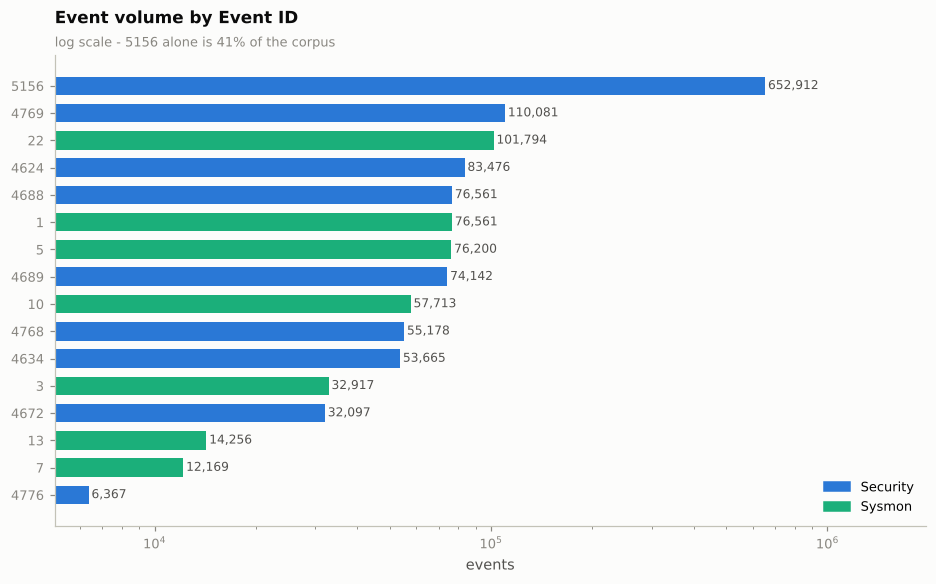

In [7]:
top = raw.EventID.value_counts().head(16).sort_values()
fig, ax = plt.subplots(figsize=(8.6, 5.4))
is_sysmon = [("Sysmon" in str(raw[raw.EventID == e].Channel.iloc[0])) for e in top.index]
ax.barh([str(e) for e in top.index], top.values,
        color=[CAT[2] if s else CAT[0] for s in is_sysmon], height=0.68)
for y, (e, v) in enumerate(top.items()):
    ax.text(v * 1.02, y, f"{v:,}", va="center", fontsize=8, color=INK2)
ax.set_xscale("log"); ax.set_xlim(right=top.max() * 3)
finish(ax, "Event volume by Event ID", "log scale - 5156 alone is 41% of the corpus",
       xlabel="events", xgrid=True)
ax.legend(handles=[Patch(color=CAT[0], label="Security"), Patch(color=CAT[2], label="Sysmon")],
          loc="lower right")
plt.tight_layout(); plt.show()

---
## 06. Timestamp Normalisation & Capture Coverage

Every event gets a UTC date, a UTC hour-of-day and its 10-minute window start. No conversion is applied -
the source timestamps are already UTC.

The second half of this section measures **capture coverage**. The configured period is 13 calendar days,
but the sensor only produced data for 12 x 24 hours of it: the log opens partway through the first day and
closes partway through the last. Those uncovered windows are identified here so that later stages can tell
"the sensor was not running" apart from "the user was idle".

In [8]:
# The source column is already tz-aware UTC; ts_utc and ts are the same clock and are kept
# as two names only so that downstream code reads unambiguously.
raw["ts_utc"] = raw["timestamp"]
raw["ts"]     = raw["ts_utc"]
raw["date"]   = raw["ts"].dt.strftime("%Y-%m-%d")     # UTC calendar date
raw["hour"]   = raw["ts"].dt.hour                     # UTC hour of day, 0..23
raw["win"]    = raw["ts"].dt.floor(WINDOW)            # start of the 10-minute window

observed_days = sorted(raw.date.unique())
print(f"UTC days observed   : {len(observed_days)}  ({observed_days[0]} .. {observed_days[-1]})")
print(f"configured days     : {len(ALL_DATES)}  ({ALL_DATES[0]} .. {ALL_DATES[-1]})")
assert set(observed_days) <= set(ALL_DATES), "events exist outside the configured date range"
print(f"first event (UTC)   : {raw.ts.min()}")
print(f"last  event (UTC)   : {raw.ts.max()}")

# ---- capture coverage -------------------------------------------------------------
# Anything before the first event or after the last one is "sensor not running", not "quiet user".
CAPTURE_START = raw.ts.min().floor(WINDOW)
CAPTURE_END   = raw.ts.max().floor(WINDOW) + pd.Timedelta(WINDOW)
total_windows = len(ALL_DATES) * WINDOWS_PER_DAY
covered = int(((pd.date_range(pd.Timestamp(ALL_DATES[0] + " 00:00", tz=TZ),
                              pd.Timestamp(ALL_DATES[-1] + " 23:50", tz=TZ),
                              freq=WINDOW, tz=TZ) >= CAPTURE_START) &
               (pd.date_range(pd.Timestamp(ALL_DATES[0] + " 00:00", tz=TZ),
                              pd.Timestamp(ALL_DATES[-1] + " 23:50", tz=TZ),
                              freq=WINDOW, tz=TZ) < CAPTURE_END)).sum())
print()
print("CAPTURE COVERAGE")
print(f"  sensor active from  : {CAPTURE_START}  to  {CAPTURE_END}")
print(f"  windows in the configured range : {total_windows:,}")
print(f"  windows with sensor coverage    : {covered:,}")
print(f"  windows WITHOUT coverage        : {total_windows - covered:,}  "
      f"({(total_windows - covered) / total_windows:.1%})")
print()
print("  WARNING: the configured period spans 13 calendar days but the sensor only covers")
print(f"  {covered / WINDOWS_PER_DAY:.2f} days of it. {ALL_DATES[0]} starts at "
      f"{CAPTURE_START:%H:%M} and {ALL_DATES[-1]} ends at {CAPTURE_END:%H:%M}, so UTC hours")
print("  00-17 receive one fewer baseline day than hours 19-23. Section 10 reports the exact")
print("  observation count per user x hour cell rather than assuming a flat 42.")
print()
print(f"distinct 10-min windows populated by at least one event: {raw.win.nunique():,}")
dup = raw.duplicated(subset=["EventRecordID", "Computer", "EventID", "ts_utc"]).sum()
print(f"exact duplicate records (EventRecordID+host+id+time)   : {dup}")

UTC days observed   : 21  (2026-07-28 .. 2026-08-17)
configured days     : 21  (2026-07-28 .. 2026-08-17)
first event (UTC)   : 2026-07-28 18:30:05.382551+00:00
last  event (UTC)   : 2026-08-17 18:29:45.290618+00:00

CAPTURE COVERAGE
  sensor active from  : 2026-07-28 18:30:00+00:00  to  2026-08-17 18:30:00+00:00
  windows in the configured range : 3,024
  windows with sensor coverage    : 2,880
  windows WITHOUT coverage        : 144  (4.8%)

  20.00 days of it. 2026-07-28 starts at 18:30 and 2026-08-17 ends at 18:30, so UTC hours
  00-17 receive one fewer baseline day than hours 19-23. Section 10 reports the exact
  observation count per user x hour cell rather than assuming a flat 42.

distinct 10-min windows populated by at least one event: 2,880


exact duplicate records (EventRecordID+host+id+time)   : 0


---
## 07. User Identification

Attribution runs in tiers, most-reliable first. A later tier never overwrites an earlier one.

| Tier | Rule | Confidence |
|---|---|---|
| **A1** | Sysmon event carries `User` (or `SourceUser` for 8/10) | high - the sensor resolved the token owner |
| **A2** | Security event carries the actor field from the section-05 map | high - written by LSASS |
| **B**  | Security 5156 matched to a Sysmon process by `(Computer, PID)` with the event time inside the process lifetime | medium - see section 08 for the validation |
| **C**  | everything else | **not attributed - excluded from all baselines** |

Domain prefixes (`CORP\`, `NT AUTHORITY\`, ...) are stripped so `CORP\alice.smith` and `alice.smith`
are one principal.

In [9]:
def strip_domain(s):
    s = s.astype("string")
    s = s.str.replace(r"^(CORP|CORP\.LOCAL|NT AUTHORITY|NT SERVICE|BUILTIN|Window Manager|"
                      r"Font Driver Host)\\", "", regex=True, case=False)
    return s.str.strip()


raw["attr_user"]   = pd.NA
raw["attr_method"] = pd.NA

# --- Tier A1: Sysmon direct identity ---------------------------------------------
for eid, fld in SYSMON_ACTOR_FIELD.items():
    if fld not in raw.columns:
        continue
    m = (raw.EventID == eid) & raw[fld].notna()
    if m.any():
        raw.loc[m, "attr_user"]   = raw.loc[m, fld]
        raw.loc[m, "attr_method"] = "A1_sysmon_" + fld

# --- Tier A2: Security direct identity -------------------------------------------
for eid, fld in SECURITY_ACTOR_FIELD.items():
    if fld not in raw.columns:
        continue
    m = (raw.EventID == eid) & raw[fld].notna() & (raw[fld] != "-")
    if m.any():
        raw.loc[m, "attr_user"]   = raw.loc[m, fld]
        raw.loc[m, "attr_method"] = "A2_security_" + fld

raw["attr_user"] = strip_domain(raw["attr_user"])

covered = raw.attr_user.notna()
print(f"tier A (direct identity): {covered.sum():,} / {len(raw):,}  ({covered.mean():.1%})")
print()
print(raw.attr_method.value_counts().to_string())
print()
print("distinct principal strings seen so far:", raw.attr_user.nunique())

tier A (direct identity): 873,945 / 1,526,857  (57.2%)

attr_method
A1_sysmon_User                 315445
A2_security_TargetUserName     311908
A2_security_SubjectUserName    188044
A1_sysmon_SourceUser            58548

distinct principal strings seen so far: 28


### 7.3 ProcessGuid fallback for Sysmon events without a native User field

Tier A1 above trusts each Sysmon EventID's own actor field directly (`User` or `SourceUser`). In **this**
dataset that field is 100% populated on every sampled Sysmon EventID (see the coverage table in section
06/8.3) — but that is a property of how this particular capture was generated, not a guarantee real Sysmon
deployments make. In genuine production Sysmon logs, EventIDs 5 (process terminate), 7 (image load), 8
(CreateRemoteThread) and 13 (registry) typically do **not** carry a native `User` field — only 1, 3, 10, 11
and 22 reliably do. Relying on direct-field presence alone is fragile if this pipeline is ever pointed at
real logs instead of this capture.

The fix: every Sysmon event also carries a `ProcessGuid` (or, for 8/10, a *source* process GUID) tying it
back to the Sysmon Event 1 that created that exact process. Unlike a raw PID, a ProcessGuid is **globally
unique** — Sysmon constructs it from the host, PID and process-creation time together, so it never repeats
and never needs the interval/time-bounding that the 5156 correlation (section 8.2) needs for a PID. This
makes it a plain, safe dictionary lookup: build `ProcessGuid -> attr_user` from every Sysmon Event 1 row
that already has a trusted actor, then fill in any Sysmon event whose own direct field came back empty.

On this dataset this tier should attribute close to nothing new (direct coverage is already 100%) — the
count printed below is the honest measure of that, not a target to hit. It exists so the notebook still
produces valid attribution if run against a real Sysmon deployment where the direct field is sparse.

In [10]:
# ---- 7.3 Tier A1b: ProcessGuid fallback for Sysmon events missing a direct actor field ----
# Field name for the process-identifying GUID differs for the two "two-actor" event types
# (8 = CreateRemoteThread, 10 = ProcessAccess use a SOURCE process guid; everything else uses
# the plain ProcessGuid). Try the real column name for each, skip gracefully if absent.
SYSMON_GUID_FIELD = {eid: "ProcessGuid" for eid in SYSMON_ACTOR_FIELD}
for eid in (8, 10):
    for cand in ("SourceProcessGUID", "SourceProcessGuid"):
        if cand in raw.columns:
            SYSMON_GUID_FIELD[eid] = cand
            break

# Anchors: Sysmon Event 1 rows that already have a trusted attr_user (Tier A1 direct field).
anchors = raw[(raw.EventID == 1) & raw.attr_user.notna() & raw.ProcessGuid.notna()]
guid_to_user = dict(zip(anchors.ProcessGuid, anchors.attr_user))
print(f"ProcessGuid -> user lookup built from {len(guid_to_user):,} anchored Sysmon Event 1 rows.")

n_fixed = 0
for eid, guid_field in SYSMON_GUID_FIELD.items():
    if guid_field not in raw.columns:
        continue
    m = (raw.EventID == eid) & raw.attr_user.isna() & raw[guid_field].notna()
    if not m.any():
        continue
    fallback_user = raw.loc[m, guid_field].map(guid_to_user)
    hit = fallback_user.notna()
    if hit.any():
        idx = raw.loc[m].index[hit]
        raw.loc[idx, "attr_user"] = fallback_user[hit].values
        raw.loc[idx, "attr_method"] = f"A1b_sysmon_processguid_fallback_eid{eid}"
        n_fixed += int(hit.sum())

raw["attr_user"] = strip_domain(raw["attr_user"])  # re-normalize after any new fills
print(f"Sysmon events recovered via ProcessGuid fallback (direct field was empty): {n_fixed:,}")
print(f"Tier A (direct + ProcessGuid fallback) coverage now: "
      f"{raw.attr_user.notna().sum():,} / {len(raw):,}  ({raw.attr_user.notna().mean():.1%})")

ProcessGuid -> user lookup built from 76,561 anchored Sysmon Event 1 rows.


Sysmon events recovered via ProcessGuid fallback (direct field was empty): 0
Tier A (direct + ProcessGuid fallback) coverage now: 873,945 / 1,526,857  (57.2%)


---
## 08. Security / Sysmon Correlation

### 8.1 The logon-session table (Security 4624)

The prompt asks for a `Username + LogonId + Computer + Timestamp` session map, and for Sysmon Event 1 to be
tied back to it through `LogonId + Computer + time`. We build that map - and then we **validate** it rather
than trusting it: Sysmon Event 1 already carries an independent `User` field, so the two can be compared.
The agreement rate is reported below and is the evidence for how far a LogonId-based join can be trusted
in this dataset.

### 8.2 The process-lifetime table (the route that actually earns its keep)

Sysmon 1 (start) and Sysmon 5 (exit) bound each process's lifetime. Keyed by `(Computer, PID)` that gives an
interval table which can attribute Security **5156** - 41% of the corpus and the only source that records
*which* process opened a connection on the Security channel.

PID reuse is handled by requiring the 5156 timestamp to fall inside the interval; a 5156 whose PID belongs to
a process the sensor never saw start (long-running services present before logging began) is left
unattributed rather than guessed.

In [11]:
# ---- 8.1 logon sessions ----------------------------------------------------------
sess = raw[raw.EventID == 4624][
    ["ts", "Computer", "TargetUserName", "TargetDomainName", "TargetLogonId",
     "LogonType", "LogonGuid", "IpAddress", "WorkstationName", "ProcessName"]].copy()
sess["user"] = strip_domain(sess.TargetUserName)
sess = sess.rename(columns={"TargetLogonId": "logon_id", "ts": "logon_time"})
print(f"logon sessions (4624): {len(sess):,}   distinct LogonIds: {sess.logon_id.nunique():,}")
print(sess.LogonType.value_counts().rename("count").to_frame().T.to_string())

# A LogonId is reused across many 4624 records (0x3e7 is SYSTEM on every host, forever), so the
# session table is first collapsed to one row per (Computer, LogonId) - which also measures how
# often that key is ambiguous, i.e. maps to more than one account.
sess_key = (sess.groupby(["Computer", "logon_id"])
              .agg(n_users=("user", "nunique"), user=("user", "first"),
                   first_logon=("logon_time", "min"), n_logons=("user", "size"))
              .reset_index())
ambiguous = int((sess_key.n_users > 1).sum())
print(f"\ndistinct (Computer, LogonId) session keys: {len(sess_key):,}")
print(f"  keys that map to more than one account  : {ambiguous} "
      f"({ambiguous / len(sess_key):.2%})  <- the ceiling on this correlation's precision")

# ---- validate a LogonId-based join against Sysmon-1's own User field -------------
s1 = raw[raw.EventID == 1][["ts", "Computer", "LogonId", "User", "ProcessGuid"]].copy()
s1["user_direct"] = strip_domain(s1.User)
j = s1.merge(sess_key[["Computer", "logon_id", "user", "first_logon", "n_users"]],
             left_on=["Computer", "LogonId"], right_on=["Computer", "logon_id"], how="left")
j = j[j.user.notna() & (j.first_logon <= j.ts)]     # the session must precede the process
agree = (j.user == j.user_direct).mean()
print()
print("VALIDATION of the LogonId + Computer + time correlation, against Sysmon-1's own User field")
print(f"  Sysmon-1 events joinable to a 4624 session : {len(j):,} / {len(s1):,} "
      f"({len(j) / len(s1):.1%})")
print(f"  agreement with the direct User field       : {agree:.2%}")
print(f"  disagreements                              : {int((j.user != j.user_direct).sum()):,}")
print("  -> the correlation is sound, but the direct User field is present on 100% of Sysmon")
print("     events and is strictly better, so it is preferred for attribution. The session table")
print("     is retained for authentication features (source IP, logon type, workstation).")
del s1, j

logon sessions (4624): 83,476   distinct LogonIds: 53,737
LogonType      3      5    10     2    7  11  8
count      50943  29542  1646  1140  200   4  1

distinct (Computer, LogonId) session keys: 53,770
  keys that map to more than one account  : 0 (0.00%)  <- the ceiling on this correlation's precision



VALIDATION of the LogonId + Computer + time correlation, against Sysmon-1's own User field
  Sysmon-1 events joinable to a 4624 session : 76,211 / 76,561 (99.5%)
  agreement with the direct User field       : 100.00%
  disagreements                              : 0
  -> the correlation is sound, but the direct User field is present on 100% of Sysmon
     events and is strictly better, so it is preferred for attribution. The session table
     is retained for authentication features (source IP, logon type, workstation).


In [12]:
# ---- 8.2 process-lifetime table --------------------------------------------------
starts = raw[raw.EventID == 1][["ts_utc", "Computer", "ProcessId", "ProcessGuid",
                                "Image", "attr_user"]].copy()
ends = raw[raw.EventID == 5][["ts_utc", "ProcessGuid"]].rename(columns={"ts_utc": "proc_end"})
proc = starts.merge(ends, on="ProcessGuid", how="left")
n_open = int(proc.proc_end.isna().sum())
proc["proc_end"] = proc.proc_end.fillna(raw.ts_utc.max() + pd.Timedelta("1h"))
proc["pid"] = pd.to_numeric(proc.ProcessId, errors="coerce")
proc = proc.dropna(subset=["pid"])
proc["pid"] = proc.pid.astype("int64")
proc["key"] = proc.Computer.astype(str) + "|" + proc.pid.astype(str)
proc = proc.sort_values("ts_utc")
print(f"process lifetime rows: {len(proc):,}  ({n_open:,} still running at end of capture)")

lifetimes = {k: g[["ts_utc", "proc_end", "attr_user", "Image"]].to_numpy()
             for k, g in proc.groupby("key")}

fw_idx = raw.index[raw.EventID == 5156]
fw_pid = pd.to_numeric(raw.loc[fw_idx, "ProcessID"], errors="coerce")
fw_key = raw.loc[fw_idx, "Computer"].astype(str) + "|" + fw_pid.astype("Int64").astype(str)
fw_ts  = raw.loc[fw_idx, "ts_utc"].to_numpy()

res_u, res_img = [], []
for k, t in zip(fw_key.to_numpy(), fw_ts):
    g = lifetimes.get(k)
    u = im = None
    if g is not None:
        for st, en, us, gim in g:
            if st <= t <= en:
                u, im = us, gim
                break
    res_u.append(u); res_img.append(im)

raw.loc[fw_idx, "attr_user"]   = pd.array(res_u, dtype="string")
raw.loc[fw_idx, "attr_method"] = np.where(pd.notna(res_u), "B_5156_proc_lifetime", pd.NA)
raw.loc[fw_idx, "Image"]       = pd.array(res_img, dtype="string")

n_fw = len(fw_idx); n_ok = int(pd.notna(res_u).sum())
print(f"5156 events attributed via process lifetime: {n_ok:,} / {n_fw:,}  ({n_ok/n_fw:.1%})")

process lifetime rows: 76,561  (561 still running at end of capture)


5156 events attributed via process lifetime: 48,445 / 652,912  (7.4%)


In [13]:
# ---- 8.3 Tier D: DNS made by the Windows resolver service on a single-user workstation ----------
# Windows resolves names for user programs inside svchost.exe running as LOCAL/NETWORK SERVICE, so the
# DNS event carries a service account, not the person. On a workstation one person uses, those lookups
# are that person's. Owner = the person starting >= OWNER_SHARE of user processes on the host, measured
# on the TRAINING days only. Shared servers (DC, file, SQL) have no such owner and are left untouched.
DNS_HOST_OWNER = False         # tested on days20: +1 TP but +11 FP (new benign domains) - off by default
OWNER_SHARE = 0.60
_SVC = {"LOCAL SERVICE", "NETWORK SERVICE"}
_NON_PERSON = {"SYSTEM", "LOCAL SERVICE", "NETWORK SERVICE", "ANONYMOUS LOGON", "DWM-1", "UMFD-0", "UMFD-1"}
_host = raw.Computer.astype("string").str.split(".").str[0]
_ptr = raw[(raw.EventID == 1) & raw.attr_user.notna() & raw.ts_utc.dt.strftime("%Y-%m-%d").isin(TRAIN_DATES)]
_ptr = _ptr[~_ptr.attr_user.isin(_NON_PERSON) & ~_ptr.attr_user.astype(str).str.endswith("$")]
_share = (_ptr.groupby([_host.loc[_ptr.index], _ptr.attr_user]).size()
          .groupby(level=0, group_keys=False).apply(lambda s: s / s.sum()))
HOST_OWNER = {h: u for (h, u), sh in _share.items() if sh >= OWNER_SHARE}
print("workstation owners (training days):", HOST_OWNER)
if DNS_HOST_OWNER:
    _m = (raw.EventID == 22) & raw.attr_user.isin(_SVC) & _host.isin(list(HOST_OWNER))
    raw.loc[_m, "attr_user"] = _host[_m].map(HOST_OWNER).astype("string")
    raw.loc[_m, "attr_method"] = "D_dns_workstation_owner"
    print(f"resolver DNS events attributed to the workstation owner: {int(_m.sum()):,}")


workstation owners (training days): {'PC-001': 'ananya.sharma', 'PC-002': 'rohan.mehta', 'PC-003': 'arjun.iyer', 'PC-004': 'kavya.reddy', 'PC-005': 'rahul.verma', 'PC-006': 'vikram.nair', 'PC-007': 'priya.menon', 'PC-008': 'sneha.patel'}


### 8.3 Attribution report and the events that could **not** be attributed

Everything that follows is driven by this table. Read the warnings - they are the honest limits of the
system, not footnotes.

In [14]:
raw["attr_method"] = raw.attr_method.fillna("C_unattributed")
report = (raw.groupby("attr_method")
             .agg(events=("EventID", "size"),
                  event_ids=("EventID", lambda s: ", ".join(map(str, sorted(s.unique())[:12]))))
             .sort_values("events", ascending=False))
report["pct"] = (report.events / len(raw)).map(lambda v: f"{v:.1%}")
display(report[["events", "pct", "event_ids"]])

un = raw[raw.attr_method == "C_unattributed"]
print()
print("=" * 88)
print("WARNINGS - events that cannot be confidently attributed (excluded from every baseline)")
print("=" * 88)
for eid, n in un.EventID.value_counts().items():
    ex = un[un.EventID == eid]
    why = ("no identity field on the event AND the owning PID belongs to a process the Sysmon "
           "sensor never saw start (long-running service)" if eid == 5156 else
           "no usable actor field present")
    print(f"\nEventID {eid} - {n:,} events ({EVENT_MEANING.get(eid,'?')})")
    print(textwrap.fill(f"reason: {why}", 86, initial_indent="  ", subsequent_indent="          "))
    if eid == 5156:
        apps = ex.Application.fillna("-").str.rsplit(BS, n=1).str[-1].value_counts().head(5)
        print("  dominant applications: " + ", ".join(f"{k} ({v:,})" for k, v in apps.items()))
        print("  impact: these are almost entirely lsass/svchost/dns/System traffic, i.e. machine")
        print(f"          rather than user behaviour. All {n_ok:,} connections opened by a process the")
        print("          Sysmon sensor did observe were attributed successfully.")

,events,pct,event_ids
attr_method,,,
C_unattributed,604467,39.6%,5156
A1_sysmon_User,315445,20.7%,"1, 3, 5, 7, 11, 13, 22"
A2_security_TargetUserName,311908,20.4%,"4624, 4625, 4634, 4768, 4769, 4770, 4771, 4776, 4800, 4801"
A2_security_SubjectUserName,188044,12.3%,"1102, 4648, 4672, 4688, 4689, 4697, 4698, 4720, 4724, 4728, 4738"
A1_sysmon_SourceUser,58548,3.8%,"8, 10"
B_5156_proc_lifetime,48445,3.2%,5156



WARNINGS - events that cannot be confidently attributed (excluded from every baseline)

EventID 5156 - 604,467 events (Filtering platform allowed a connection)
  reason: no identity field on the event AND the owning PID belongs to a process the
          Sysmon sensor never saw start (long-running service)


  dominant applications: lsass.exe (269,857), svchost.exe (134,407), dns.exe (96,361), System (94,492), chrome.exe (6,045)
  impact: these are almost entirely lsass/svchost/dns/System traffic, i.e. machine
          rather than user behaviour. All 48,445 connections opened by a process the
          Sysmon sensor did observe were attributed successfully.


---
## 09. Data Cleaning & Principal Scoping

Not every attributed string is a *person-like* principal worth baselining. Machine accounts (`PC-003$`),
built-in service identities (`SYSTEM`, `LOCAL SERVICE`, `NETWORK SERVICE`), and `ANONYMOUS LOGON` produce
enormous, machine-driven volumes that would swamp the user model and generate noise alerts.

They are **kept in the event table** (so they can be inspected) but are **not scored**. The exclusion is
listed explicitly below rather than being applied silently.

A second filter removes principals whose 7 baseline days contain too few events to support 24 hourly
profiles - scoring them would be scoring noise.

In [15]:
BUILTIN = {"SYSTEM", "LOCAL SERVICE", "NETWORK SERVICE", "ANONYMOUS LOGON", "-",
           "IUSR", "MSSQLSERVER"}


def is_person_like(u):
    if pd.isna(u):
        return False
    u = str(u)
    if u in BUILTIN or u.endswith("$") or u.startswith("DWM-") or u.startswith("UMFD-"):
        return False
    return True


raw["in_scope"] = raw.attr_user.map(is_person_like)
scoped_all = raw[raw.in_scope]
tr_counts = scoped_all[scoped_all.date.isin(TRAIN_DATES)].groupby("attr_user").size()
PRINCIPALS = sorted(tr_counts[tr_counts >= MIN_TRAIN_EVENTS].index)
LOW_DATA = sorted(set(scoped_all.attr_user.unique()) - set(PRINCIPALS))

excluded = raw[raw.attr_user.notna() & ~raw.in_scope].attr_user.value_counts()
print("excluded non-person principals (kept in the event table, never scored)")
for u, n in excluded.head(14).items():
    print(f"  {u:22s} {n:>8,}")
print()
print(f"BASELINED PRINCIPALS ({len(PRINCIPALS)}):")
for u in PRINCIPALS:
    print(f"  {u:16s} {tr_counts[u]:>6,} training events")
print()
print("WARNING - principals with insufficient baseline data (reported, not scored):")
for u in LOW_DATA:
    n = int(tr_counts.get(u, 0))
    tot = int((scoped_all.attr_user == u).sum())
    print(f"  {u:16s} {n:>4} training events / {tot:>4} total  -> no reliable user x hour baseline")
print()
print("  These are stale or service accounts that appear almost exclusively as failed-authentication")
print("  targets. Activity from them is surfaced in the section-22 'unbaselined principals' table")
print("  instead of being forced into a model that cannot support it.")

excluded non-person principals (kept in the event table, never scored)
  SYSTEM                  331,232
  NETWORK SERVICE          66,720
  LOCAL SERVICE            57,189
  FILE-01$                 31,785
  ANONYMOUS LOGON          27,270
  SQL-01$                  25,603
  APP-01$                  20,355
  PC-007$                  17,657
  PC-005$                  17,528
  PC-004$                  16,748
  PC-008$                  16,476
  PC-002$                  15,763
  PC-003$                  15,617
  PC-001$                  15,611

BASELINED PRINCIPALS (8):
  ananya.sharma     5,344 training events
  arjun.iyer        8,293 training events
  kavya.reddy      11,126 training events
  priya.menon      11,228 training events
  rahul.verma       8,513 training events
  rohan.mehta       4,748 training events
  sneha.patel       7,158 training events
  vikram.nair       4,970 training events

WARNING - principals with insufficient baseline data (reported, not scored):
  meera.josh

### 9.2 The normalised event table

One row per attributed event, with the heterogeneous Security/Sysmon fields folded into a single
behavioural schema. This is the table every later stage reads.

In [16]:
ev = raw[raw.in_scope & raw.attr_user.isin(PRINCIPALS)].copy()
ev["user"] = ev.attr_user.astype(str)


def low(s):  return s.astype("string").str.lower()

# ---- process identity ------------------------------------------------------------
ev["image"] = low(ev["Image"])
# 5156 reports "\device\harddiskvolumeN\..." - fold onto a normal drive path
_DEV_RE = re.compile("^" + re.escape(BS) + "device" + re.escape(BS) +
                     r"harddiskvolume\d+" + re.escape(BS))
_umap = {u: _DEV_RE.sub(lambda m: "c:" + BS, u) for u in ev["image"].dropna().unique()}
ev["image"] = ev["image"].map(_umap).astype("string")
_m810 = ev.EventID.isin([8, 10])
ev.loc[_m810, "image"] = low(ev.loc[_m810, "SourceImage"])
ev["image_base"]   = ev["image"].str.rsplit(BS, n=1).str[-1]
ev["parent_image"] = low(ev["ParentImage"])
ev["parent_base"]  = ev["parent_image"].str.rsplit(BS, n=1).str[-1]
ev["pair"]         = ev["parent_base"].fillna("") + ">" + ev["image_base"].fillna("")
ev["cmd_low"]      = low(ev["CommandLine"])

# ---- network ---------------------------------------------------------------------
ev["dst_ip"]   = ev["DestinationIp"].astype("string")
ev["dst_port"] = pd.to_numeric(ev["DestinationPort"], errors="coerce")
_m5156 = ev.EventID == 5156
ev.loc[_m5156, "dst_ip"]   = ev.loc[_m5156, "DestAddress"].astype("string")
ev.loc[_m5156, "dst_port"] = pd.to_numeric(ev.loc[_m5156, "DestPort"], errors="coerce")

# ---- authentication ---------------------------------------------------------------
def clean_ip(s):
    s = s.astype("string").str.replace("::ffff:", "", regex=False)
    return s.where(~s.isin(["-", "::1", "127.0.0.1", "0.0.0.0"]), pd.NA)

ev["src_ip"]      = clean_ip(ev["IpAddress"])
ev["logon_type"]  = pd.to_numeric(ev["LogonType"], errors="coerce")
ev["workstation"] = ev["WorkstationName"].astype("string").where(lambda s: s != "-", pd.NA)
ev["computer"]    = ev["Computer"].astype("string").str.split(".").str[0]

# ---- DNS --------------------------------------------------------------------------
ev["domain"] = low(ev["QueryName"])

def registrable(d):
    """Reverse-lookup PTRs are per-connection noise; everything else folds to eTLD+1-ish."""
    if pd.isna(d):
        return pd.NA
    d = str(d)
    if d.endswith(".in-addr.arpa") or d.endswith(".ip6.arpa"):
        return pd.NA
    p = d.strip(".").split(".")
    if len(p) <= 2:
        return d
    if p[-2] in ("co", "com", "net", "org", "gov", "ac") and len(p[-1]) == 2:
        return ".".join(p[-3:])
    return ".".join(p[-2:])

ev["reg_domain"] = ev["domain"].map(registrable)

# ---- file / registry ---------------------------------------------------------------
ev["target_file"] = low(ev["TargetFilename"])
ev["reg_path"]    = low(ev["TargetObject"])

EVENT_TABLE_COLS = ["ts", "date", "hour", "win", "EventID", "Channel", "computer", "user",
                    "attr_method", "logon_type", "src_ip", "workstation", "image", "parent_image",
                    "cmd_low", "dst_ip", "dst_port", "domain", "reg_domain", "target_file", "reg_path"]
print(f"normalised, attributed event table: {len(ev):,} rows x {ev.shape[1]} columns")
print(ev.groupby("user").size().rename("events").to_frame().T.to_string())
ev[EVENT_TABLE_COLS].head(6)

# example principal used by the illustrative tables below (any scored user works)
EXAMPLE_USER = "arjun.iyer" if "arjun.iyer" in PRINCIPALS else PRINCIPALS[0]


normalised, attributed event table: 232,404 rows x 112 columns
user    ananya.sharma  arjun.iyer  kavya.reddy  priya.menon  rahul.verma  rohan.mehta  sneha.patel  vikram.nair
events          22777       29014        41506        41970        36155        19693        24085        17204


---
## 10. 10-Minute Window Generation

The grid is built by **cross product**, not by grouping the events. Every principal gets every 10-minute
window of every configured UTC day, whether or not anything happened in it:

```
8 principals x 13 days x 144 windows = 14,976 rows
```

Windows with no events keep a full zero feature vector. This is the requirement from section 4 of the brief -
*inactivity is part of the behavioural pattern*, and dropping quiet windows would make "the user was busy at
03:00" indistinguishable from "the user is always busy".

**The one exception** is the windows section 06 flagged as outside the sensor's capture range. A zero there
means "no log was being written", not "the user did nothing", so those rows are marked
`has_telemetry = False` and skipped by the baseline and the scorer. They stay in the frame so the omission
is visible rather than silent.

Because the capture starts at 18:30 on the first configured day, UTC hours 00-17 get one baseline day fewer
than hours 19-23. The table below reports the real observation count for every `user x hour` cell instead of
assuming a flat 42.

In [17]:
# Every 10-minute window of every configured day, for every principal - built by cross
# product so that quiet windows exist by construction and cannot be lost by a groupby.
window_index = pd.date_range(pd.Timestamp(ALL_DATES[0] + " 00:00", tz=TZ),
                             pd.Timestamp(ALL_DATES[-1] + " 23:50", tz=TZ),
                             freq=WINDOW, tz=TZ)
grid = (pd.MultiIndex.from_product([PRINCIPALS, window_index], names=["user", "win"])
          .to_frame(index=False))
grid["date"]          = grid.win.dt.strftime("%Y-%m-%d")   # UTC date
grid["hour"]          = grid.win.dt.hour                   # UTC hour 0..23
grid["slot"]          = grid.win.dt.minute // 10           # which of the 6 windows in the hour
grid["is_train"]      = grid.date.isin(TRAIN_DATES)
grid["has_telemetry"] = ((grid.win >= CAPTURE_START) & (grid.win < CAPTURE_END)).astype(bool)
# coarse temporal context only; the behavioural baseline remains user x hour
grid["day_type"]      = np.where(grid.win.dt.tz_convert(DAYTYPE_TZ).dt.dayofweek >= 5, "weekend", "weekday")

print(f"grid: {len(grid):,} rows = {len(PRINCIPALS)} principals "
      f"x {len(ALL_DATES)} days x {WINDOWS_PER_DAY} windows")

# structural check: 6 windows in every hour of every day, always
chk = grid.groupby(["user", "date", "hour"]).size()
assert chk.eq(WINDOWS_PER_HOUR).all(), "every user-day-hour must contain exactly 6 windows"
print(f"windows per user-day-hour : {sorted(int(v) for v in chk.unique())}  (required: [{WINDOWS_PER_HOUR}])")

n_cov = int(grid.has_telemetry.sum())
print(f"windows with sensor coverage : {n_cov:,}  "
      f"({n_cov / len(grid):.1%});  without: {len(grid) - n_cov:,}")

# how many usable baseline observations each user x hour cell actually has
obs = (grid[grid.is_train & grid.has_telemetry]
       .groupby(["user", "hour"]).size().rename("n_obs").reset_index())
print(f"user x hour baseline cells   : {len(obs)} (= {len(PRINCIPALS)} users x 24 hours)")
print(f"observations per cell        : {sorted(int(v) for v in obs.n_obs.unique())}")
print()
print("OBSERVATIONS PER user x hour BASELINE CELL (identical for every principal, so one row shown)")
tbl = (obs[obs.user == PRINCIPALS[0]].set_index("hour")[["n_obs"]].T)
tbl.index = ["baseline observations"]
display(tbl)
print("hours 19-23 get all 7 configured days (42 = 6 windows x 7 days);")
print("hours 00-17 get 6 days (36) and hour 18 gets 6 days plus the 3 windows after 18:30 (39),")
print("because the sensor only starts at 18:30 on the first configured day.")

grid: 24,192 rows = 8 principals x 21 days x 144 windows
windows per user-day-hour : [6]  (required: [6])
windows with sensor coverage : 23,040  (95.2%);  without: 1,152
user x hour baseline cells   : 192 (= 8 users x 24 hours)
observations per cell        : [36, 39, 42]

OBSERVATIONS PER user x hour BASELINE CELL (identical for every principal, so one row shown)


hour,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23
baseline observations,36,36,36,36,36,36,36,36,36,36,36,36,36,36,36,36,36,36,39,42,42,42,42,42


hours 19-23 get all 7 configured days (42 = 6 windows x 7 days);
hours 00-17 get 6 days (36) and hour 18 gets 6 days plus the 3 windows after 18:30 (39),
because the sensor only starts at 18:30 on the first configured day.


---
## 11. Feature Engineering

Two products come out of this section.

**(a) 71 numeric window features**, every one of them declared in a single **feature registry** in the next
cell. Each entry states the feature's name, what it measures in plain English, and the exact rule that
computes it. The registry is printed as a table, so there is never a question of where a feature came from.
Adding a feature later means adding one line to that registry - aggregation, validation, the baseline,
scoring and the explanations all read it.

**(b) 11 categorical behaviour dimensions.** Counts alone cannot express *what* a user does. These sets
capture identity: which executables, which parent->child relationships, which invocation styles, which
authentication paths, which destinations.

### The process taxonomy

The tool classes below are generic Windows security knowledge (LOLBins, discovery utilities, admin tooling,
script hosts), not signatures derived from this scenario's ground truth. They give the model a way to say
"this user started running *a class of tool* they never ran before" instead of only "they ran one more
process than usual".

### Command-line signature

For shells and LOLBins, *how* a binary is invoked is behaviour. `powershell.exe -NoProfile -Command ...` and
`powershell.exe -ExecutionPolicy Bypass -File ...` are different habits. The signature keeps the flag
sequence up to the first content-carrying switch and discards all argument values, so it stays stable while
staying discriminative. GUI applications are excluded - their command lines are pure churn (URLs, file paths).

In [18]:
# =====================================================================================
# 11.1  PROCESS TAXONOMY
# Generic Windows security knowledge (LOLBins, discovery utilities, admin tooling,
# script hosts). None of it is derived from this scenario's ground truth.
# =====================================================================================
SHELLS       = {"powershell.exe", "pwsh.exe", "cmd.exe"}
SCRIPT_HOSTS = {"wscript.exe", "cscript.exe", "mshta.exe", "jscript.exe"}
DISCOVERY    = {"whoami.exe", "systeminfo.exe", "net.exe", "net1.exe", "nltest.exe", "dsquery.exe",
                "nbtstat.exe", "arp.exe", "route.exe", "quser.exe", "qwinsta.exe", "tasklist.exe",
                "netstat.exe", "ipconfig.exe", "hostname.exe", "wmic.exe", "setspn.exe", "adfind.exe"}
LOLBIN       = {"certutil.exe", "bitsadmin.exe", "regsvr32.exe", "rundll32.exe", "mshta.exe",
                "installutil.exe", "msbuild.exe", "cmstp.exe", "odbcconf.exe", "wmic.exe",
                "forfiles.exe", "pcalua.exe", "msiexec.exe", "curl.exe", "wget.exe",
                "esentutl.exe", "expand.exe", "extrac32.exe"}
ADMIN_TOOL   = {"sc.exe", "schtasks.exe", "at.exe", "reg.exe", "wevtutil.exe", "vssadmin.exe",
                "bcdedit.exe", "wbadmin.exe", "netsh.exe", "takeown.exe", "icacls.exe", "cacls.exe",
                "gpupdate.exe", "dsadd.exe", "ntdsutil.exe"}
REMOTE_EXEC  = {"psexec.exe", "psexec64.exe", "paexec.exe", "winrs.exe", "wmic.exe", "mstsc.exe",
                "putty.exe", "ssh.exe", "plink.exe"}
TRANSFER     = {"robocopy.exe", "xcopy.exe", "certutil.exe", "curl.exe", "wget.exe", "ftp.exe",
                "7z.exe", "winrar.exe", "rar.exe", "makecab.exe"}
SCRIPT_LOLBIN  = SHELLS | SCRIPT_HOSTS | LOLBIN | DISCOVERY | ADMIN_TOOL | TRANSFER
REMOTE_PARENTS = {"svchost.exe", "services.exe", "wmiprvse.exe", "winrshost.exe",
                  "wsmprovhost.exe", "psexesvc.exe", "taskeng.exe", "schtasks.exe"}

ARCHIVE_EXT = (".zip", ".rar", ".7z", ".tar", ".gz", ".cab", ".b64")
SCRIPT_EXT  = (".ps1", ".vbs", ".js", ".bat", ".cmd", ".hta", ".psm1", ".wsf")
EXE_EXT     = (".exe", ".dll", ".sys", ".scr", ".com")
SENSITIVE_PORTS = {135, 139, 445, 1433, 3306, 5432, 3389, 5985, 5986, 22, 23, 21, 5900}
PRIV_PAT = r"^(10\.|192\.168\.|172\.(1[6-9]|2\d|3[01])\.|169\.254\.|127\.)"

# ---- event-class masks (reused by the registry and by the categorical dimensions) ----
ev["is_proc"]    = ev.EventID == 1            # Sysmon process create
ev["is_net"]     = ev.EventID.isin([3, 5156]) # Sysmon network connect + attributed 5156
ev["is_dns"]     = ev.EventID == 22           # Sysmon DNS query
ev["is_file"]    = ev.EventID == 11           # Sysmon file create
ev["is_reg"]     = ev.EventID.isin([12, 13, 14])
ev["is_imgload"] = ev.EventID == 7
ev["is_pacc"]    = ev.EventID == 10           # Sysmon process access
ev["is_rthread"] = ev.EventID == 8            # Sysmon CreateRemoteThread
ev["f_logon_ok"] = ev.EventID == 4624

# ---- shorthand columns the rules below read -----------------------------------------
ib  = ev["image_base"].fillna("")
pb  = ev["parent_base"].fillna("")
cl  = ev["cmd_low"].fillna("")
tf  = ev["target_file"].fillna("")
rp  = ev["reg_path"].fillna("")
ti  = ev["TargetImage"].fillna("").str.lower()
ALL = pd.Series(True, index=ev.index)
ev["dst_pair"]    = ev["dst_ip"].fillna("") + ":" + ev["dst_port"].astype("Int64").astype("string").fillna("")
ev["dst_port_s"]  = ev["dst_port"].astype("Int64").astype("string")
ev["logon_type_s"] = ev["logon_type"].astype("Int64").astype("string")
is_ext_dst = ev["dst_ip"].notna() & ~ev["dst_ip"].fillna("").str.match(PRIV_PAT)
is_ext_src = ev["src_ip"].notna() & ~ev["src_ip"].fillna("").str.match(PRIV_PAT)
is_sens_pt = ev["dst_port"].isin(SENSITIVE_PORTS)
is_script  = ib.isin(SCRIPT_LOLBIN)

# =====================================================================================
# 11.2  THE FEATURE REGISTRY  <-- this is where every window feature is defined
#
# One line per feature. Nothing is computed anywhere else, and nothing is derived
# from a name prefix, so "where does <feature> come from?" is answered by the table
# printed at the bottom of this cell.
#
#   count(...)  the feature is HOW MANY events in the window match `mask`
#   unique(...) the feature is HOW MANY DISTINCT values of `value` those events show
#
# To add a feature later, add one line here. Aggregation (11.3), validation (12),
# the baseline (14), scoring (16-18) and the explanations (19) all read this registry.
# =====================================================================================
FEATURE_REGISTRY = []


def count(name, group, meaning, how, mask):
    ev["_m_" + name] = mask.fillna(False).to_numpy(dtype=bool)
    FEATURE_REGISTRY.append(dict(feature=name, group=group, meaning=meaning,
                                 computed_from=how, kind="count"))


def unique(name, group, meaning, how, mask, value):
    ev["_m_" + name] = mask.fillna(False).to_numpy(dtype=bool)
    FEATURE_REGISTRY.append(dict(feature=name, group=group, meaning=meaning,
                                 computed_from=how, kind="unique", value=value))


# ---------------------------------------------------------------------- volume -------
count("event_count", "volume", "total events",
      "every attributed event in the window", ALL)

# --------------------------------------------------------------------- process -------
count("proc_count", "process", "process creations", "Sysmon 1", ev.is_proc)
count("ps_count", "process", "PowerShell launches",
      "Sysmon 1, image in {powershell.exe, pwsh.exe}", ev.is_proc & ib.isin({"powershell.exe", "pwsh.exe"}))
count("cmd_count", "process", "cmd.exe launches",
      "Sysmon 1, image = cmd.exe", ev.is_proc & (ib == "cmd.exe"))
count("scripthost_count", "process", "script-host launches",
      "Sysmon 1, image in SCRIPT_HOSTS (wscript/cscript/mshta)", ev.is_proc & ib.isin(SCRIPT_HOSTS))
count("discovery_count", "process", "discovery-tool executions",
      "Sysmon 1, image in DISCOVERY (whoami/net/nltest/systeminfo/wmic/...)",
      ev.is_proc & ib.isin(DISCOVERY))
count("lolbin_count", "process", "LOLBin executions",
      "Sysmon 1, image in LOLBIN (certutil/rundll32/regsvr32/bitsadmin/...)",
      ev.is_proc & ib.isin(LOLBIN))
count("admin_count", "process", "administrative-tool executions",
      "Sysmon 1, image in ADMIN_TOOL (sc/schtasks/reg/wevtutil/vssadmin/...)",
      ev.is_proc & ib.isin(ADMIN_TOOL))
count("remoteexec_count", "process", "remote-execution tool executions",
      "Sysmon 1, image in REMOTE_EXEC (mstsc/psexec/winrs/ssh/...)", ev.is_proc & ib.isin(REMOTE_EXEC))
count("transfer_count", "process", "file-transfer tool executions",
      "Sysmon 1, image in TRANSFER (robocopy/certutil/curl/7z/...)", ev.is_proc & ib.isin(TRANSFER))
count("temp_proc_count", "process", "processes started from a temp/appdata path",
      "Sysmon 1, image path contains \\temp\\ or \\appdata\\",
      ev.is_proc & ev["image"].fillna("").str.contains(
          "(?:" + re.escape(BS) + "temp" + re.escape(BS) + "|" + re.escape(BS) + "appdata" +
          re.escape(BS) + ")", regex=True))
count("encoded_count", "process", "encoded command lines",
      "Sysmon 1, command line matches -enc / encodedcommand / frombase64",
      ev.is_proc & cl.str.contains(r"-enc|frombase64|encodedcommand", regex=True))
count("hidden_ps_count", "process", "PowerShell run with -NoProfile or a hidden window",
      "Sysmon 1, command line matches -noprofile / -nop / -w hidden / -windowstyle hidden",
      ev.is_proc & cl.str.contains(r"-w\s+hidden|-windowstyle\s+hidden|-noprofile|-nop\b", regex=True))
count("remote_spawn_count", "process", "shells spawned by a service/WMI parent (remote execution)",
      "Sysmon 1, parent in REMOTE_PARENTS and image in the script/LOLBin set",
      ev.is_proc & pb.isin(REMOTE_PARENTS) & is_script)
unique("proc_unique", "process", "distinct executables",
       "Sysmon 1, distinct full image path", ev.is_proc, "image")
unique("parent_unique", "process", "distinct parent processes",
       "Sysmon 1, distinct parent image path", ev.is_proc, "parent_image")
unique("pair_unique", "process", "distinct parent->child pairs",
       "Sysmon 1, distinct parent_base>image_base", ev.is_proc, "pair")

# --------------------------------------------------------------------- network -------
count("net_conn_count", "network", "network connections",
      "Sysmon 3 plus Security 5156 attributed by process lifetime", ev.is_net)
count("ext_dst_count", "network", "connections to external (public) addresses",
      "network event whose destination is outside RFC1918", ev.is_net & is_ext_dst)
count("sens_port_count", "network", "connections to infrastructure ports",
      "network event whose destination port is in SENSITIVE_PORTS (445/3389/1433/5985/...)",
      ev.is_net & is_sens_pt)
count("script_net_count", "network", "connections made by a shell or LOLBin",
      "network event whose initiating image is in the script/LOLBin set", ev.is_net & is_script)
count("script_ext_net_count", "network", "shell/LOLBin connections to external addresses",
      "script_net AND destination outside RFC1918", ev.is_net & is_script & is_ext_dst)
count("script_sens_port_count", "network", "shell/LOLBin connections to infrastructure ports",
      "script_net AND destination port in SENSITIVE_PORTS", ev.is_net & is_script & is_sens_pt)
unique("dst_ip_unique", "network", "distinct destination IPs",
       "network events, distinct destination address", ev.is_net, "dst_ip")
unique("dst_port_unique", "network", "distinct destination ports",
       "network events, distinct destination port", ev.is_net, "dst_port")
unique("dst_pair_unique", "network", "distinct destination IP:port pairs",
       "network events, distinct address:port", ev.is_net, "dst_pair")

# ------------------------------------------------------------------------- dns -------
count("dns_count", "dns", "DNS queries", "Sysmon 22", ev.is_dns)
count("srv_lookup_count", "dns", "SRV record lookups",
      "Sysmon 22 where the query name starts with _", ev.is_dns & ev["domain"].fillna("").str.startswith("_"))
count("dns_fail_count", "dns", "DNS queries that failed to resolve",
      "Sysmon 22 with a non-zero QueryStatus",
      ev.is_dns & (pd.to_numeric(ev["QueryStatus"], errors="coerce").fillna(0) != 0))
unique("domain_unique", "dns", "distinct DNS domains",
       "Sysmon 22, distinct registrable domain (PTR lookups excluded)", ev.is_dns, "reg_domain")

# ------------------------------------------------------------------------ file -------
count("file_create_count", "file", "files created", "Sysmon 11", ev.is_file)
count("exe_create_count", "file", "executables or DLLs created",
      "Sysmon 11 with an .exe/.dll/.sys/.scr/.com target", ev.is_file & tf.str.endswith(EXE_EXT))
count("script_create_count", "file", "script files created",
      "Sysmon 11 with a .ps1/.vbs/.js/.bat/.cmd/.hta target", ev.is_file & tf.str.endswith(SCRIPT_EXT))
count("archive_create_count", "file", "archive files created",
      "Sysmon 11 with a .zip/.rar/.7z/.tar/.gz/.cab/.b64 target",
      ev.is_file & tf.str.endswith(ARCHIVE_EXT))
count("temp_create_count", "file", "files created under a temp path",
      "Sysmon 11 whose target path contains \\temp\\",
      ev.is_file & tf.str.contains(re.escape(BS) + "temp" + re.escape(BS), regex=True))

# -------------------------------------------------------------------- registry -------
count("reg_count", "registry", "registry modifications", "Sysmon 12/13/14", ev.is_reg)
count("run_key_count", "registry", "writes to a Run autostart key",
      "Sysmon 12/13/14 whose target path contains CurrentVersion\\Run",
      ev.is_reg & rp.str.contains("currentversion" + re.escape(BS) + "run", regex=True))
count("svc_key_count", "registry", "writes under CurrentControlSet\\Services",
      "Sysmon 12/13/14 whose target path contains CurrentControlSet\\Services",
      ev.is_reg & rp.str.contains("currentcontrolset" + re.escape(BS) + "services", regex=True))
unique("reg_path_unique", "registry", "distinct registry paths written",
       "Sysmon 12/13/14, distinct target object", ev.is_reg, "reg_path")

# ------------------------------------------------------------------- injection -------
count("image_load_count", "injection", "modules loaded by the user's processes",
      "Sysmon 7", ev.is_imgload)
count("proc_access_count", "injection", "process handles opened into another process",
      "Sysmon 10", ev.is_pacc)
count("lsass_acc_count", "injection", "LSASS process accesses",
      "Sysmon 10 whose target image is lsass.exe", ev.is_pacc & ti.str.endswith("lsass.exe"))
count("lsass_hi_count", "injection", "high-privilege LSASS accesses",
      "Sysmon 10 into lsass.exe with a credential-theft GrantedAccess mask",
      ev.is_pacc & ti.str.endswith("lsass.exe") &
      ev["GrantedAccess"].fillna("").isin(["0x1FFFFF", "0x1010", "0x143a", "0x1F3FFF", "0x1410"]))
count("remote_thread_count", "injection", "remote threads created in another process",
      "Sysmon 8", ev.is_rthread)
count("rthread_ext_count", "injection", "remote-thread injections excluding antivirus",
      "Sysmon 8 whose target image is not a Defender component",
      ev.is_rthread & ~ti.str.contains("defender", regex=False))

# -------------------------------------------------------------- authentication -------
count("logon_ok_count", "authentication", "successful logons", "Security 4624", ev.f_logon_ok)
count("logon_fail_count", "authentication", "failed logons", "Security 4625", ev.EventID == 4625)
count("lt2_count", "authentication", "console logons (type 2)",
      "Security 4624 with LogonType 2", ev.f_logon_ok & (ev.logon_type == 2))
count("lt3_count", "authentication", "network logons (type 3)",
      "Security 4624 with LogonType 3", ev.f_logon_ok & (ev.logon_type == 3))
count("lt5_count", "authentication", "service logons (type 5)",
      "Security 4624 with LogonType 5", ev.f_logon_ok & (ev.logon_type == 5))
count("lt10_count", "authentication", "remote-interactive (RDP) logons",
      "Security 4624 with LogonType 10", ev.f_logon_ok & (ev.logon_type == 10))
count("ext_src_count", "authentication", "logons from an external address",
      "Security 4624 whose source IP is outside RFC1918", ev.f_logon_ok & is_ext_src)
count("ext_fail_count", "authentication", "failed logons from an external address",
      "Security 4625 whose source IP is outside RFC1918 (password spray / guessing from the internet)",
      (ev.EventID == 4625) & is_ext_src)
count("priv_count", "authentication", "special-privilege assignments",
      "Security 4672", ev.EventID == 4672)
count("explicit_count", "authentication", "explicit-credential logons",
      "Security 4648 (RunAs)", ev.EventID == 4648)
count("tgt_count", "authentication", "Kerberos TGT requests", "Security 4768", ev.EventID == 4768)
count("tgs_count", "authentication", "Kerberos service-ticket requests",
      "Security 4769", ev.EventID == 4769)
count("krb_fail_count", "authentication", "Kerberos pre-authentication failures",
      "Security 4771", ev.EventID == 4771)
count("ntlm_count", "authentication", "NTLM credential validations", "Security 4776", ev.EventID == 4776)
count("ntlm_fail_count", "authentication", "failed NTLM credential validations",
      "Security 4776 with a non-zero Status",
      (ev.EventID == 4776) & (ev["Status"].astype("string") != "0x0"))
count("logoff_count", "authentication", "logoffs", "Security 4634", ev.EventID == 4634)
count("unlock_count", "authentication", "workstation unlocks", "Security 4801", ev.EventID == 4801)
count("lock_count", "authentication", "workstation locks", "Security 4800", ev.EventID == 4800)
unique("src_ip_unique", "authentication", "distinct authentication source IPs",
       "Security 4624, distinct source address", ev.f_logon_ok, "src_ip")
unique("workstation_unique", "authentication", "distinct workstation names in logons",
       "Security 4624, distinct WorkstationName", ev.f_logon_ok, "workstation")
unique("logon_type_unique", "authentication", "distinct logon types used",
       "Security 4624, distinct LogonType", ev.f_logon_ok, "logon_type")

# ------------------------------------------------------------ directory change -------
count("acct_mgmt_count", "directory change", "account-management operations",
      "Security 4720/4722/4723/4724/4725/4726/4738/4740/4767/4781",
      ev.EventID.isin([4720, 4722, 4723, 4724, 4725, 4726, 4738, 4740, 4767, 4781]))
count("group_mgmt_count", "directory change", "group-membership changes",
      "Security 4727-4757 group add/remove family",
      ev.EventID.isin([4727, 4728, 4729, 4731, 4732, 4733, 4735, 4737, 4754, 4755, 4756, 4757]))
count("svc_install_count", "directory change", "service installations",
      "Security 4697 / 7045", ev.EventID.isin([4697, 7045]))
count("task_count", "directory change", "scheduled-task registrations",
      "Security 4698/4699/4700/4702", ev.EventID.isin([4698, 4699, 4700, 4702]))
count("logclear_count", "directory change", "event-log clears",
      "Security 1102 / 104", ev.EventID.isin([1102, 104]))

# ---------------------------------------------------------------------- spread -------
unique("computer_unique", "spread", "distinct hosts touched",
       "any attributed event, distinct Computer", ALL, "computer")

# ---- derived look-ups, so there is exactly one source of truth for names -------------
FEATS         = [r["feature"] for r in FEATURE_REGISTRY]
FEATURE_TEXT  = {r["feature"]: r["meaning"] for r in FEATURE_REGISTRY}
FEATURE_GROUP = {r["feature"]: r["group"] for r in FEATURE_REGISTRY}
FEATURE_HOW   = {r["feature"]: r["computed_from"] for r in FEATURE_REGISTRY}


def feat_text(f):
    return FEATURE_TEXT.get(f, f.replace("_count", "").replace("_", " "))


assert len(FEATS) == len(set(FEATS)), "duplicate feature name in the registry"
print(f"{len(FEATS)} window features declared "
      f"({sum(r['kind'] == 'count' for r in FEATURE_REGISTRY)} counts, "
      f"{sum(r['kind'] == 'unique' for r in FEATURE_REGISTRY)} distinct-value counts)")
print()
print("THE FEATURE REGISTRY - every window feature, and exactly how it is computed")
with pd.option_context("display.max_rows", 90, "display.max_colwidth", 78):
    display(pd.DataFrame(FEATURE_REGISTRY)[["group", "feature", "kind", "meaning",
                                            "computed_from"]])

72 window features declared (60 counts, 12 distinct-value counts)

THE FEATURE REGISTRY - every window feature, and exactly how it is computed


,group,feature,kind,meaning,computed_from
0,volume,event_count,count,total events,every attributed event in the window
1,process,proc_count,count,process creations,Sysmon 1
2,process,ps_count,count,PowerShell launches,"Sysmon 1, image in {powershell.exe, pwsh.exe}"
3,process,cmd_count,count,cmd.exe launches,"Sysmon 1, image = cmd.exe"
4,process,scripthost_count,count,script-host launches,"Sysmon 1, image in SCRIPT_HOSTS (wscript/cscript/mshta)"
5,process,discovery_count,count,discovery-tool executions,"Sysmon 1, image in DISCOVERY (whoami/net/nltest/systeminfo/wmic/...)"
6,process,lolbin_count,count,LOLBin executions,"Sysmon 1, image in LOLBIN (certutil/rundll32/regsvr32/bitsadmin/...)"
7,process,admin_count,count,administrative-tool executions,"Sysmon 1, image in ADMIN_TOOL (sc/schtasks/reg/wevtutil/vssadmin/...)"
8,process,remoteexec_count,count,remote-execution tool executions,"Sysmon 1, image in REMOTE_EXEC (mstsc/psexec/winrs/ssh/...)"
9,process,transfer_count,count,file-transfer tool executions,"Sysmon 1, image in TRANSFER (robocopy/certutil/curl/7z/...)"


In [19]:
# ---- command-line signature ---------------------------------------------------------
CMDSIG_IMGS = SHELLS | SCRIPT_HOSTS | DISCOVERY | LOLBIN | ADMIN_TOOL | TRANSFER | REMOTE_EXEC
TERMINATORS = {"-command", "-c", "-encodedcommand", "-enc", "-e", "-ec", "-file", "/c", "/k"}
FLAG_RE = re.compile(r"(?:^|\s)([-/][A-Za-z][A-Za-z0-9_?-]*)")


def cmd_signature(img_base, cmd):
    """image + its flag habit; argument VALUES are discarded so the signature is stable."""
    if not img_base or img_base not in CMDSIG_IMGS or not isinstance(cmd, str):
        return None
    flags = [f.lower() for f in FLAG_RE.findall(cmd)]
    if img_base in SHELLS:
        keep = []
        for f in flags:
            keep.append(f)
            if f in TERMINATORS:      # everything past this point is script content, not habit
                break
        flags = keep
    else:
        flags = sorted(set(flags))[:8]
    return img_base + "|" + " ".join(flags)


_pairs = ev.loc[ev.is_proc, ["image_base", "cmd_low"]].drop_duplicates()
_sigmap = {(a, b): cmd_signature(a, b)
           for a, b in zip(_pairs.image_base.fillna(""), _pairs.cmd_low.fillna(""))}
ev["cmd_sig"] = pd.NA
ev.loc[ev.is_proc, "cmd_sig"] = [_sigmap.get((a, b)) for a, b in
                                 zip(ev.loc[ev.is_proc, "image_base"].fillna(""),
                                     ev.loc[ev.is_proc, "cmd_low"].fillna(""))]
ev["cmd_sig"] = ev["cmd_sig"].astype("string")

# ---- composite authentication keys ---------------------------------------------------
ev["auth_path"] = pd.NA
_m = ev.f_logon_ok & ev.src_ip.notna()
ev.loc[_m, "auth_path"] = ev.loc[_m, "src_ip"].astype(str) + ">" + ev.loc[_m, "computer"].astype(str)
ev["auth_path"] = ev["auth_path"].astype("string")

ev["logon_host_type"] = pd.NA
_m = ev.f_logon_ok & ev.computer.notna()
ev.loc[_m, "logon_host_type"] = (ev.loc[_m, "computer"].astype(str) + "/" +
                                 ev.loc[_m, "logon_type"].astype("Int64").astype(str))
ev["logon_host_type"] = ev["logon_host_type"].astype("string")
ev["logon_type_s"] = ev["logon_type"].astype("Int64").astype("string")
ev["dst_port_s"]   = ev["dst_port"].astype("Int64").astype("string")

print(f"example command-line signatures learned for {EXAMPLE_USER} (baseline days):")
_x = ev[(ev.user == EXAMPLE_USER) & ev.cmd_sig.notna() & ev.date.isin(TRAIN_DATES)]
for s in sorted(_x.cmd_sig.unique()):
    print("   ", s)

example command-line signatures learned for arjun.iyer (baseline days):
    cmd.exe|
    cmd.exe|/c
    cmd.exe|/k
    mstsc.exe|/v
    powershell.exe|
    powershell.exe|-command
    powershell.exe|-executionpolicy -file
    powershell.exe|-windowstyle -command
    ssh.exe|
    wmic.exe|
    wmic.exe|/format


### 11.3 Window aggregation

Flags are summed, categorical dimensions are counted distinctly, and the result is reindexed onto the
complete grid so that **every** window - including the empty ones - carries a full feature vector.

In [20]:
# Walk the registry once. `count` features sum their mask; `unique` features count
# distinct values among the events their mask selects. Nothing else defines a feature.
g = ev.groupby(["user", "win"], observed=True)
agg = pd.DataFrame(index=g.size().index)
for r in FEATURE_REGISTRY:
    m = "_m_" + r["feature"]
    if r["kind"] == "count":
        agg[r["feature"]] = g[m].sum()
    else:
        sub = ev[ev[m] & ev[r["value"]].notna()]
        agg[r["feature"]] = sub.groupby(["user", "win"], observed=True)[r["value"]].nunique()
agg = agg.fillna(0).reset_index()
assert list(agg.columns) == ["user", "win"] + FEATS

# left-join onto the complete grid, then zero-fill: this is the step that guarantees an
# empty window becomes a zero vector instead of disappearing
W = grid.merge(agg, on=["user", "win"], how="left")
W[FEATS] = W[FEATS].fillna(0)
W["wid"] = np.arange(len(W))            # stable row id used later to look a window back up

cov = W[W.has_telemetry]
print(f"10-minute feature frame: {W.shape[0]:,} windows x {len(FEATS)} numeric features")
print(f"  with sensor coverage            : {len(cov):,}")
print(f"    of which at least one event   : {(cov.event_count > 0).sum():,} "
      f"({(cov.event_count > 0).mean():.1%})")
print(f"    of which empty (real idleness): {(cov.event_count == 0).sum():,} "
      f"({(cov.event_count == 0).mean():.1%})   <- kept, they are behaviour")
print(f"  outside sensor coverage         : {int((~W.has_telemetry).sum()):,}"
      "   <- excluded from baseline and scoring")
print()
print("a slice of the window table, for one user's first hour:")
W[["user", "date", "hour", "win", "has_telemetry", "event_count", "proc_count", "proc_unique",
   "logon_ok_count", "net_conn_count", "dns_count", "reg_count"]].head(8)

10-minute feature frame: 24,192 windows x 72 numeric features
  with sensor coverage            : 23,040
    of which at least one event   : 16,998 (73.8%)
    of which empty (real idleness): 6,042 (26.2%)   <- kept, they are behaviour
  outside sensor coverage         : 1,152   <- excluded from baseline and scoring

a slice of the window table, for one user's first hour:


,user,date,hour,win,has_telemetry,event_count,proc_count,proc_unique,logon_ok_count,net_conn_count,dns_count,reg_count
0,ananya.sharma,2026-07-28,0,2026-07-28 00:00:00+00:00,False,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,ananya.sharma,2026-07-28,0,2026-07-28 00:10:00+00:00,False,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,ananya.sharma,2026-07-28,0,2026-07-28 00:20:00+00:00,False,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,ananya.sharma,2026-07-28,0,2026-07-28 00:30:00+00:00,False,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,ananya.sharma,2026-07-28,0,2026-07-28 00:40:00+00:00,False,0.0,0.0,0.0,0.0,0.0,0.0,0.0
5,ananya.sharma,2026-07-28,0,2026-07-28 00:50:00+00:00,False,0.0,0.0,0.0,0.0,0.0,0.0,0.0
6,ananya.sharma,2026-07-28,1,2026-07-28 01:00:00+00:00,False,0.0,0.0,0.0,0.0,0.0,0.0,0.0
7,ananya.sharma,2026-07-28,1,2026-07-28 01:10:00+00:00,False,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [21]:
# ---- categorical behaviour dimensions (the "what", not the "how much") --------------
HIGH_TRUST_NET = {
    "chrome.exe","firefox.exe","msedge.exe","iexplore.exe","teams.exe","ms-teams.exe","slack.exe",
    "zoom.exe","cpthost.exe","webex.exe","ciscocollabhost.exe","outlook.exe","onedrive.exe",
    "googledrivefs.exe","dropbox.exe","code.exe","postman.exe","sublime_text.exe","dbeaver.exe",
    "pbidesktop.exe","tableau.exe","excel.exe","winword.exe","powerpnt.exe","acrobat.exe",
    "zsatray.exe","selfservice.exe","searchapp.exe","explorer.exe","mstsc.exe","msra.exe",
    "searchindexer.exe","spotify.exe","notepad++.exe","psql.exe","sqlcmd.exe","git.exe","ssh.exe",
    "vs_installer.exe","chromesetup.exe","runtimebroker.exe","sihost.exe","taskhostw.exe",
    "dllhost.exe","svchost.exe","system","msmpeng.exe","mpcmdrun.exe","osqueryd.exe"}
SUSPICIOUS_DIR = (re.escape(BS) + "(windows" + re.escape(BS) + "temp|programdata|users" +
                  re.escape(BS) + "public|perflogs|appdata" + re.escape(BS) + "local" +
                  re.escape(BS) + "temp)" + re.escape(BS))
INTERACTIVE_TYPES = {"2", "10", "11", "12"}
USERDIR_RE  = "c:" + re.escape(BS) + "users" + re.escape(BS) + "[^" + re.escape(BS) + "]+" + re.escape(BS)

ITEM_DEF = [
    ("process",         lambda e: e.is_proc,    "image"),
    ("cmd_sig",         lambda e: e.is_proc,    "cmd_sig"),
    ("pair",            lambda e: e.is_proc,    "pair"),
    ("src_ip",          lambda e: e.f_logon_ok, "src_ip"),
    ("auth_path",       lambda e: e.f_logon_ok, "auth_path"),
    ("logon_host_type", lambda e: e.f_logon_ok, "logon_host_type"),
    ("logon_type",      lambda e: e.f_logon_ok, "logon_type_s"),
    ("dst_ip",          lambda e: e.is_net,     "dst_ip"),
    ("dst_port",        lambda e: e.is_net,     "dst_port_s"),
    ("domain",          lambda e: e.is_dns,     "reg_domain"),
    ("computer",        lambda e: pd.Series(True, index=e.index), "computer"),
]
ITEM_LABEL = {
    "process": "executable", "cmd_sig": "command-line style", "pair": "parent -> child",
    "src_ip": "authentication source IP", "auth_path": "authentication path (source -> host)",
    "logon_host_type": "host / logon-type", "logon_type": "logon type",
    "dst_ip": "destination IP", "dst_port": "destination port", "domain": "DNS domain",
    "computer": "host touched",
}


def build_items(e):
    # the Windows resolver looks names up for EVERY program (malware included), so its DNS is never "trusted"
    trusted = e["image_base"].fillna("").isin(HIGH_TRUST_NET) & (e["attr_method"] != "D_dns_workstation_owner")
    parts = []
    for itype, maskf, col in ITEM_DEF:
        m = maskf(e) & e[col].notna()
        if not m.any():
            continue
        parts.append(pd.DataFrame({
            "user": e.loc[m, "user"].to_numpy(), "win": e.loc[m, "win"].to_numpy(),
            "date": e.loc[m, "date"].to_numpy(), "itype": itype,
            "value": e.loc[m, col].astype(str).to_numpy(),
            "trusted": trusted[m].to_numpy()}))
    it = pd.concat(parts, ignore_index=True)
    it["trusted"] = it["trusted"].astype(bool)
    # keep one row per (user, window, dimension, value); prefer the least-trusted context
    it = it.sort_values("trusted").drop_duplicates(["user", "win", "itype", "value"], keep="first")
    it["is_public"]   = it.itype.isin(["src_ip", "dst_ip"]) & ~it.value.str.match(PRIV_PAT).fillna(False)
    it["susp_dir"]    = (it.itype == "process") & it.value.str.contains(SUSPICIOUS_DIR, regex=True)
    it["sens_port"]   = (it.itype == "dst_port") & it.value.isin([str(p) for p in SENSITIVE_PORTS])
    it["interactive"] = ((it.itype == "logon_host_type") &
                         it.value.str.split("/").str[-1].isin(INTERACTIVE_TYPES))
    # C:\Users\<name>\... is the same software for everyone - canonicalise for GLOBAL rarity only
    it["gvalue"] = it.value.str.replace(USERDIR_RE, "c:" + BS + BS + "users" + BS + BS + "*" + BS + BS,
                                        regex=True)
    return it.reset_index(drop=True)


ITEMS = build_items(ev)
print(f"categorical behaviour observations: {len(ITEMS):,}")
summ = (ITEMS.groupby("itype")
        .agg(observations=("value", "size"), distinct_values=("value", "nunique"))
        .assign(label=lambda d: [ITEM_LABEL[i] for i in d.index])
        .sort_values("observations", ascending=False))
summ[["label", "observations", "distinct_values"]]

categorical behaviour observations: 150,831


,label,observations,distinct_values
itype,,,
computer,host touched,33161,12
dst_ip,destination IP,20068,545
pair,parent -> child,16234,141
process,executable,15452,139
domain,DNS domain,12634,94
auth_path,authentication path (source -> host),10894,143
src_ip,authentication source IP,10467,15
logon_host_type,host / logon-type,9937,48
dst_port,destination port,9606,8


---
## 12. Feature Validation

Before anything is modelled: are these features usable? Three checks.

1. **Sparsity** - a feature that is zero in >99.9% of *training* windows carries almost no distributional
   information. Such features are not discarded (they are exactly the ones that matter when they fire) but
   they are routed to the **activation** signal in section 17 rather than to the z-score signal, because a
   z-score against an all-zero baseline is meaningless.
2. **Redundancy** - highly correlated pairs are reported so the fusion does not silently double-count.
3. **Leakage** - training statistics must be computable without touching days 8-12.

In [22]:
Wtr = W[W.is_train & W.has_telemetry]
nz = (Wtr[FEATS] > 0).mean().sort_values(ascending=False)
val = pd.DataFrame({
    "nonzero_rate_train": nz,
    "train_mean": Wtr[FEATS].mean().reindex(nz.index),
    "train_p95": Wtr[FEATS].quantile(0.95).reindex(nz.index),
    "train_max": Wtr[FEATS].max().reindex(nz.index),
    "test_max": W[~W.is_train & W.has_telemetry][FEATS].max().reindex(nz.index),
})
DENSE_FEATURES  = list(nz[nz >= 0.001].index)
SPARSE_FEATURES = list(nz[nz < 0.001].index)
print(f"{len(DENSE_FEATURES)} features carry a usable training distribution (nonzero in >=0.1% of windows)")
print(f"{len(SPARSE_FEATURES)} features are effectively never seen in training -> routed to the")
print("   'behavioural activation' signal instead of the z-score signal:")
print("   " + textwrap.fill(", ".join(SPARSE_FEATURES), 96, subsequent_indent="   "))
print()
print("top / bottom of the feature validation table")
display(pd.concat([val.head(12), val.tail(10)]).round(3))

print()
print("FEATURE DICTIONARY - what every window feature means and how dense it is in the baseline")
FEATURE_DICT = (pd.DataFrame(FEATURE_REGISTRY)[["group", "feature", "kind", "meaning"]]
    .assign(nonzero_in_baseline=lambda d: [f"{nz[f]:.1%}" for f in d.feature],
            baseline_p95=lambda d: [round(float(Wtr[f].quantile(0.95)), 2) for f in d.feature],
            baseline_max=lambda d: [float(Wtr[f].max()) for f in d.feature],
            routed_to=lambda d: ["z-score" if f in DENSE_FEATURES else "activation"
                                 for f in d.feature])
    .sort_values(["group", "feature"]).reset_index(drop=True))
with pd.option_context("display.max_rows", 90):
    display(FEATURE_DICT)

corr = Wtr[DENSE_FEATURES].corr().abs()
corr = corr.where(np.triu(np.ones(corr.shape), 1).astype(bool))
pairs = corr.stack().sort_values(ascending=False).head(10)
print()
print("most redundant feature pairs in the training data (|r|):")
for (a, b), v in pairs.items():
    print(f"  {v:.3f}   {a:24s} ~ {b}")

47 features carry a usable training distribution (nonzero in >=0.1% of windows)
25 features are effectively never seen in training -> routed to the
   'behavioural activation' signal instead of the z-score signal:
   encoded_count, remote_spawn_count, scripthost_count, archive_create_count, script_create_count,
   transfer_count, script_net_count, script_ext_net_count, script_sens_port_count,
   run_key_count, svc_key_count, lt5_count, proc_access_count, remote_thread_count,
   lsass_hi_count, lsass_acc_count, rthread_ext_count, ext_fail_count, ext_src_count,
   ntlm_fail_count, acct_mgmt_count, group_mgmt_count, svc_install_count, task_count,
   logclear_count

top / bottom of the feature validation table


,nonzero_rate_train,train_mean,train_p95,train_max,test_max
event_count,0.731,8.554,38.0,298.0,460.0
computer_unique,0.731,1.413,4.0,7.0,7.0
reg_count,0.460,0.634,2.0,6.0,6.0
reg_path_unique,0.460,0.608,2.0,5.0,5.0
logoff_count,0.339,0.660,3.0,19.0,19.0
logon_type_unique,0.318,0.387,2.0,4.0,4.0
logon_ok_count,0.318,0.667,3.0,21.0,23.0
src_ip_unique,0.303,0.444,2.0,10.0,11.0
lt3_count,0.269,0.539,3.0,20.0,20.0
workstation_unique,0.237,0.304,1.0,7.0,8.0



FEATURE DICTIONARY - what every window feature means and how dense it is in the baseline


,group,feature,kind,meaning,nonzero_in_baseline,baseline_p95,baseline_max,routed_to
0,authentication,explicit_count,count,explicit-credential logons,1.1%,0.0,6.0,z-score
1,authentication,ext_fail_count,count,failed logons from an external address,0.0%,0.0,0.0,activation
2,authentication,ext_src_count,count,logons from an external address,0.0%,0.0,0.0,activation
3,authentication,krb_fail_count,count,Kerberos pre-authentication failures,0.5%,0.0,1.0,z-score
4,authentication,lock_count,count,workstation locks,0.9%,0.0,1.0,z-score
5,authentication,logoff_count,count,logoffs,33.9%,3.0,19.0,z-score
6,authentication,logon_fail_count,count,failed logons,3.3%,0.0,6.0,z-score
7,authentication,logon_ok_count,count,successful logons,31.8%,3.0,21.0,z-score
8,authentication,logon_type_unique,unique,distinct logon types used,31.8%,2.0,4.0,z-score
9,authentication,lt10_count,count,remote-interactive (RDP) logons,6.4%,1.0,3.0,z-score



most redundant feature pairs in the training data (|r|):
  0.998   dst_ip_unique            ~ dst_pair_unique
  0.996   pair_unique              ~ proc_unique
  0.991   net_conn_count           ~ ext_dst_count
  0.980   reg_count                ~ reg_path_unique
  0.969   dns_count                ~ domain_unique
  0.957   proc_count               ~ pair_unique
  0.950   logon_ok_count           ~ lt3_count
  0.944   proc_count               ~ proc_unique
  0.933   logoff_count             ~ lt3_count
  0.927   lt3_count                ~ tgs_count


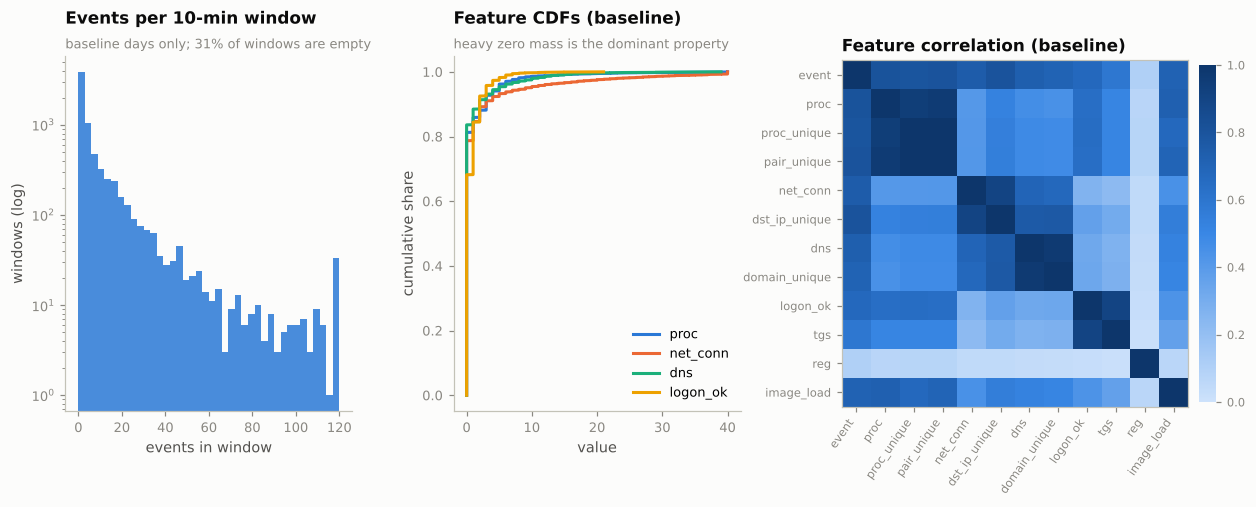

In [23]:
fig = plt.figure(figsize=(13.5, 4.2))
gs = fig.add_gridspec(1, 3, width_ratios=[1.15, 1.15, 1.5], wspace=0.32)

# distribution of window activity
ax = fig.add_subplot(gs[0, 0])
vals = Wtr.event_count.clip(upper=120)
ax.hist(vals, bins=40, color=CAT[0], alpha=0.85)
ax.set_yscale("log")
finish(ax, "Events per 10-min window", "baseline days only; 31% of windows are empty",
       xlabel="events in window", ylabel="windows (log)")

# a handful of representative feature distributions
ax = fig.add_subplot(gs[0, 1])
show = ["proc_count", "net_conn_count", "dns_count", "logon_ok_count"]
for i, f in enumerate(show):
    v = Wtr[f].clip(upper=40)
    ax.plot(np.sort(v), np.linspace(0, 1, len(v)), color=CAT[i], label=f.replace("_count", ""))
finish(ax, "Feature CDFs (baseline)", "heavy zero mass is the dominant property",
       xlabel="value", ylabel="cumulative share")
ax.legend(loc="lower right")

# correlation heatmap on a readable subset
ax = fig.add_subplot(gs[0, 2])
sub = ["event_count", "proc_count", "proc_unique", "pair_unique", "net_conn_count",
       "dst_ip_unique", "dns_count", "domain_unique", "logon_ok_count", "tgs_count",
       "reg_count", "image_load_count"]
cm = Wtr[sub].corr().values
im = ax.imshow(cm, cmap=BLUES, vmin=0, vmax=1)
ax.set_xticks(range(len(sub))); ax.set_xticklabels([s.replace("_count", "") for s in sub],
                                                   rotation=55, ha="right", fontsize=7.5)
ax.set_yticks(range(len(sub))); ax.set_yticklabels([s.replace("_count", "") for s in sub], fontsize=7.5)
ax.grid(False)
cb = fig.colorbar(im, ax=ax, fraction=0.045, pad=0.03); cb.outline.set_visible(False)
cb.ax.tick_params(labelsize=7.5, color=MUTED)
ax.set_title("Feature correlation (baseline)", loc="left", color=INK, fontsize=11)
plt.show()

---
## 13. Training Data Construction

The split is by **local date**, applied identically to the numeric frame, the categorical item frame and
the event table. The assertions are the leakage guard.

> **Runnable-notebook note:** `TRAIN_GRID` and `TEST_GRID` contain every configured 10-minute window. `TRAIN_W` and `TEST_W` are the telemetry-covered modelling subsets; covered empty windows are retained, while windows outside sensor coverage are excluded.


In [24]:
print("TRAIN_DATES:", sorted(TRAIN_DATES))
print("TEST_DATES:", sorted(TEST_DATES))

# At this point TRAIN_W/TEST_W have not been created yet. Use the
# complete grid and the split flags for this pre-construction check.
print("\nConfigured training date boundaries:")
print(W.loc[W.is_train, ["date", "win"]].sort_values("win").head(5))
print(W.loc[W.is_train, ["date", "win"]].sort_values("win").tail(5))

print("\nConfigured testing date boundaries:")
print(W.loc[~W.is_train, ["date", "win"]].sort_values("win").head(5))
print(W.loc[~W.is_train, ["date", "win"]].sort_values("win").tail(5))

print("\nData types:")
print(W[["date", "win"]].dtypes)

# Structural split guards that do not depend on TRAIN_W/TEST_W yet.
assert set(W.loc[W.is_train, "date"]) <= set(TRAIN_DATES)
assert set(W.loc[~W.is_train, "date"]) <= set(TEST_DATES)
assert set(TRAIN_DATES).isdisjoint(TEST_DATES), "TRAIN_DATES and TEST_DATES overlap"


TRAIN_DATES: ['2026-07-28', '2026-07-29', '2026-07-30', '2026-07-31', '2026-08-01', '2026-08-02', '2026-08-03']
TEST_DATES: ['2026-08-04', '2026-08-05', '2026-08-06', '2026-08-07', '2026-08-08', '2026-08-09', '2026-08-10', '2026-08-11', '2026-08-12', '2026-08-13', '2026-08-14', '2026-08-15', '2026-08-16', '2026-08-17']

Configured training date boundaries:
             date                       win
0      2026-07-28 2026-07-28 00:00:00+00:00
12096  2026-07-28 2026-07-28 00:00:00+00:00
9072   2026-07-28 2026-07-28 00:00:00+00:00
15120  2026-07-28 2026-07-28 00:00:00+00:00
6048   2026-07-28 2026-07-28 00:00:00+00:00
             date                       win
7055   2026-08-03 2026-08-03 23:50:00+00:00
4031   2026-08-03 2026-08-03 23:50:00+00:00
1007   2026-08-03 2026-08-03 23:50:00+00:00
19151  2026-08-03 2026-08-03 23:50:00+00:00
22175  2026-08-03 2026-08-03 23:50:00+00:00

Configured testing date boundaries:
             date                       win
1008   2026-08-04 2026-08-04 00:

In [25]:
print("Total windows:", len(W))

print("\nTraining flag distribution:")
print(W["is_train"].value_counts(dropna=False))

print("\nTelemetry distribution:")
print(W["has_telemetry"].value_counts(dropna=False))

print("\nDate distribution:")
print(W.groupby("date").size())

print("\nDate-wise training flags:")
print(pd.crosstab(W["date"], W["is_train"]))

print("\nDate-wise telemetry:")
print(pd.crosstab(W["date"], W["has_telemetry"]))

Total windows: 24192

Training flag distribution:
is_train
False    16128
True      8064
Name: count, dtype: int64

Telemetry distribution:
has_telemetry
True     23040
False     1152
Name: count, dtype: int64

Date distribution:
date
2026-07-28    1152
2026-07-29    1152
2026-07-30    1152
2026-07-31    1152
2026-08-01    1152
2026-08-02    1152
2026-08-03    1152
2026-08-04    1152
2026-08-05    1152
2026-08-06    1152
2026-08-07    1152
2026-08-08    1152
2026-08-09    1152
2026-08-10    1152
2026-08-11    1152
2026-08-12    1152
2026-08-13    1152
2026-08-14    1152
2026-08-15    1152
2026-08-16    1152
2026-08-17    1152
dtype: int64

Date-wise training flags:
is_train    False  True 
date                    
2026-07-28      0   1152
2026-07-29      0   1152
2026-07-30      0   1152
2026-07-31      0   1152
2026-08-01      0   1152
2026-08-02      0   1152
2026-08-03      0   1152
2026-08-04   1152      0
2026-08-05   1152      0
2026-08-06   1152      0
2026-08-07   1152      0
2

In [26]:
print("Actual event range:")
print("first:", raw["timestamp"].min())
print("last :", raw["timestamp"].max())

print("\nEvents by date:")
print(
    raw.assign(date=raw["timestamp"].dt.strftime("%Y-%m-%d"))
       .groupby("date")
       .size()
)

Actual event range:
first: 2026-07-28 18:30:05.382551+00:00
last : 2026-08-17 18:29:45.290618+00:00

Events by date:


date
2026-07-28    14972
2026-07-29    85456
2026-07-30    80798
2026-07-31    79027
2026-08-01    54869
2026-08-02    55244
2026-08-03    85360
2026-08-04    85136
2026-08-05    84842
2026-08-06    83141
2026-08-07    84077
2026-08-08    56739
2026-08-09    55838
2026-08-10    85059
2026-08-11    88550
2026-08-12    87280
2026-08-13    87448
2026-08-14    81756
2026-08-15    57875
2026-08-16    57544
2026-08-17    75846
dtype: int64


In [27]:
# -----------------------------------------------------------------------------
# 13.1 Explicit train/test split
#
# TRAIN_GRID / TEST_GRID = every configured 10-minute window.
# TRAIN_W / TEST_W       = only windows inside the observed sensor coverage.
#
# IMPORTANT: leakage is defined by the configured calendar-date split.  The
# covered subsets may be irregular because telemetry coverage is irregular,
# so their min/max timestamps are NOT used as the leakage criterion.
# -----------------------------------------------------------------------------
TRAIN_GRID = W.loc[W.is_train].copy()
TEST_GRID  = W.loc[~W.is_train].copy()

TRAIN_W = TRAIN_GRID.loc[TRAIN_GRID.has_telemetry].copy()
TEST_W  = TEST_GRID.loc[TEST_GRID.has_telemetry].copy()

# ---- definitive leakage guards: calendar dates -------------------------------
assert set(TRAIN_GRID.date).issubset(set(TRAIN_DATES))
assert set(TEST_GRID.date).issubset(set(TEST_DATES))
assert set(TRAIN_W.date).issubset(set(TRAIN_DATES))
assert set(TEST_W.date).issubset(set(TEST_DATES))
assert set(TRAIN_DATES).isdisjoint(TEST_DATES), "training and testing dates overlap"

# Explicit chronological boundary check, independent of telemetry coverage.
train_end = pd.Timestamp(max(TRAIN_DATES) + " 23:50", tz=TZ)
test_start = pd.Timestamp(min(TEST_DATES) + " 00:00", tz=TZ)
assert train_end < test_start, (
    f"training/test boundary is not chronological: {train_end} >= {test_start}"
)

# These are useful diagnostics, but deliberately NOT leakage assertions.
print(f"configured training boundary : {TRAIN_DATES[0]} 00:00 -> {train_end}")
print(f"configured testing boundary  : {test_start} -> {TEST_DATES[-1]} 23:50")
print(f"covered TRAIN_W range        : {TRAIN_W.win.min()} -> {TRAIN_W.win.max()}" if len(TRAIN_W) else "covered TRAIN_W range        : EMPTY")
print(f"covered TEST_W range         : {TEST_W.win.min()} -> {TEST_W.win.max()}" if len(TEST_W) else "covered TEST_W range         : EMPTY")

print(f"\ncomplete training grid : {len(TRAIN_GRID):,} windows")
print(f"complete test grid     : {len(TEST_GRID):,} windows")
print(f"training windows used  : {len(TRAIN_W):,} covered windows")
print(f"test windows used      : {len(TEST_W):,} covered windows")
print(f"training events        : {int(TRAIN_W.event_count.sum()):,}")
print(f"test events            : {int(TEST_W.event_count.sum()):,}")
print(f"uncovered training grid windows : {int((~TRAIN_GRID.has_telemetry).sum()):,}")
print(f"uncovered test grid windows     : {int((~TEST_GRID.has_telemetry).sum()):,}")

assert len(TRAIN_W) > 0, "TRAIN_W is empty: no telemetry-covered training windows"
assert len(TEST_W) > 0, "TEST_W is empty: no telemetry-covered test windows"

cells = TRAIN_W.groupby(["user", "hour"]).size()
allzero = int((TRAIN_W.groupby(["user", "hour"]).event_count.sum() == 0).sum())
print(f"user x hour baseline cells : {len(cells)}")
print(f"observations per covered cell : {sorted(int(v) for v in cells.unique())}")
print(f"cells that are ENTIRELY empty in training : {allzero}")
    
print()
print("  -> an all-empty covered user x hour cell is real behavioural idleness and is kept.")
print("     Only windows outside sensor coverage are excluded from modelling/scoring.")


configured training boundary : 2026-07-28 00:00 -> 2026-08-03 23:50:00+00:00
configured testing boundary  : 2026-08-04 00:00:00+00:00 -> 2026-08-17 23:50
covered TRAIN_W range        : 2026-07-28 18:30:00+00:00 -> 2026-08-03 23:50:00+00:00
covered TEST_W range         : 2026-08-04 00:00:00+00:00 -> 2026-08-17 18:20:00+00:00

complete training grid : 8,064 windows
complete test grid     : 16,128 windows
training windows used  : 7,176 covered windows
test windows used      : 15,864 covered windows
training events        : 61,380
test events            : 171,024
uncovered training grid windows : 888
uncovered test grid windows     : 264
user x hour baseline cells : 192
observations per covered cell : [36, 39, 42]
cells that are ENTIRELY empty in training : 0

  -> an all-empty covered user x hour cell is real behavioural idleness and is kept.
     Only windows outside sensor coverage are excluded from modelling/scoring.


---
## 14. User x Hour Baseline Creation

A baseline cell is `(user, hour)` and is learned from up to 42 ten-minute observations. It has three parts.

### (a) Robust numeric statistics
Counts are modelled in **log1p space**, where the multiplicative bursts typical of Windows telemetry become
roughly additive. For each feature we store `median`, `MAD`, `P5/P25/P75/P95`, `max` and the non-zero rate.
`mean +/- sd` is deliberately **not** the scale: a single busy window inside 42 observations would inflate
`sd` enough to hide a genuine spike.

With only 42 observations a cell's MAD is often exactly 0, which would make any non-zero value look
infinitely anomalous. The scale is therefore shrunk:

```
scale = max( 1.4826 * MAD(user,hour) ,  0.6 * 1.4826 * MAD(user, all hours) ,  0.35 )
```

- the **first** term is the cell's own dispersion when it has one,
- the **second** borrows the user's own all-hours dispersion (empirical-Bayes shrinkage - still
  user-specific, never global),
- the **third** is an absolute floor that stops an all-zero cell from producing an infinite z.

### (b) Behavioural inventories
Per user, the set of every executable, command-line style, parent->child pair, authentication source,
authentication path, host/logon-type, destination IP, destination port and DNS domain observed in the
7 baseline days - plus a **corpus-wide** frequency table so that "new to this user" and "never seen anywhere"
can be weighted differently.

### (c) Event-ID rarity
Per user and corpus-wide training frequency of each Event ID, used to score events that are structurally
rare rather than merely voluminous.

In [28]:
STAT_FEATURES = [c for c in FEATS if c in DENSE_FEATURES or c in [
    "encoded_count", "lsass_hi_count", "rthread_ext_count", "acct_mgmt_count", "group_mgmt_count",
    "svc_install_count", "task_count", "logclear_count", "script_ext_net_count",
    "script_sens_port_count", "remote_spawn_count", "archive_create_count"]]
# Counts are modelled in log1p space: Windows telemetry bursts multiplicatively, and log1p
# turns "3x more than usual" into a constant offset regardless of the user's normal volume.
LOGW = pd.DataFrame(np.log1p(W[STAT_FEATURES].to_numpy(float)), columns=STAT_FEATURES)
LOGW["user"] = W.user.to_numpy(); LOGW["hour"] = W.hour.to_numpy()
LOGW["date"] = W.date.to_numpy()
LOGW["has_tel"] = W.has_telemetry.to_numpy(dtype=bool)


def fit_numeric_baseline(train_dates):
    """Robust per-(user, hour) statistics, plus per-user fallbacks used for scale shrinkage."""
    t = LOGW[LOGW.date.isin(train_dates) & LOGW["has_tel"]]
    g = t.groupby(["user", "hour"])[STAT_FEATURES]
    med_h = g.median()
    mad_h = t.set_index(["user", "hour"])[STAT_FEATURES].sub(med_h).abs().groupby(level=[0, 1]).median()
    med_u = t.groupby("user")[STAT_FEATURES].median()
    mad_u = t.set_index("user")[STAT_FEATURES].sub(med_u).abs().groupby(level=0).median()
    return {"med_h": med_h, "mad_h": mad_h, "med_u": med_u, "mad_u": mad_u,
            "p05_h": g.quantile(0.05), "p25_h": g.quantile(0.25), "p75_h": g.quantile(0.75),
            "p95_h": g.quantile(0.95), "max_h": g.max(), "n": t.groupby(["user", "hour"]).size()}


def fit_inventories(train_dates):
    tr = ITEMS[ITEMS.date.isin(train_dates)]
    known = tr[["user", "itype", "value"]].drop_duplicates()
    known["known"] = True
    gcnt = tr.groupby(["itype", "gvalue"]).size().rename("gcnt").reset_index()
    return known, gcnt


def fit_eid_rarity(train_dates):
    tr = ev[ev.date.isin(train_dates)]
    return (tr.groupby(["user", "EventID"]).size().rename("ucnt").reset_index(),
            tr.groupby("user").size().rename("utot").reset_index(),
            tr.groupby("EventID").size().rename("gcnt").reset_index(),
            len(tr))


def fit_activation(train_dates):
    """Per-user maximum of each feature. Where that maximum is 0, the user has NEVER
    exercised that capability in any baseline hour - so any non-zero value later is a
    first occurrence, which the z-score cannot express but section 17 can."""
    return W[W.date.isin(train_dates) & W.has_telemetry].groupby("user")[ACT_FEATURES].max()



def fit_temporal_profile(train_dates, alpha=TEMP_ALPHA):
    """Smoothed P(active | user, day_type, hour), fitted from the supplied dates only."""
    t = W[W.date.isin(train_dates) & W.has_telemetry].copy()
    t["active"] = (t["event_count"] > 0).astype(float)
    # user-level prior stabilises sparse weekend cells; it is not a separate weekend baseline
    user_prior = t.groupby("user")["active"].mean().rename("prior")
    prof = (t.groupby(["user", "day_type", "hour"], observed=True)["active"]
              .agg(active_windows="sum", n_windows="count").reset_index()
              .merge(user_prior.reset_index(), on="user", how="left"))
    prof["p_active"] = ((prof["active_windows"] + alpha * prof["prior"]) /
                        (prof["n_windows"] + alpha)).clip(0.0, 1.0)
    return prof


ACT_WEIGHTS = {
    "encoded_count": 2.0, "hidden_ps_count": 0.8, "scripthost_count": 1.5, "discovery_count": 1.2,
    "lolbin_count": 1.2, "admin_count": 1.2, "transfer_count": 1.0, "temp_proc_count": 1.5,
    "remoteexec_count": 0.8, "lsass_acc_count": 1.5, "lsass_hi_count": 2.5, "rthread_ext_count": 2.5,
    "remote_thread_count": 1.0, "exe_create_count": 1.0, "script_create_count": 1.2,
    "archive_create_count": 1.2, "temp_create_count": 1.0, "run_key_count": 1.5, "svc_key_count": 1.0,
    "acct_mgmt_count": 2.5, "group_mgmt_count": 2.5, "svc_install_count": 2.5, "task_count": 2.0,
    "logclear_count": 3.0, "explicit_count": 1.2, "ext_src_count": 2.0, "ext_fail_count": 2.5, "sens_port_count": 0.8,
    "srv_lookup_count": 0.5, "dns_fail_count": 0.5, "krb_fail_count": 0.8, "ntlm_fail_count": 0.8,
    "lt10_count": 0.8, "lt2_count": 0.6, "script_net_count": 0.8, "script_ext_net_count": 1.5,
    "script_sens_port_count": 1.5, "remote_spawn_count": 1.5,
}
ACT_FEATURES = [c for c in ACT_WEIGHTS if c in W.columns]


def fit_baseline(train_dates):
    known, gcnt = fit_inventories(train_dates)
    ucnt, utot, egcnt, gtot = fit_eid_rarity(train_dates)
    return {"num": fit_numeric_baseline(train_dates), "known": known, "gcnt": gcnt,
            "eid_ucnt": ucnt, "eid_utot": utot, "eid_gcnt": egcnt, "eid_gtot": gtot,
            "act_max": fit_activation(train_dates), "train_dates": list(train_dates)}


BASELINE = fit_baseline(TRAIN_DATES)
TEMP_PROFILE = fit_temporal_profile(TRAIN_DATES)
print(f"temporal profile fitted on {len(TRAIN_DATES)} days: {len(TEMP_PROFILE):,} user/day_type/hour cells")
print(f"baseline fitted on {len(TRAIN_DATES)} days")
print(f"  numeric cells        : {len(BASELINE['num']['med_h'])}  (user x hour)")
print(f"  features per cell    : {len(STAT_FEATURES)}")
print(f"  behavioural entries  : {len(BASELINE['known']):,} distinct (user, dimension, value) triples")
print(f"  corpus rarity table  : {len(BASELINE['gcnt']):,} distinct (dimension, value) pairs")

temporal profile fitted on 7 days: 384 user/day_type/hour cells
baseline fitted on 7 days
  numeric cells        : 192  (user x hour)
  features per cell    : 59
  behavioural entries  : 2,771 distinct (user, dimension, value) triples
  corpus rarity table  : 793 distinct (dimension, value) pairs


In [29]:
# ---- Option 2 temporal-context diagnostics ----------------------------------------
print("TEMPORAL ACTIVITY PROFILE: P(active | user, day_type, hour)")
display(TEMP_PROFILE.sort_values(["user", "day_type", "hour"]).assign(
    p_active=lambda d: d.p_active.round(3)).head(40))
print(f"smoothing alpha = {TEMP_ALPHA};  weekday/weekend defined in {DAYTYPE_TZ}")
print("No separate weekend behavioural baseline is created; this is temporal context only.")


TEMPORAL ACTIVITY PROFILE: P(active | user, day_type, hour)


,user,day_type,hour,active_windows,n_windows,prior,p_active
0,ananya.sharma,weekday,0,14.0,24,0.672241,0.596
1,ananya.sharma,weekday,1,12.0,24,0.672241,0.525
2,ananya.sharma,weekday,2,14.0,24,0.672241,0.596
3,ananya.sharma,weekday,3,12.0,24,0.672241,0.525
4,ananya.sharma,weekday,4,14.0,24,0.672241,0.596
5,ananya.sharma,weekday,5,13.0,24,0.672241,0.560
6,ananya.sharma,weekday,6,15.0,24,0.672241,0.632
7,ananya.sharma,weekday,7,13.0,24,0.672241,0.560
8,ananya.sharma,weekday,8,17.0,24,0.672241,0.703
9,ananya.sharma,weekday,9,19.0,24,0.672241,0.775


smoothing alpha = 4.0;  weekday/weekend defined in Asia/Kolkata
No separate weekend behavioural baseline is created; this is temporal context only.


In [30]:
# ---- the baseline as a tidy table (the deliverable shape from the brief) -------------
num = BASELINE["num"]
tidy = []
for stat, frame in [("median", num["med_h"]), ("mad", num["mad_h"]), ("p05", num["p05_h"]),
                    ("p25", num["p25_h"]), ("p75", num["p75_h"]), ("p95", num["p95_h"]),
                    ("max", num["max_h"])]:
    t = frame.stack().rename(stat)
    t.index.names = ["user", "hour", "feature"]
    tidy.append(t)
BASELINE_TABLE = pd.concat(tidy, axis=1).reset_index()
# stored in log1p space for the model; expose the natural-scale value for humans
for c in ["median", "p05", "p25", "p75", "p95", "max"]:
    BASELINE_TABLE[c + "_events"] = np.expm1(BASELINE_TABLE[c]).round(2)
BASELINE_TABLE = BASELINE_TABLE.merge(obs, on=["user", "hour"], how="left")

print(f"baseline table: {len(BASELINE_TABLE):,} rows "
      f"({len(PRINCIPALS)} users x 24 hours x {len(STAT_FEATURES)} features)")
print()
print(f"example - {EXAMPLE_USER}, hour 21:")
display(BASELINE_TABLE[(BASELINE_TABLE.user == EXAMPLE_USER) & (BASELINE_TABLE.hour == 21) &
                       BASELINE_TABLE.feature.isin(["event_count", "proc_count", "proc_unique",
                                                    "logon_ok_count", "net_conn_count", "dns_count"])]
        [["user", "hour", "feature", "n_obs", "median_events", "p75_events", "p95_events",
          "max_events", "mad"]].round(3))

print("behavioural inventory sizes per principal (baseline days):")
inv_sizes = (BASELINE["known"].groupby(["user", "itype"]).size().unstack(fill_value=0))
display(inv_sizes[["process", "cmd_sig", "pair", "src_ip", "auth_path", "logon_host_type",
                   "dst_ip", "dst_port", "domain", "computer"]])

# ---------------------------------------------------------------- 14.3 tables ------
def hourly_profile(user, features, stat="median"):
    """One user's 24-hour behavioural fingerprint: rows = hour, columns = feature."""
    t = BASELINE_TABLE[(BASELINE_TABLE.user == user) & BASELINE_TABLE.feature.isin(features)]
    piv = t.pivot(index="hour", columns="feature", values=stat + "_events")[features]
    piv.insert(0, "n_obs", t.groupby("hour").n_obs.first())
    return piv.round(2)


PROFILE_FEATURES = ["event_count", "proc_count", "proc_unique", "logon_ok_count",
                    "net_conn_count", "dst_ip_unique", "dns_count", "reg_count"]

print("=" * 96)
print(f"BASELINE PROFILE - {EXAMPLE_USER}, all 24 UTC hours (median per 10-minute window)")
print("=" * 96)
display(hourly_profile(EXAMPLE_USER, PROFILE_FEATURES, "median"))

print("Same user, same hours, the P95 upper edge of normal:")
display(hourly_profile(EXAMPLE_USER, PROFILE_FEATURES, "p95"))

print("=" * 96)
print("WHAT EACH PRINCIPAL NORMALLY RUNS - top baseline executables (this is what novelty is judged against)")
print("=" * 96)
_tp = (ev[ev.is_proc & ev.date.isin(TRAIN_DATES)]
       .groupby(["user", "image_base"]).size().rename("n").reset_index()
       .sort_values(["user", "n"], ascending=[True, False]))
with pd.option_context("display.max_colwidth", 140):
    display(pd.DataFrame({
        "distinct executables": _tp.groupby("user").size(),
        "top 8 by volume": _tp.groupby("user").head(8).groupby("user")
            .apply(lambda d: ", ".join(f"{r.image_base}({r.n})" for _, r in d.iterrows())),
    }))

print("AUTHENTICATION FOOTPRINT - where each principal normally logs on from, and onto")
_au = ev[ev.f_logon_ok & ev.date.isin(TRAIN_DATES)]
with pd.option_context("display.max_colwidth", 140):
    display(pd.DataFrame({
        "hosts logged onto": _au.groupby("user").computer.apply(
            lambda s: ", ".join(sorted(s.dropna().unique()))),
        "logon types": _au.groupby("user").logon_type.apply(
            lambda s: ", ".join(str(int(v)) for v in sorted(s.dropna().unique()))),
        "distinct source IPs": _au.groupby("user").src_ip.nunique(),
    }))

baseline table: 11,328 rows (8 users x 24 hours x 59 features)

example - arjun.iyer, hour 21:


,user,hour,feature,n_obs,median_events,p75_events,p95_events,max_events,mad
2655,arjun.iyer,21,event_count,42,1.0,1.71,11.89,22.0,0.549
2656,arjun.iyer,21,proc_count,42,0.0,0.00,0.00,5.0,0.000
2667,arjun.iyer,21,proc_unique,42,0.0,0.00,0.00,3.0,0.000
2670,arjun.iyer,21,net_conn_count,42,0.0,0.00,0.00,2.0,0.000
2678,arjun.iyer,21,dns_count,42,0.0,0.00,0.00,2.0,0.000
2691,arjun.iyer,21,logon_ok_count,42,0.0,0.00,1.94,2.0,0.000


behavioural inventory sizes per principal (baseline days):


itype,process,cmd_sig,pair,src_ip,auth_path,logon_host_type,dst_ip,dst_port,domain,computer
user,,,,,,,,,,
ananya.sharma,28,8,34,12,30,19,110,5,69,11
arjun.iyer,34,11,48,12,16,14,127,6,73,11
kavya.reddy,35,10,56,12,19,15,154,5,75,9
priya.menon,44,18,67,12,21,24,92,7,63,12
rahul.verma,30,7,38,12,29,20,122,6,71,10
rohan.mehta,17,6,20,12,33,20,99,4,67,12
sneha.patel,22,6,28,12,29,20,129,3,69,11
vikram.nair,27,6,31,12,16,13,154,5,70,10


BASELINE PROFILE - arjun.iyer, all 24 UTC hours (median per 10-minute window)


...

feature,n_obs,event_count,proc_count,proc_unique,logon_ok_count,net_conn_count,dst_ip_unique,dns_count,reg_count
hour,,,,,,,,,
0,36,15.24,5.00,3.00,2.00,1.00,1.00,1.00,3.00
1,36,4.74,0.41,0.41,1.21,0.19,0.19,0.00,1.21
2,36,7.66,0.41,0.41,1.21,0.19,0.19,0.00,3.00
3,36,14.48,5.00,3.00,2.00,1.00,1.00,2.00,2.00
4,36,7.24,0.00,0.00,1.00,0.00,0.00,0.00,2.00
5,36,7.85,3.00,3.00,1.21,0.19,0.19,0.19,1.00
6,36,8.80,0.57,0.41,1.21,0.32,0.19,0.19,2.22
7,36,16.24,2.41,2.22,2.00,1.21,1.21,1.00,2.00
8,36,33.18,7.00,7.00,4.00,5.24,3.23,4.95,2.22


WHAT EACH PRINCIPAL NORMALLY RUNS - top baseline executables (this is what novelty is judged against)


,distinct executables,top 8 by volume
user,,
ananya.sharma,28,"chrome.exe(77), explorer.exe(35), userinit.exe(35), pbidesktop.exe(32), sqlcmd.exe(27), cmd.exe(16), teams.exe(16), googledrivefs.exe(14)"
arjun.iyer,34,"explorer.exe(98), userinit.exe(98), chrome.exe(93), pbidesktop.exe(85), sqlcmd.exe(61), powershell.exe(58), mstsc.exe(50), cmd.exe(46)"
kavya.reddy,35,"explorer.exe(130), userinit.exe(130), mstsc.exe(85), postman.exe(74), cmd.exe(70), chrome.exe(63), sublime_text.exe(58), notepad++.exe(55)"
priya.menon,44,"explorer.exe(233), userinit.exe(233), mstsc.exe(168), powershell.exe(81), postman.exe(61), firefox.exe(60), code.exe(54), sublime_text.e..."
rahul.verma,30,"explorer.exe(226), userinit.exe(226), mstsc.exe(179), firefox.exe(59), mmc.exe(46), slack.exe(25), zsatray.exe(23), googledrivefs.exe(18)"
rohan.mehta,17,"explorer.exe(32), userinit.exe(32), chrome.exe(21), zoom.exe(17), slack.exe(16), googledrivefs.exe(15), zsatray.exe(12), dropbox.exe(11)"
sneha.patel,22,"chrome.exe(111), explorer.exe(67), userinit.exe(67), zsatray.exe(39), postman.exe(35), mmc.exe(29), teams.exe(29), powershell.exe(23)"
vikram.nair,27,"chrome.exe(54), explorer.exe(39), userinit.exe(39), googledrivefs.exe(25), teams.exe(21), dropbox.exe(18), slack.exe(18), zsatray.exe(16)"


AUTHENTICATION FOOTPRINT - where each principal normally logs on from, and onto


,hosts logged onto,logon types,distinct source IPs
user,,,
ananya.sharma,"APP-01, DC-01, FILE-01, PC-001, PC-002, PC-003, PC-004, PC-005, PC-007, PC-008, SQL-01","2, 3, 7, 10",12
arjun.iyer,"APP-01, DC-01, FILE-01, PC-001, PC-002, PC-003, PC-004, PC-006, PC-007, PC-008, SQL-01","2, 3, 7, 10",12
kavya.reddy,"APP-01, DC-01, FILE-01, PC-001, PC-003, PC-004, PC-006, PC-008, SQL-01","2, 3, 7, 10, 11",12
priya.menon,"APP-01, DC-01, FILE-01, PC-001, PC-002, PC-003, PC-004, PC-005, PC-006, PC-007, PC-008, SQL-01","2, 3, 7, 10, 11",12
rahul.verma,"APP-01, DC-01, FILE-01, PC-001, PC-003, PC-004, PC-005, PC-006, PC-007, SQL-01","2, 3, 7, 10",12
rohan.mehta,"APP-01, DC-01, FILE-01, PC-001, PC-002, PC-003, PC-004, PC-005, PC-006, PC-007, PC-008, SQL-01","2, 3, 7, 10",12
sneha.patel,"APP-01, DC-01, FILE-01, PC-001, PC-002, PC-004, PC-005, PC-006, PC-007, PC-008, SQL-01","2, 3, 7, 10, 11",12
vikram.nair,"FILE-01, PC-001, PC-002, PC-004, PC-005, PC-006, PC-007, PC-008, SQL-01","2, 3, 7, 10",12


---
## 15. Baseline Visualisation

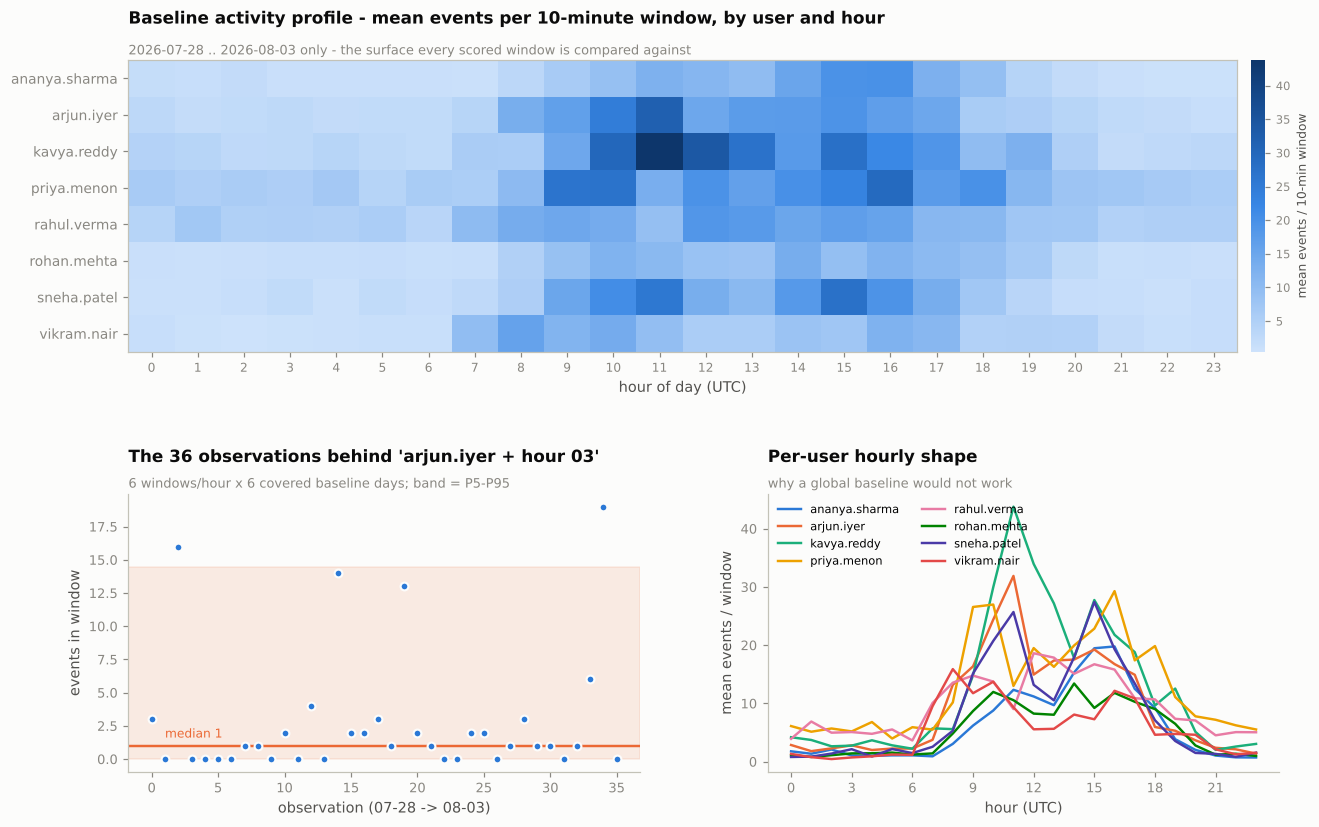

In [31]:
fig = plt.figure(figsize=(13.5, 8.4))
gs = fig.add_gridspec(2, 2, height_ratios=[1.05, 1], hspace=0.5, wspace=0.25)

# (1) user x hour activity heatmap - the baseline the model actually learns
ax = fig.add_subplot(gs[0, :])
hm = (TRAIN_W.groupby(["user", "hour"]).event_count.mean()
      .unstack(fill_value=0).reindex(PRINCIPALS))
im = ax.imshow(hm.values, aspect="auto", cmap=BLUES)
ax.set_yticks(range(len(hm))); ax.set_yticklabels(hm.index, fontsize=9)
ax.set_xticks(range(0, 24)); ax.set_xticklabels(range(24), fontsize=8)
ax.grid(False)
cb = fig.colorbar(im, ax=ax, fraction=0.025, pad=0.012); cb.outline.set_visible(False)
cb.set_label("mean events / 10-min window", fontsize=8, color=INK2)
cb.ax.tick_params(labelsize=7.5)
ax.set_title("Baseline activity profile - mean events per 10-minute window, by user and hour",
             loc="left", color=INK, pad=24)
ax.text(0, 1.02, f"{TRAIN_DATES[0]} .. {TRAIN_DATES[-1]} only - the surface every scored window "
                 "is compared against", transform=ax.transAxes, color=MUTED, fontsize=8.5)
ax.set_xlabel(f"hour of day ({TZ})")

# (2) the 42 observations behind one cell
ax = fig.add_subplot(gs[1, 0])
u, h = EXAMPLE_USER, 3
cell = TRAIN_W[(TRAIN_W.user == u) & (TRAIN_W.hour == h)].sort_values("win")
ax.scatter(range(len(cell)), cell.event_count.values, s=26, color=CAT[0],
           edgecolor=SURFACE, linewidth=1.4, zorder=3)
row = BASELINE_TABLE[(BASELINE_TABLE.user == u) & (BASELINE_TABLE.hour == h) &
                     (BASELINE_TABLE.feature == "event_count")].iloc[0]
ax.axhline(row.median_events, color=CAT[1], lw=1.6, zorder=2)
ax.axhspan(row.p05_events, row.p95_events, color=CAT[1], alpha=0.12, zorder=1)
ax.text(1, row.median_events + 0.4, f"median {row.median_events:.0f}",
        color=CAT[1], fontsize=8, va="bottom")
finish(ax, f"The {len(cell)} observations behind '{u} + hour {h:02d}'",
       f"{WINDOWS_PER_HOUR} windows/hour x {len(cell) // WINDOWS_PER_HOUR} covered baseline days; "
       "band = P5-P95",
       xlabel=f"observation ({TRAIN_DATES[0][5:]} -> {TRAIN_DATES[-1][5:]})",
       ylabel="events in window")

# (3) how much each user varies hour to hour
ax = fig.add_subplot(gs[1, 1])
prof = TRAIN_W.groupby(["user", "hour"]).event_count.mean().unstack()
for i, uu in enumerate(PRINCIPALS):
    ax.plot(prof.columns, prof.loc[uu].values, color=CAT[i % 8], lw=1.6, label=uu)
finish(ax, "Per-user hourly shape", "why a global baseline would not work",
       xlabel=f"hour ({TZ})", ylabel="mean events / window")
ax.set_xticks(range(0, 24, 3))
ax.legend(ncols=2, loc="upper left", fontsize=7.5)
plt.show()

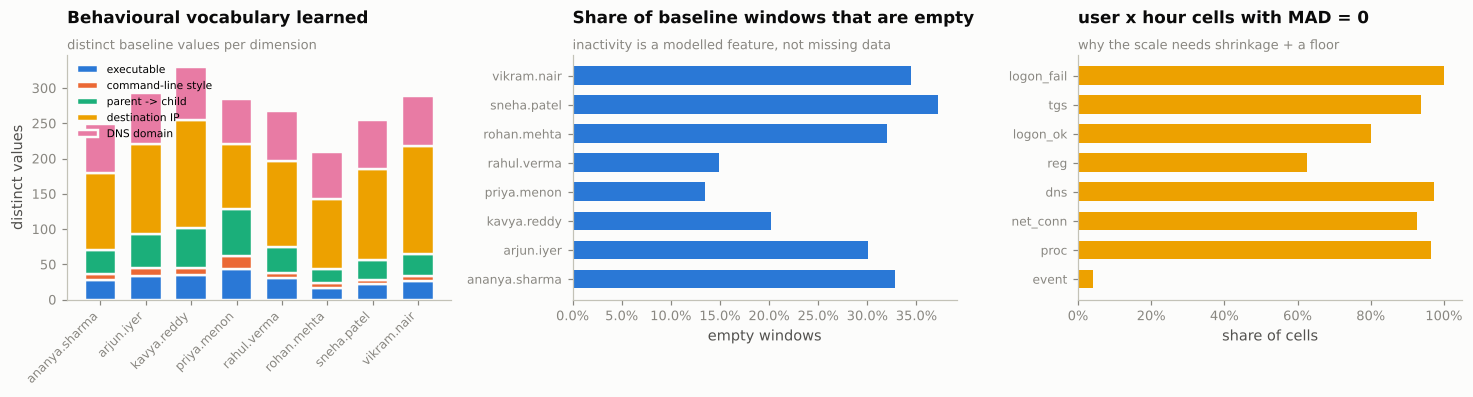

In [32]:
fig, axes = plt.subplots(1, 3, figsize=(13.5, 3.7))

# inventory sizes - how much behavioural vocabulary each principal has
ax = axes[0]
iv = inv_sizes[["process", "cmd_sig", "pair", "dst_ip", "domain"]].reindex(PRINCIPALS)
bottom = np.zeros(len(iv))
for i, c in enumerate(iv.columns):
    ax.bar(range(len(iv)), iv[c].values, bottom=bottom, color=CAT[i], width=0.7,
           label=ITEM_LABEL[c], linewidth=1.6, edgecolor=SURFACE)
    bottom += iv[c].values
ax.set_xticks(range(len(iv))); ax.set_xticklabels(iv.index, rotation=45, ha="right", fontsize=8)
finish(ax, "Behavioural vocabulary learned", "distinct baseline values per dimension",
       ylabel="distinct values")
ax.legend(fontsize=7, loc="upper left")

# empty-window share per user
ax = axes[1]
empt = TRAIN_W.groupby("user").apply(lambda d: (d.event_count == 0).mean()).reindex(PRINCIPALS)
ax.barh(range(len(empt)), empt.values, color=CAT[0], height=0.65)
ax.set_yticks(range(len(empt))); ax.set_yticklabels(empt.index, fontsize=8)
ax.xaxis.set_major_formatter(mpl.ticker.PercentFormatter(1.0))
finish(ax, "Share of baseline windows that are empty",
       "inactivity is a modelled feature, not missing data",
       xlabel="empty windows", xgrid=True)

# scale-floor diagnostic: how many cells have MAD == 0
ax = axes[2]
mad0 = (num["mad_h"] == 0).mean(axis=0).sort_values(ascending=False)
pick = ["event_count", "proc_count", "net_conn_count", "dns_count", "reg_count",
        "logon_ok_count", "tgs_count", "logon_fail_count"]
vals = [mad0[p] for p in pick]
ax.barh(range(len(pick)), vals, color=CAT[3], height=0.65)
ax.set_yticks(range(len(pick))); ax.set_yticklabels([p.replace("_count", "") for p in pick], fontsize=8)
ax.xaxis.set_major_formatter(mpl.ticker.PercentFormatter(1.0))
finish(ax, "user x hour cells with MAD = 0", "why the scale needs shrinkage + a floor",
       xlabel="share of cells", xgrid=True)
plt.tight_layout(); plt.show()

---
## 16. Test Feature Extraction & the Scoring Engine

Test windows go through **exactly the same** pipeline as training windows - same flags, same aggregation,
same categorical extraction - and are compared against `user + hour` only, never against a global model,
never against the user's other hours, never against day 8 itself.

### Leave-one-day-out scoring of the baseline period

To choose a threshold we need to know what score a *normal* window produces. Scoring the training days
against a baseline that already contains them would give an artificially clean answer (every executable
would already be "known", every count already inside its own median). So each baseline day is scored
against a baseline re-fitted on the **other days of the baseline period**. That yields one honest "normal"
score for every covered baseline window, and that set is the null distribution section 18 reads the alert
threshold off.

Five signals are computed. They answer different questions and fail in different ways, which is why they
are fused rather than replaced by one another.

| Signal | Question | Strength |
|---|---|---|
| `s_stat` | *Is there more of something than this user normally does at this hour?* | volume spikes |
| `s_nov`  | *Is this user doing something they have never done?* | new tools, hosts, destinations |
| `s_act`  | *Has a whole class of behaviour switched on for the first time?* | first LSASS access, first service install |
| `s_rare` | *Did an event type fire that is structurally rare in this environment?* | account creation, log clearing |
| `s_ml`   | *Does the joint deviation vector look unlike any training window?* | multivariate shape |

In [33]:
BASE_W = {"process": 1.0, "cmd_sig": 0.9, "pair": 0.7, "src_ip": 1.0, "auth_path": 1.0,
          "logon_host_type": 1.1, "logon_type": 0.6, "dst_ip": 0.5, "dst_port": 0.2,
          "domain": 0.4, "computer": 0.5}
GNOV_W = {"process": 1.0, "cmd_sig": 0.5, "pair": 0.5, "src_ip": 1.0, "auth_path": 0.4,
          "logon_host_type": 0.4, "logon_type": 0.0, "dst_ip": 0.8, "dst_port": 0.2,
          "domain": 1.5, "computer": 0.3}


def novelty_frame(bl, score_dates):
    """Every categorical value in the scored windows that this user never showed in baseline."""
    d = ITEMS[ITEMS.date.isin(score_dates)].merge(bl["known"], on=["user", "itype", "value"], how="left")
    d = d.merge(bl["gcnt"], on=["itype", "gvalue"], how="left")
    d["known"] = d["known"].fillna(False).astype(bool)
    d["gcnt"] = d["gcnt"].fillna(0).astype(float)
    d = d[~d.known].copy()

    w = d.itype.map(BASE_W).astype(float)
    w = w + (d.gcnt == 0).astype(float) * d.itype.map(GNOV_W).astype(float)   # never seen anywhere
    w = w + d.susp_dir.astype(float) * 1.0                                    # ran from a staging dir
    w = w + (d.is_public & (d.itype == "src_ip")).astype(float) * 2.5         # auth from the internet
    w = w + (d.is_public & (d.itype == "dst_ip") & (d.gcnt == 0)).astype(float) * 2.0
    w = w + d.sens_port.astype(float) * 0.8                                   # infrastructure port
    w = w + d.interactive.astype(float) * 0.8                                 # console/RDP on a new host
    # browsers and collaboration clients churn through destinations by design - damp that novelty
    w = np.where(d.trusted & d.itype.isin(["dst_ip", "domain"]), w * 0.06, w)
    d["w"] = w
    return d


def rarity_frame(bl, score_dates):
    """Event IDs that are rare for this user AND rare across the whole baseline corpus."""
    sc = (ev[ev.date.isin(score_dates)].groupby(["user", "win", "EventID"]).size()
          .rename("n").reset_index())
    sc = (sc.merge(bl["eid_ucnt"], on=["user", "EventID"], how="left")
            .merge(bl["eid_utot"], on="user", how="left")
            .merge(bl["eid_gcnt"], on="EventID", how="left"))
    sc["ucnt"] = sc.ucnt.fillna(0).astype(float)
    sc["gcnt"] = sc.gcnt.fillna(0).astype(float)
    s_u = -np.log10((sc.ucnt + 0.5) / (sc.utot + 1.0))          # surprise for this user
    s_g = -np.log10((sc.gcnt + 0.5) / (bl["eid_gtot"] + 1.0))   # surprise for the environment
    sc["w"] = np.clip(s_u - 3.0, 0, None) * 0.6 + np.clip(s_g - 4.0, 0, None) * 1.2
    return sc[sc.w > 0].copy()


def activation_matrix(bl, idx):
    """Features whose baseline maximum is 0 for this user and which are non-zero now."""
    sub = W.loc[idx]
    bm = bl["act_max"].reindex(sub.user).to_numpy(float)
    X = sub[ACT_FEATURES].to_numpy(float)
    fired = (X > 0) & (np.nan_to_num(bm) == 0)
    wvec = np.array([ACT_WEIGHTS[c] for c in ACT_FEATURES])[None, :]
    return fired * wvec * (1 + 0.3 * np.log1p(X))


def robust_z(bl, idx):
    """(log1p(x) - median) / shrunk-scale, per user x hour, only for upward deviations."""
    num = bl["num"]
    sub = LOGW.loc[idx]
    key = pd.MultiIndex.from_arrays([sub.user, sub.hour])
    X   = sub[STAT_FEATURES].to_numpy(float)
    med = np.nan_to_num(num["med_h"].reindex(key).to_numpy(float))
    mad = np.nan_to_num(num["mad_h"].reindex(key).to_numpy(float))
    madu = np.nan_to_num(num["mad_u"].reindex(sub.user).to_numpy(float))
    p95 = np.nan_to_num(num["p95_h"].reindex(key).to_numpy(float))
    scale = np.maximum.reduce([1.4826 * mad, 0.6 * 1.4826 * madu, np.full_like(X, 0.35)])
    z = (X - med) / scale
    return np.where(X > p95, z, np.minimum(z, 0))    # only exceeding the cell's P95 can be positive


def combine_stat(sev):
    """Top-3 severity, geometrically damped: broad mild elevation must not imitate a real spike."""
    srt = -np.sort(-sev, axis=1)
    raw = srt[:, 0] + 0.5 * srt[:, 1] + 0.25 * srt[:, 2]
    return 1 - np.exp(-raw / K_STAT), raw


def score_block(bl, score_dates, temp_profile=None):
    """Score every covered window of `score_dates` against the baseline `bl`.

    Windows outside the sensor's capture range are skipped entirely - scoring them would
    turn "the log was not being written" into "this user did nothing", which is not a fact
    the model is entitled to assert."""
    idx = W.index[W.date.isin(score_dates) & W.has_telemetry]
    z   = robust_z(bl, idx)
    sev = np.clip((z - Z0) / (Z1 - Z0), 0, 1)
    s_stat, stat_raw = combine_stat(sev)
    nv  = novelty_frame(bl, score_dates)
    rf  = rarity_frame(bl, score_dates)
    actm = activation_matrix(bl, idx)

    out = W.loc[idx, ["wid", "user", "win", "date", "hour", "day_type", "is_train", "event_count"]].copy()
    key = pd.MultiIndex.from_arrays([out.user, out.win])
    out["nov"]  = nv.groupby(["user", "win"])["w"].sum().reindex(key).to_numpy()
    out["rare"] = rf.groupby(["user", "win"])["w"].sum().reindex(key).to_numpy()
    out[["nov", "rare"]] = out[["nov", "rare"]].fillna(0)
    out["act"]    = actm.sum(axis=1)
    out["s_stat"] = s_stat
    out["s_nov"]  = 1 - np.exp(-out.nov / K_NOV)
    out["s_rare"] = 1 - np.exp(-out.rare / K_RARE)
    out["s_act"]  = 1 - np.exp(-out.act / K_ACT)
    # temporal context: how unusual is it for THIS user to be active at this day_type x hour?
    # Fitted on bl["train_dates"] - the LODO fold's own days, or the training week - never the scored days.
    tp = temp_profile if temp_profile is not None else fit_temporal_profile(bl["train_dates"])
    p = tp.set_index(["user", "day_type", "hour"]).p_active.reindex(
        pd.MultiIndex.from_arrays([out.user, out.day_type, out.hour])).to_numpy(float)
    prior = tp.groupby("user").prior.first().reindex(out.user).to_numpy(float)
    out["p_active"] = np.where(np.isnan(p), prior, p)        # unseen cell -> user's overall rate
    out["s_temp"] = np.where(out.event_count > 0, 1 - out.p_active, 0.0)   # inactive is never anomalous
    return out.reset_index(drop=True), {"z": z, "sev": sev, "nov": nv, "rare": rf, "act": actm}


# ---- leave-one-day-out over the baseline period ------------------------------------
print("scoring the baseline period leave-one-day-out ...")
tr_parts, tr_z, tr_act = [], [], []
for d in TRAIN_DATES:
    bl_d = fit_baseline([x for x in TRAIN_DATES if x != d])
    o, dbg = score_block(bl_d, [d])
    tr_parts.append(o); tr_z.append(dbg["z"]); tr_act.append(dbg["act"])
    print(f"   fold holding out {d}: {len(o):,} windows scored")
TR = pd.concat(tr_parts, ignore_index=True)
Z_TR   = np.vstack(tr_z)
ACT_TR = np.vstack(tr_act)

# ---- the real thing: days 8-12 against the full 7-day baseline ---------------------
TE, DBG = score_block(BASELINE, TEST_DATES)
Z_TE, SEV_TE, NOV_TE, RARE_TE, ACT_TE = DBG["z"], DBG["sev"], DBG["nov"], DBG["rare"], DBG["act"]
print(f"\ntest windows scored: {len(TE):,}")
print(TE[["s_stat", "s_nov", "s_rare", "s_act"]].describe(percentiles=[.5, .9, .99]).round(3))

scoring the baseline period leave-one-day-out ...


   fold holding out 2026-07-28: 264 windows scored


   fold holding out 2026-07-29: 1,152 windows scored


   fold holding out 2026-07-30: 1,152 windows scored


   fold holding out 2026-07-31: 1,152 windows scored


   fold holding out 2026-08-01: 1,152 windows scored


   fold holding out 2026-08-02: 1,152 windows scored


   fold holding out 2026-08-03: 1,152 windows scored



test windows scored: 15,864
          s_stat      s_nov     s_rare      s_act
count  15864.000  15864.000  15864.000  15864.000
mean       0.002      0.020      0.005      0.009
std        0.016      0.093      0.059      0.084
min        0.000      0.000      0.000      0.000
50%        0.000      0.000      0.000      0.000
90%        0.000      0.007      0.000      0.000
99%        0.084      0.640      0.064      0.620
max        0.310      0.988      0.995      0.984


### 16.2 Machine-learning comparison

The brief asks that a statistical baseline be built first and that ML be adopted only if it **adds** value.
The three standard unsupervised detectors are fitted on the leave-one-day-out deviation matrix
(each row is a window's per-feature robust z, i.e. already normalised for *that user at that hour*) and
scored on the test days. Section 20 measures whether any of them earns its place.

In [34]:
Xtr, Xte = np.nan_to_num(Z_TR), np.nan_to_num(Z_TE)


def to_train_percentile(train_scores, test_scores):
    q = np.sort(train_scores)
    return (np.searchsorted(q, train_scores) / len(q),
            np.searchsorted(q, test_scores) / len(q))


ml_models = {}
iso = IsolationForest(n_estimators=500, max_samples=512, random_state=RANDOM_STATE).fit(Xtr)
ml_models["IsolationForest"] = to_train_percentile(-iso.score_samples(Xtr), -iso.score_samples(Xte))

lof = LocalOutlierFactor(n_neighbors=35, novelty=True).fit(Xtr)
ml_models["LocalOutlierFactor"] = to_train_percentile(-lof.score_samples(Xtr), -lof.score_samples(Xte))

_n_sub = min(4000, len(Xtr))
_sub = Xtr[np.random.RandomState(RANDOM_STATE).choice(len(Xtr), _n_sub, replace=False)]
oc = OneClassSVM(kernel="rbf", gamma="scale", nu=0.02).fit(_sub)
ml_models["OneClassSVM"] = to_train_percentile(-oc.decision_function(Xtr), -oc.decision_function(Xte))

# the fused model uses IsolationForest: it is the only one of the three that is cheap to refit,
# deterministic, and stable on a matrix this sparse. Only the extreme upper tail is allowed to speak.
TR["ml_pct"], TE["ml_pct"] = ml_models["IsolationForest"]
for d_ in (TR, TE):
    d_["s_ml"] = np.clip((d_["ml_pct"] - 0.995) / 0.005, 0, 1)
print("fitted:", ", ".join(ml_models))
print(f"IsolationForest: {(TE.s_ml > 0).sum()} test windows above the training 99.5th percentile")

fitted: IsolationForest, LocalOutlierFactor, OneClassSVM
IsolationForest: 56 test windows above the training 99.5th percentile


---
## 17. Anomaly Scoring - how the five signals behave

Before fusing them, look at what each signal actually does on normal versus scored data. A signal whose
baseline distribution is not concentrated at zero would flood the analyst with alerts no matter how the
threshold is set.

,train zero-rate,train P99,train P99.9,train max,test P99.9,test max
signal,,,,,,
Statistical deviation,98.0%,0.070,0.200,0.300,0.216,0.310
Behavioural novelty,90.0%,0.360,0.559,0.724,0.923,0.988
Capability activation,99.8%,0.000,0.321,0.620,0.950,0.984
Event-type rarity,99.2%,0.000,0.264,0.451,0.958,0.995
ML (IsolationForest),99.5%,0.000,0.772,0.972,0.502,0.889
Temporal context,26.9%,0.617,0.732,0.735,0.718,0.774


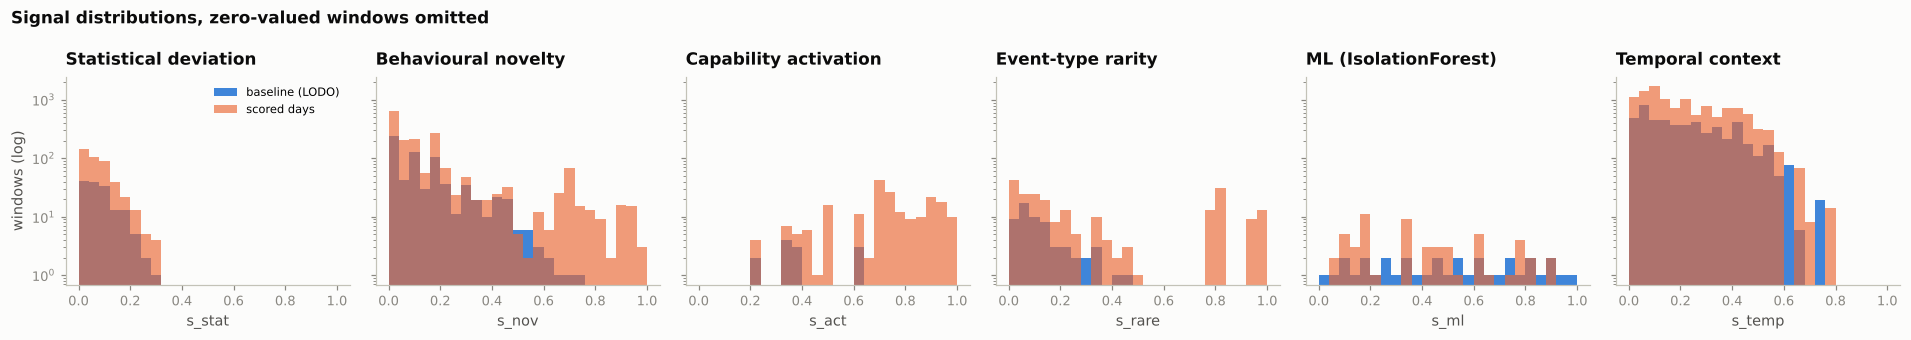

In [35]:
comp = ["s_stat", "s_nov", "s_act", "s_rare", "s_ml", "s_temp"]
titles = {"s_stat": "Statistical deviation", "s_nov": "Behavioural novelty",
          "s_act": "Capability activation", "s_rare": "Event-type rarity", "s_ml": "ML (IsolationForest)", "s_temp": "Temporal context"}
rows = []
for c in comp:
    rows.append({"signal": titles[c],
                 "train zero-rate": f"{(TR[c] <= 1e-9).mean():.1%}",
                 "train P99": round(TR[c].quantile(0.99), 3),
                 "train P99.9": round(TR[c].quantile(0.999), 3),
                 "train max": round(TR[c].max(), 3),
                 "test P99.9": round(TE[c].quantile(0.999), 3),
                 "test max": round(TE[c].max(), 3)})
display(pd.DataFrame(rows).set_index("signal"))

fig, axes = plt.subplots(1, 6, figsize=(17.5, 3.1), sharey=True)
for i, c in enumerate(comp):
    ax = axes[i]
    bins = np.linspace(0, 1, 26)
    ax.hist(TR[TR[c] > 1e-9][c], bins=bins, color=CAT[0], alpha=0.9, label="baseline (LODO)")
    ax.hist(TE[TE[c] > 1e-9][c], bins=bins, color=CAT[1], alpha=0.65, label="scored days")
    ax.set_yscale("log")
    finish(ax, titles[c], None, xlabel=c)
    if i == 0:
        ax.set_ylabel("windows (log)"); ax.legend(fontsize=7.5)
fig.suptitle("Signal distributions, zero-valued windows omitted", x=0.008, ha="left",
             fontsize=11, color=INK, weight="600")
plt.tight_layout(); plt.show()

---
## 18. Risk Scoring

### Fusion

The six signals (statistical, novelty, rarity, activation, ML, temporal context) combine through a weighted **noisy-OR**:

```
risk = 1 - PROD_i ( 1 - w_i * s_i )
```

Two properties make this the right shape for a SOC:

* **Any single strong signal is capped.** A pure volume spike can reach at most `w_stat = 0.55` -
  *Medium*. A user who simply worked late is never promoted to *High* on volume alone. This is the direct
  mitigation for the "unusual but not malicious" failure mode.
* **Corroboration compounds.** A window that is simultaneously novel, activating a new capability, and
  firing a rare event ID drives risk toward 1.

Weights encode how *diagnostic* each signal is, and follow from the section-17 profile: novelty, activation
and rarity are near-zero for almost every normal window and so carry high caps; statistical deviation and
the ML score are noisier and are capped low. Section 20 measures each weight's contribution by ablation.

### Calibration: one threshold per user **and hour**, not one number for everybody

`risk_score` is already bounded and interpretable, so it is not re-scaled. What is derived from data is the
**alert threshold** - and a single global cut is the wrong shape for it. A person's dead 03:00 hour and
their busiest hour are not the same problem: the busy cell produces a wider spread of perfectly normal
scores and should demand more evidence, while a cell that has been silent for a week should need less.

So the threshold is a **surface over `user x hour`**, built from the same leave-one-day-out null. The
difficulty is that one cell holds only 36-42 baseline observations - nowhere near enough to read a 1-in-400
tail from directly, and for most cells every one of those observations is exactly 0. The surface is
therefore built in three levels and **shrunk**:

```
q_global   the target upper quantile over all 7,176 baseline windows          (very stable)
q_user     the same quantile over that user's ~900 baseline windows           (usable)
top_cell   mean of the two largest null scores in that user x hour cell       (noisy)

tau_user  = ( n_user * q_user   + K_USER * q_global ) / ( n_user + K_USER )
tau_cell  = ( n_cell * top_cell + K_CELL * tau_user ) / ( n_cell + K_CELL )
```

`K_CELL = 80` pseudo-observations means a 40-observation cell contributes about a third of its own
threshold and inherits the rest from the user, so one unusually quiet week cannot switch a cell off. The
per-cell multiplier is clamped to `[SHAPE_LO, SHAPE_HI]` of the global level.

**The clamp is set to `[0.70, 1.60]`: every user x hour cell has its own threshold.** The adaptive clamp `[0.70, 1.60]` lowers
the threshold to ~0.42 in every quiet hour, where one weak signal (a single first-ever activation)
is enough to alert. Section 20.5 measures it: the adaptive surface roughly doubles the false positives
and detects no additional attack windows or steps. The machinery is kept so the clamp can be reopened.
That comparison is made on the scored days, so this is a disclosed design choice, not a blind result.

Finally the **level** of the whole surface is calibrated by bisection so that the realised alert rate on the
baseline null equals the configured budget of **0.20 alerts per user per day**. The shape comes from the
per-cell nulls; the level comes from the budget; nothing is fitted on the scored days.

Alongside `risk_score` every window therefore also carries `threshold` and
`risk_ratio = risk_score / threshold`. A window alerts when `risk_ratio >= 1`, and because the ratio is
already normalised per cell it is the right quantity for ranking windows **across** different users.

In [36]:
def fuse(d):
    """Weighted noisy-OR: any one signal is capped by its weight, agreeing signals compound."""
    return 1 - ((1 - W_STAT * d.s_stat) * (1 - W_NOV * d.s_nov) * (1 - W_RARE * d.s_rare) *
                (1 - W_ACT * d.s_act) * (1 - W_ML * d.s_ml) * (1 - W_TEMP * d.s_temp))


def band(x):
    for hi, name in RISK_BANDS:
        if x < hi:
            return name
    return "CRITICAL"


TR["risk"] = fuse(TR)
TE["risk"] = fuse(TE)
TR["risk_level"] = TR.risk.map(band)
TE["risk_level"] = TE.risk.map(band)

# ===================================================================================
# THE THRESHOLD SURFACE - one alert threshold per (user, hour)
# ===================================================================================
# "user-days" is measured from covered windows, not calendar days, so the partial
# first day is counted at its true weight.
n_user_days_train = len(TR) / WINDOWS_PER_DAY
budget_alerts = FP_BUDGET_PER_USER_DAY * n_user_days_train
p_tail = budget_alerts / len(TR)          # the tail probability the budget implies

# Shrinkage pseudo-observations. K_CELL = 80 is about twice a cell's own sample size,
# so a 40-observation cell supplies roughly a third of its threshold and inherits the
# rest from the user. Both constants are chosen for stability, not fitted - section 20
# shows the result is flat across the whole plausible range.
K_CELL, K_USER = 80.0, 300.0
# Per user x hour thresholds (requested): each cell may sit between 0.70x and 1.60x of the calibration
# level, from its own baseline null. Set (1.00, 1.00) for one flat threshold; 20.5 compares both.
SHAPE_LO, SHAPE_HI = 0.85, 1.40   # days20: same TP as 0.70-1.60, 6 fewer FP (section 20.5)


def build_threshold_surface(tr, risk_col="risk", k_cell=None, lo=None, hi=None):
    """Three-level shrunk threshold, then bisect the level to hit the alert budget.

    Returns (threshold Series indexed by (user, hour), reference level, global quantile).
    """
    k_cell = K_CELL if k_cell is None else k_cell
    lo = SHAPE_LO if lo is None else lo
    hi = SHAPE_HI if hi is None else hi
    q_global = max(float(np.quantile(tr[risk_col], 1 - p_tail)), 1e-6)

    gu = tr.groupby("user")[risk_col]
    n_user = gu.size()
    tau_user = (n_user * gu.quantile(1 - p_tail) + K_USER * q_global) / (n_user + K_USER)

    guh = tr.groupby(["user", "hour"])[risk_col]
    # mean of the two largest null scores in the cell - steadier than a bare max
    top_cell = guh.apply(lambda x: float(np.sort(x.to_numpy())[-2:].mean()))
    n_cell = guh.size().reindex(top_cell.index).to_numpy(float)
    tau_u_b = tau_user.reindex(top_cell.index.get_level_values(0)).to_numpy(float)
    tau_cell = (n_cell * top_cell.to_numpy(float) + k_cell * tau_u_b) / (n_cell + k_cell)
    shape = pd.Series(np.clip(tau_cell / q_global, lo, hi), index=top_cell.index)

    # bisect a single global multiplier so the baseline alert count matches the budget
    key = pd.MultiIndex.from_arrays([tr.user, tr.hour])
    sh = shape.reindex(key).to_numpy(float)
    r = tr[risk_col].to_numpy(float)
    lo, hi = 0.05, 20.0
    for _ in range(80):
        mid = 0.5 * (lo + hi)
        if (r >= mid * q_global * sh).sum() > budget_alerts:
            lo = mid
        else:
            hi = mid
    cal = 0.5 * (lo + hi)
    return (cal * q_global * shape).rename("threshold"), cal * q_global, q_global


THRESH, REF_LEVEL, Q_GLOBAL = build_threshold_surface(TR)
ALERT_THRESHOLD = round(float(REF_LEVEL), 3)      # the reference level, for reporting


def attach_threshold(d, surface=THRESH):
    """Give every window its own cell threshold and the ratio that decides the alert."""
    key = pd.MultiIndex.from_arrays([d.user, d.hour])
    d["threshold"] = surface.reindex(key).to_numpy(float)
    d["risk_ratio"] = d.risk / d.threshold
    d["alert"] = d.risk >= d.threshold
    return d


TR = attach_threshold(TR)
TE = attach_threshold(TE)
# every window is judged against ITS OWN user x hour threshold - no single global cut-off
_k = pd.MultiIndex.from_arrays([TE.user, TE.hour])
assert np.allclose(TE.threshold.to_numpy(), THRESH.reindex(_k).to_numpy()), "window threshold != its user x hour cell"
assert (TE.alert == (TE.risk >= TE.threshold)).all()
assert SHAPE_LO == SHAPE_HI or THRESH.nunique() > 1, "threshold surface collapsed to one global value"

print("training (leave-one-day-out) null distribution of risk")
print(TR.risk.describe(percentiles=[.5, .9, .99, .995, .999]).round(4).to_string())
print()
print(f"FP budget                  : {FP_BUDGET_PER_USER_DAY} alerts / user / day")
print(f"                           = {budget_alerts:.1f} alerts over "
      f"{n_user_days_train:.1f} baseline user-days")
print(f"implied tail probability   : {p_tail:.5f}")
print(f"calibration level          : {ALERT_THRESHOLD}  (scales the surface to the FP budget; never used to alert)")
print(f"per-cell thresholds        : min {THRESH.min():.3f}   median {THRESH.median():.3f}   "
      f"max {THRESH.max():.3f}")
print(f"baseline windows alerting  : {int(TR.alert.sum())} "
      f"({TR.alert.sum() / n_user_days_train:.3f} per user-day) - the expected false-positive rate")
print()
print("THE THRESHOLD SURFACE - the risk score each principal must exceed, by UTC hour")
display(THRESH.unstack().round(3))
if THRESH.nunique() == 1:
    print(f"Flat threshold: every user x hour cell uses {THRESH.iloc[0]:.3f} (clamp {SHAPE_LO}-{SHAPE_HI}).")
else:
    print("Low cells are hours where that person is reliably quiet, so less evidence is needed.")
    print("High cells are their busy hours, where normal behaviour is already varied.")
print()
print("risk-band distribution")
bands_order = ["NORMAL", "LOW", "MEDIUM", "HIGH", "CRITICAL"]
cmp_bands = pd.DataFrame({
    "baseline days": TR.risk_level.value_counts().reindex(bands_order).fillna(0).astype(int),
    "scored days": TE.risk_level.value_counts().reindex(bands_order).fillna(0).astype(int)})
cmp_bands["baseline %"] = (cmp_bands["baseline days"] / len(TR)).map(lambda v: f"{v:.2%}")
cmp_bands["scored %"] = (cmp_bands["scored days"] / len(TE)).map(lambda v: f"{v:.2%}")
display(cmp_bands)

training (leave-one-day-out) null distribution of risk
count    7176.0000
mean        0.0318
std         0.0630
min         0.0000
50%         0.0156
90%         0.0539
99%         0.3680
99.5%       0.4222
99.9%       0.5870
max         0.6882

FP budget                  : 0.2 alerts / user / day
                           = 10.0 alerts over 49.8 baseline user-days
implied tail probability   : 0.00139
calibration level          : 0.605  (scales the surface to the FP budget; never used to alert)
per-cell thresholds        : min 0.515   median 0.515   max 0.598
baseline windows alerting  : 9 (0.181 per user-day) - the expected false-positive rate

THE THRESHOLD SURFACE - the risk score each principal must exceed, by UTC hour


hour,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23
user,,,,,,,,,,,,,,,,,,,,,,,,
ananya.sharma,0.515,0.515,0.515,0.515,0.515,0.515,0.515,0.515,0.515,0.515,0.515,0.515,0.515,0.515,0.515,0.515,0.515,0.515,0.515,0.515,0.515,0.515,0.515,0.515
arjun.iyer,0.515,0.515,0.515,0.515,0.515,0.563,0.515,0.515,0.575,0.554,0.591,0.538,0.515,0.515,0.542,0.515,0.515,0.515,0.515,0.515,0.515,0.515,0.515,0.515
kavya.reddy,0.515,0.515,0.515,0.515,0.515,0.515,0.515,0.515,0.515,0.515,0.516,0.568,0.576,0.515,0.515,0.543,0.579,0.515,0.515,0.522,0.515,0.515,0.515,0.515
priya.menon,0.515,0.515,0.515,0.515,0.515,0.515,0.515,0.515,0.515,0.515,0.515,0.515,0.576,0.515,0.515,0.581,0.515,0.515,0.515,0.515,0.515,0.515,0.515,0.515
rahul.verma,0.515,0.515,0.515,0.515,0.515,0.515,0.515,0.515,0.515,0.515,0.515,0.515,0.515,0.515,0.515,0.515,0.515,0.515,0.515,0.515,0.515,0.515,0.515,0.515
rohan.mehta,0.515,0.515,0.515,0.515,0.515,0.574,0.515,0.515,0.515,0.515,0.515,0.515,0.515,0.515,0.539,0.515,0.515,0.561,0.515,0.524,0.515,0.515,0.515,0.531
sneha.patel,0.515,0.515,0.515,0.515,0.515,0.515,0.515,0.515,0.515,0.515,0.523,0.515,0.515,0.515,0.515,0.554,0.515,0.515,0.515,0.515,0.515,0.515,0.515,0.515
vikram.nair,0.515,0.515,0.515,0.515,0.515,0.515,0.515,0.517,0.598,0.595,0.541,0.525,0.555,0.576,0.586,0.515,0.560,0.582,0.515,0.515,0.515,0.515,0.515,0.515


Low cells are hours where that person is reliably quiet, so less evidence is needed.
High cells are their busy hours, where normal behaviour is already varied.

risk-band distribution


,baseline days,scored days,baseline %,scored %
risk_level,,,,
NORMAL,7020,15469,97.83%,97.51%
LOW,126,184,1.76%,1.16%
MEDIUM,26,26,0.36%,0.16%
HIGH,4,16,0.06%,0.10%
CRITICAL,0,169,0.00%,1.07%


### 18.5 Worked example — every 4 Aug 2026 window, scored against its own (user, hour) baseline

Filters the already-scored `TE` table down to `2026-08-04` (the first scoring day, and the day the
ground-truth attack chain begins). No re-scoring happens here — `TE` was already built by
`score_block(BASELINE, TEST_DATES)` in section 18, one row per covered 10-minute window, against the
7-day baseline fit in section 14. This just presents it clearly for a single day.

The `threshold` column is **not** one global cutoff — it's `THRESH[(user, hour)]`, the shrunk per-cell
value from the threshold surface above. Two rows for the same score can sit on opposite sides of
"alert" if the two users (or two hours) have different normal variability.

In [37]:
# ---- 18.5 every 10-minute window on the first scored day, scored against that user's OWN (user, hour) baseline ----
day = TEST_DATES[0]
demo = TE[TE.date == day].copy()

demo["window_start"] = demo.win.dt.strftime("%H:%M")
demo["window_end"] = (demo.win + pd.Timedelta(WINDOW)).dt.strftime("%H:%M")
demo["time_window"] = demo.window_start + " - " + demo.window_end
demo["score"] = demo.risk.round(3)
demo["baseline_threshold"] = demo.threshold.round(3)

out = (demo[["date", "hour", "time_window", "score", "baseline_threshold", "user", "day_type", "p_active", "s_temp", "alert"]]
       .sort_values(["user", "hour", "time_window"])
       .reset_index(drop=True))

print(f"{day}: {len(out):,} ten-minute windows with telemetry coverage, "
      f"across {out.user.nunique()} users.")
print("Windows with no telemetry at all are not shown -- the model does not score silence "
      "as normal or abnormal (see section 18's has_telemetry gating).")
print(f"Per-cell thresholds this day range {out.baseline_threshold.min():.3f} - "
      f"{out.baseline_threshold.max():.3f} .")
print(f"Alerts (score >= that user-hour's own threshold): {int(out.alert.sum())} / {len(out)}\n")

display(out)

2026-08-04: 1,152 ten-minute windows with telemetry coverage, across 8 users.
Windows with no telemetry at all are not shown -- the model does not score silence as normal or abnormal (see section 18's has_telemetry gating).
Per-cell thresholds this day range 0.515 - 0.598 .
Alerts (score >= that user-hour's own threshold): 14 / 1152



,date,hour,time_window,score,baseline_threshold,user,day_type,p_active,s_temp,alert
0,2026-08-04,0,00:00 - 00:10,0.040,0.515,ananya.sharma,weekday,0.596034,0.403966,False
1,2026-08-04,0,00:10 - 00:20,0.000,0.515,ananya.sharma,weekday,0.596034,0.000000,False
2,2026-08-04,0,00:20 - 00:30,0.040,0.515,ananya.sharma,weekday,0.596034,0.403966,False
3,2026-08-04,0,00:30 - 00:40,0.040,0.515,ananya.sharma,weekday,0.596034,0.403966,False
4,2026-08-04,0,00:40 - 00:50,0.040,0.515,ananya.sharma,weekday,0.596034,0.403966,False
...,...,...,...,...,...,...,...,...,...,...
1147,2026-08-04,23,23:10 - 23:20,0.039,0.515,vikram.nair,weekday,0.606532,0.393468,False
1148,2026-08-04,23,23:20 - 23:30,0.039,0.515,vikram.nair,weekday,0.606532,0.393468,False
1149,2026-08-04,23,23:30 - 23:40,0.000,0.515,vikram.nair,weekday,0.606532,0.000000,False
1150,2026-08-04,23,23:40 - 23:50,0.039,0.515,vikram.nair,weekday,0.606532,0.393468,False


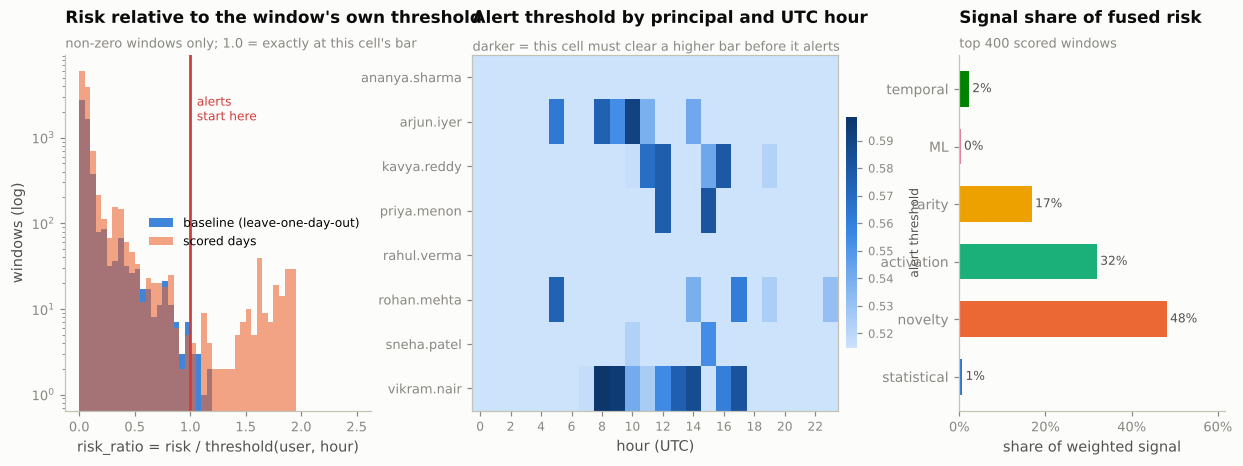

In [38]:
fig = plt.figure(figsize=(13.6, 4.2))
gs = fig.add_gridspec(1, 3, width_ratios=[1.15, 1.45, 1.0], wspace=0.32)

# (1) how far above its own cell threshold each window sits
ax = fig.add_subplot(gs[0, 0])
bins = np.linspace(0, 2.5, 51)
ax.hist(TR[TR.risk > 0].risk_ratio.clip(upper=2.5), bins=bins, color=CAT[0], alpha=0.9,
        label="baseline (leave-one-day-out)")
ax.hist(TE[TE.risk > 0].risk_ratio.clip(upper=2.5), bins=bins, color=CAT[1], alpha=0.6,
        label="scored days")
ax.axvline(1.0, color=STATUS["critical"], lw=1.8)
ax.text(1.06, ax.get_ylim()[1] * 0.5, "alerts\nstart here", color=STATUS["critical"], fontsize=8,
        va="top")
ax.set_yscale("log")
finish(ax, "Risk relative to the window's own threshold",
       "non-zero windows only; 1.0 = exactly at this cell's bar",
       xlabel="risk_ratio = risk / threshold(user, hour)", ylabel="windows (log)")
ax.legend(fontsize=8)

# (2) the threshold surface itself
ax = fig.add_subplot(gs[0, 1])
surf = THRESH.unstack().reindex(PRINCIPALS)
im = ax.imshow(surf.values, aspect="auto", cmap=BLUES)
ax.set_yticks(range(len(surf))); ax.set_yticklabels(surf.index, fontsize=8.5)
ax.set_xticks(range(0, 24, 2)); ax.set_xticklabels(range(0, 24, 2), fontsize=8)
ax.grid(False)
cb = fig.colorbar(im, ax=ax, fraction=0.03, pad=0.02); cb.outline.set_visible(False)
cb.set_label("alert threshold", fontsize=8, color=INK2, labelpad=10)
cb.ax.tick_params(labelsize=7.5)
ax.set_title("Alert threshold by principal and UTC hour", loc="left", color=INK, pad=21)
ax.text(0, 1.012, "darker = this cell must clear a higher bar before it alerts",
        transform=ax.transAxes, color=MUTED, fontsize=8.5)
ax.set_xlabel("hour (UTC)")

# (3) how much each signal contributes to the fused score on the scored days
ax = fig.add_subplot(gs[0, 2])
top = TE.nlargest(400, "risk")
contrib = pd.DataFrame({
    "statistical": W_STAT * top.s_stat, "novelty": W_NOV * top.s_nov,
    "activation": W_ACT * top.s_act, "rarity": W_RARE * top.s_rare, "ML": W_ML * top.s_ml,
    "temporal": W_TEMP * top.s_temp})
share = contrib.sum() / contrib.sum().sum()
ax.barh(range(len(share)), share.values, color=CAT[:len(share)], height=0.62)
ax.set_yticks(range(len(share))); ax.set_yticklabels(share.index, fontsize=9)
ax.xaxis.set_major_formatter(mpl.ticker.PercentFormatter(1.0))
for i, v in enumerate(share.values):
    ax.text(v + 0.008, i, f"{v:.0%}", va="center", fontsize=8, color=INK2)
ax.set_xlim(right=share.max() * 1.28)
finish(ax, "Signal share of fused risk", "top 400 scored windows",
       xlabel="share of weighted signal", xgrid=True)
plt.show()

---
## 19. Explainability

A score without a reason is unusable in a SOC. For every window the engine can reconstruct exactly which
evidence produced the score, because each signal keeps its own contribution table:

* `s_stat` -> the per-feature robust z, with the observed value next to the user's own hourly median and P95;
* `s_nov` -> the individual behavioural values that were new, and their weights;
* `s_act` -> the capability that switched on for the first time;
* `s_rare` -> the Event ID, how often this user saw it in baseline, how often the whole environment did.

Reasons are ranked by their contribution to the fused score, and each is rendered as a sentence that names
the user's own baseline - never a global average.

In [39]:
TE_POS = {int(w): i for i, w in enumerate(TE.wid.to_numpy())}
NOV_BY_WIN  = {k: v for k, v in NOV_TE.groupby(["user", "win"])}
RARE_BY_WIN = {k: v for k, v in RARE_TE.groupby(["user", "win"])}

def feat_text(f):
    return FEATURE_TEXT.get(f, f.replace("_count", "").replace("_", " "))


def explain(user, win, max_reasons=6):
    """Return (header dict, ranked list of reason dicts) for one scored window."""
    row = TE[(TE.user == user) & (TE.win == win)]
    if not len(row):
        return None, []
    row = row.iloc[0]
    pos = TE_POS[int(row.wid)]
    reasons = []

    # --- statistical -------------------------------------------------------------
    z = Z_TE[pos]
    num = BASELINE["num"]
    for j in np.argsort(-z)[:6]:
        if z[j] < Z0:
            break
        f = STAT_FEATURES[j]
        obs = float(W.loc[W.wid == row.wid, f].iloc[0])
        try:
            med = float(np.expm1(num["med_h"].loc[(user, row.hour), f]))
            p95 = float(np.expm1(num["p95_h"].loc[(user, row.hour), f]))
        except KeyError:
            med = p95 = float("nan")
        reasons.append({
            "signal": "statistical", "weight": float(W_STAT * np.clip((z[j] - Z0) / (Z1 - Z0), 0, 1)),
            "text": (f"{feat_text(f)} = {obs:.0f}, against a {user} hour-{row.hour:02d} baseline of "
                     f"median {med:.0f} (P95 {p95:.0f}) - robust z = {z[j]:.1f}")})

    # --- novelty -----------------------------------------------------------------
    nv = NOV_BY_WIN.get((user, win))
    if nv is not None:
        for _, r in nv.sort_values("w", ascending=False).head(8).iterrows():
            scope = "never seen anywhere in the baseline" if r.gcnt == 0 else \
                    f"seen {int(r.gcnt)}x elsewhere in the baseline, but never for {user}"
            reasons.append({
                "signal": "novelty", "weight": float(W_NOV * (1 - np.exp(-r.w / K_NOV))),
                "text": f"new {ITEM_LABEL[r.itype]}: {r.value}  ({scope})"})

    # --- activation ---------------------------------------------------------------
    a = ACT_TE[pos]
    for j in np.argsort(-a)[:4]:
        if a[j] <= 0:
            break
        f = ACT_FEATURES[j]
        obs = float(W.loc[W.wid == row.wid, f].iloc[0])
        reasons.append({
            "signal": "activation", "weight": float(W_ACT * (1 - np.exp(-a[j] / K_ACT))),
            "text": (f"first occurrence for {user}: {feat_text(f)} = {obs:.0f} "
                     f"(zero in all 7 baseline days, every hour)")})

    # --- rarity --------------------------------------------------------------------
    rr = RARE_BY_WIN.get((user, win))
    if rr is not None:
        for _, r in rr.sort_values("w", ascending=False).head(4).iterrows():
            reasons.append({
                "signal": "rarity", "weight": float(W_RARE * (1 - np.exp(-r.w / K_RARE))),
                "text": (f"rare event type {int(r.EventID)} ({EVENT_MEANING.get(int(r.EventID),'?')}) "
                         f"x{int(r.n)} - seen {int(r.ucnt)}x for {user} and {int(r.gcnt)}x across the "
                         f"whole environment in 7 baseline days")})

    if row.s_ml > 0:
        reasons.append({"signal": "ml", "weight": float(W_ML * row.s_ml),
                        "text": (f"multivariate deviation vector sits in the top "
                                 f"{(1 - row.ml_pct) * 100:.2f}% of all baseline windows")})

    if row.s_temp > 0:
        reasons.append({"signal": "temporal", "weight": float(W_TEMP * row.s_temp),
                        "text": (f"activity is unusual for {user} on a {row.day_type} at hour {int(row.hour):02d}:00 UTC "
                                 f"(P(active)={row.p_active:.2f}, temporal score={row.s_temp:.2f})")})
    reasons.sort(key=lambda r: -r["weight"])
    header = {"user": user, "date": row.date, "hour": int(row.hour),
              "window": f"{win:%H:%M}-{(win + pd.Timedelta(WINDOW)):%H:%M}",
              "risk_score": round(float(row.risk), 3), "risk_level": row.risk_level,
              "events": int(row.event_count),
              "signals": {"statistical": round(float(row.s_stat), 3),
                          "novelty": round(float(row.s_nov), 3),
                          "activation": round(float(row.s_act), 3),
                          "rarity": round(float(row.s_rare), 3),
                          "ml": round(float(row.s_ml), 3), "temporal": round(float(row.s_temp), 3)}}
    return header, reasons[:max_reasons]


def print_alert(user, win, max_reasons=6):
    h, rs = explain(user, win, max_reasons)
    if h is None:
        print("no such window"); return
    print("=" * 92)
    print(f"User: {h['user']}    Date: {h['date']}    Window: {h['window']} ({TZ})")
    print(f"Anomaly signals: " + "  ".join(f"{k}={v}" for k, v in h["signals"].items()))
    print(f"Risk Score: {h['risk_score']}    Risk Level: {h['risk_level']}    "
          f"Events in window: {h['events']}")
    print("-" * 92)
    print("Reasons:")
    for i, r in enumerate(rs, 1):
        body = textwrap.fill(r["text"], 86, initial_indent="", subsequent_indent="     ")
        print(f"  {i}. [{r['signal']:<11}] {body}")
    print()


for _, r in TE.nlargest(3, "risk").iterrows():
    print_alert(r.user, r.win)

User: vikram.nair    Date: 2026-08-05    Window: 09:30-09:40 (UTC)
Anomaly signals: statistical=0.0  novelty=0.892  activation=0.95  rarity=0.958  ml=0.0  temporal=0.085
Risk Score: 0.993    Risk Level: CRITICAL    Events in window: 45
--------------------------------------------------------------------------------------------
Reasons:
  1. [rarity     ] rare event type 4720 (User account created) x1 - seen 0x for vikram.nair and 0x across
     the whole environment in 7 baseline days
  2. [rarity     ] rare event type 4728 (Member added to global group) x1 - seen 0x for vikram.nair and
     0x across the whole environment in 7 baseline days
  3. [activation ] first occurrence for vikram.nair: group-membership changes = 1 (zero in all 7 baseline
     days, every hour)
  4. [activation ] first occurrence for vikram.nair: account-management operations = 1 (zero in all 7
     baseline days, every hour)
  5. [activation ] first occurrence for vikram.nair: discovery-tool executions = 1 (zer

---
## 20. Evaluation

`GROUND_TRUTH.md` ships with the scenario, so real metrics can be computed instead of manufactured ones.
The file is **parsed**, not transcribed: the attack timeline, the IOC lists and the red-herring table are all
read out of it, so the evaluation cannot drift from the scenario definition.

### How episodes are formed

The timeline is a flat list of atomic events. They are grouped into attack steps (episodes) by clustering each
actor's rows with a 12-minute gap, and two documented adjustments:

* the credential-spray row is attributed to **`SYSTEM` on DC-01** in the file, but the accounts that actually
  experience it are the sprayed users - those are recovered from the data (the `4625` failures from the spray
  source inside that window);
* the two beacon rows carry their duration in the Details column (`49 attempts, 4h`), so those episodes are
  extended accordingly instead of being treated as instants.

### How a window is labelled positive

A `(user, 10-minute window)` cell is **malicious** when `GROUND_TRUTH.md` says malicious activity by that user
happened in it. Nothing else is used: no detector output, no generic IOC matching. Three kinds of row:

| Source | What the file says | Cells it produces |
|---|---|---|
| **timeline** | one row per attack event, with a timestamp | the window that timestamp falls in (scored actors only) |
| **spray** | ONE summary row, actor `SYSTEM`: "10 attempts against 6 accounts" | for each sprayed account, only the windows where it actually received an attempt from the attacker's external address |
| **beacon** (only if `BEACON_EXPANSION = True`) | ONE row with a duration: "Beacon to IP:443 (49 attempts, 4h)" | every window in that span where the actor connects to **that** beacon address |

Timeline rows the generator marks *"no evidence emitted"* did not happen in the data and are skipped.
A labelled cell with no attributable event is kept: it is a genuine, unavoidable miss.

**Why not count only the timeline timestamps (≈43 cells)?** That count is wrong in both directions. A beacon is
one row in the file but dozens of windows of real C2 traffic, which the file itself declares ("49 attempts, 4h").
And spreading the spray row across *every* victim × *every* window of the spray marks cells where that account
received no attempt at all. Section 20.7 prints that naive count next to the real one so the difference is visible.


In [40]:
%%requires_ground_truth
gt_text = open(GT_PATH, "r", encoding="utf-8").read()

# ---- 1. timeline table --------------------------------------------------------------
# NOTE: the red-herring table further down the file has the same column shape, so the timeline
# is sliced out by heading first - otherwise benign planted activity would be parsed as attack.
tl_block = gt_text.split("## Timeline")[1].split("## Indicators of Compromise")[0]
tl_rows = []
for line in tl_block.splitlines():
    m = re.match(r"^\|\s*(\d{4}-\d{2}-\d{2} \d{2}:\d{2}:\d{2}) UTC\s*\|([^|]*)\|([^|]*)\|([^|]*)\|(.*)\|\s*$",
                 line)
    if m:
        tl_rows.append({"ts_utc": pd.Timestamp(m.group(1), tz="UTC"),
                        "actor": m.group(2).strip(), "system": m.group(3).strip(),
                        "event_type": m.group(4).strip(), "details": m.group(5).strip()})
TL = pd.DataFrame(tl_rows).sort_values("ts_utc").reset_index(drop=True)
TL["ts"] = TL.ts_utc.dt.tz_convert(TZ)

# ---- 2. IOC lists --------------------------------------------------------------------
ioc_block = gt_text.split("## Indicators of Compromise")[1].split("## Red Herrings")[0]
ioc_lines = [l.strip("- ").strip() for l in ioc_block.splitlines() if l.startswith("- ")]
IOC_IPS, IOC_DOMAINS, IOC_CMDS = set(), set(), set()
KNOWN_ACCOUNTS = {str(u).lower() for u in raw.attr_user.dropna().unique()}
for l in ioc_lines:
    if l.startswith("`"):
        IOC_CMDS.add(l.strip("`").lower())
        continue
    tok = l.split(" (")[0].strip().strip("`")
    host = tok.split(":")[0]
    if re.fullmatch(r"\d+\.\d+\.\d+\.\d+", host):
        if not re.match(PRIV_PAT, host):          # internal addresses are legitimate infrastructure
            IOC_IPS.add(host)
    elif "." in host and " " not in host and host.lower() not in KNOWN_ACCOUNTS:
        IOC_DOMAINS.add(host.lower())                                # user names are not domains
UNIQUE_CHANGE_EIDS = {4720, 4722, 4724, 4726, 4728, 4732, 4738, 4697, 4698, 1102}

# ---- 3. red herrings ------------------------------------------------------------------
rh_block = gt_text.split("## Red Herrings")[1]
rh_rows = []
for line in rh_block.splitlines():
    m = re.match(r"^\|\s*(\d{4}-\d{2}-\d{2} \d{2}:\d{2}:\d{2}) UTC\s*\|([^|]*)\|([^|]*)\|([^|]*)\|(.*)$",
                 line)
    if m:
        rh_rows.append({"ts": pd.Timestamp(m.group(1), tz="UTC").tz_convert(TZ),
                        "user": m.group(2).strip(), "system": m.group(3).strip(),
                        "activity": m.group(4).strip()})
RH = pd.DataFrame(rh_rows)

# ---- sanity checks: fail loudly instead of producing a wrong confusion matrix ----------
assert len(TL), f"no timeline rows parsed from {GT_PATH} - check the '## Timeline' table format"
first_test = pd.Timestamp(TEST_DATES[0], tz=TZ)
last_test = pd.Timestamp(TEST_DATES[-1], tz=TZ) + pd.Timedelta(days=1)
in_train = TL[TL.ts < first_test]
assert not len(in_train), (
    f"{len(in_train)} ground-truth events fall inside the TRAINING period (first: {in_train.ts.min()}). "
    "The baseline would have learned the attack as normal - move TRAIN_DATES/TEST_DATES in section 01.")
after = TL[TL.ts >= last_test]
if len(after):
    print(f"WARNING - {len(after)} ground-truth events fall after the last scored day; they cannot be detected")
unscored = sorted(set(TL.actor) - set(PRINCIPALS))
if unscored:
    print(f"NOTE - ground-truth actors that are not scored principals: {unscored}")

print(f"parsed from GROUND_TRUTH.md: {len(TL)} timeline events, {len(RH)} red-herring events")
print(f"  external IOC addresses : {sorted(IOC_IPS)}")
print(f"  IOC domains            : {sorted(IOC_DOMAINS)}")
print(f"  IOC command lines      : {len(IOC_CMDS)}")
print()
print("attack summary as declared by the scenario:")
for l in gt_text.split("## Attack Summary")[1].split("## Timeline")[0].splitlines():
    if re.match(r"^\d+\.", l.strip()):
        print("   " + l.strip()[:118])

NOTE - ground-truth actors that are not scored principals: ['SYSTEM']
parsed from GROUND_TRUTH.md: 409 timeline events, 8 red-herring events
  external IOC addresses : ['185.220.101.34', '198.51.100.164', '198.51.100.44', '198.51.100.83', '203.0.113.102', '203.0.113.47', '203.0.113.55', '91.199.212.132', '93.184.220.29', '93.184.221.240']
  IOC domains            : ['_ldap._tcp.dc._msdcs.corp.local', 'c2-operator-2.attacker.net', 'cdn-metrics-edge.net', 'k7.sync-check.corp-update.example', 'sync-check.corp-update.example']
  IOC command lines      : 46

attack summary as declared by the scenario:
   1. **arjun.iyer** on **PC-003**: Off-hours remote interactive logon from an external address using stolen credentials
   2. **arjun.iyer** on **PC-003**: Host and domain discovery from the compromised workstation
   3. **SYSTEM** on **DC-01**: Password spray against domain accounts from the attacker's infrastructure
   4. **rahul.verma** on **FILE-01**: Network logon to the file server from

In [41]:
%%requires_ground_truth
# ---- episode construction --------------------------------------------------------
GAP = pd.Timedelta("12min")
spray_mask = TL.event_type.str.contains("Spray", case=False)


def spray_extent(t0):
    """The file collapses the spray into one row attributed to SYSTEM. Its real victims and its
    real duration are recovered from the authentication events coming from the spray source."""
    lo, hi = t0 - pd.Timedelta("2min"), t0 + pd.Timedelta("30min")
    v = ev[ev.EventID.isin([4625, 4624]) & ev.ts.between(lo, hi) & ev.src_ip.isin(IOC_IPS)]
    if not len(v):
        return [], t0
    return sorted(v.user.unique()), v.ts.max() + pd.Timedelta("20s")


episodes = []
for actor, g in TL.groupby("actor"):
    g = g.sort_values("ts")
    cluster, prev = [], None
    for _, r in g.iterrows():
        if prev is not None and r.ts - prev > GAP:
            episodes.append(cluster); cluster = []
        cluster.append(r); prev = r.ts
    if cluster:
        episodes.append(cluster)

EP_rows = []
for cl in episodes:
    a = cl[0]["actor"]
    # pad by a few seconds: the file records whole seconds, the log records sub-second times
    start = min(r["ts"] for r in cl) - pd.Timedelta("30s")
    end = max(r["ts"] for r in cl) + pd.Timedelta("30s")
    for r in cl:                                    # extend documented beacon durations
        dur = re.search(r"(\d+)\s*attempts,\s*(\d+)h", str(r["details"]))
        if dur:
            end = max(end, r["ts"] + pd.Timedelta(hours=int(dur.group(2))))
    if any(re.search("Spray", str(r["event_type"])) for r in cl):
        users, spray_end = spray_extent(start)
        end = max(end, spray_end)
    else:
        users = [a]
    EP_rows.append({"users": users, "start": start, "end": end,
                    "systems": sorted({r["system"] for r in cl}),
                    "types": sorted({r["event_type"] for r in cl}),
                    "n_events": len(cl),
                    "desc": "; ".join(sorted({str(r["event_type"]).replace("_", " ") for r in cl}))})
EP = pd.DataFrame(EP_rows).sort_values("start").reset_index(drop=True)
EP.insert(0, "step", range(1, len(EP) + 1))
print(f"episodes reconstructed: {len(EP)} (scenario declares 20)")
display(EP.assign(start=EP.start.dt.strftime("%m-%d %H:%M"), end=EP.end.dt.strftime("%m-%d %H:%M"),
                  users=EP.users.map(lambda u: ", ".join(u)[:44]),
                  systems=EP.systems.map(", ".join))[["step", "start", "end", "users", "systems",
                                                      "n_events", "desc"]])

episodes reconstructed: 144 (scenario declares 20)


,step,start,end,users,systems,n_events,desc
0,1,08-04 19:44,08-04 19:45,ananya.sharma,PC-001,1,Logon
1,2,08-04 20:50,08-04 20:53,ananya.sharma,PC-001,4,Connection; Process
2,3,08-04 21:39,08-04 21:40,arjun.iyer,PC-003,1,Logon
3,4,08-04 21:54,08-04 21:56,arjun.iyer,PC-003,5,Process
4,5,08-04 22:34,08-04 22:40,"ananya.sharma, kavya.reddy, rahul.verma, roh",DC-01,1,Credential Spray
...,...,...,...,...,...,...,...
139,140,08-17 02:10,08-17 02:12,vikram.nair,PC-006,3,Explicit Credentials; Logon; Process
140,141,08-17 04:30,08-17 04:32,priya.menon,PC-007,3,Connection; Process; Scheduled Task Created
141,142,08-17 08:30,08-17 08:32,sneha.patel,PC-008,3,Connection; Process; Service Installed
142,143,08-17 11:30,08-17 11:32,ananya.sharma,PC-001,3,Account Created; Group Member Added; Process


In [42]:
%%requires_ground_truth
# ---- 20.0 the label: which (user, 10-minute window) cells are malicious --------------------
# Built ONLY from what GROUND_TRUTH.md declares (see the markdown above): timeline / spray / beacon.
BEACON_RE = re.compile(r"Beacon to (\d+\.\d+\.\d+\.\d+):\d+\s*\((\d+)\s*attempts,\s*(\d+)\s*h\)")
SKIP_RE = re.compile(r"no evidence emitted", re.I)


def step_of(user, ts):
    m = EP[EP.users.map(lambda us: user in us) & (EP.start <= ts) & (EP.end >= ts)]
    return int(m.step.iloc[0]) if len(m) else -1


lab_rows, skipped, unscored, beacon_report = [], [], [], []
for k, r in TL.iterrows():
    if SKIP_RE.search(str(r.details)):
        skipped.append(f"{r.ts:%m-%d %H:%M} {r.actor} {r.event_type}"); continue
    if spray_mask.loc[k]:                       # summary row -> recover victims from the data
        lo, hi = r.ts - pd.Timedelta("2min"), r.ts + pd.Timedelta("30min")
        v = ev[ev.EventID.isin([4625, 4624]) & ev.ts.between(lo, hi) & ev.src_ip.isin(IOC_IPS)]
        assert len(v), f"spray row at {r.ts} matched no authentication from an IOC address"
        for (u, w), g in v.groupby(["user", "win"]):
            lab_rows.append({"tl_row": k, "source": "spray", "user": u, "win": w, "ts": g.ts.min()})
        continue
    if r.actor not in PRINCIPALS:
        unscored.append(f"{r.ts:%m-%d %H:%M} {r.actor} {r.event_type}"); continue
    lab_rows.append({"tl_row": k, "source": "timeline", "user": r.actor,
                     "win": r.ts.floor(WINDOW), "ts": r.ts})
    b = BEACON_RE.search(str(r.details))
    if b and BEACON_EXPANSION:                  # declared duration -> every window it touches
        ip, attempts, hours = b.group(1), int(b.group(2)), int(b.group(3))
        hit = ev[(ev.user == r.actor) & (ev.dst_ip == ip) &
                 ev.ts.between(r.ts - pd.Timedelta("30s"),
                            r.ts + pd.Timedelta(hours=hours) + pd.Timedelta(WINDOW))]   # file rounds durations to whole hours
        for w, g in hit.groupby("win"):
            lab_rows.append({"tl_row": k, "source": "beacon", "user": r.actor, "win": w, "ts": g.ts.min()})
        beacon_report.append(f"{r.actor} -> {ip}: file declares {attempts} attempts over {hours}h; "
                             f"data shows {len(hit)} connections in {hit.win.nunique()} windows")

LABELS = pd.DataFrame(lab_rows)
LABELS["step"] = [step_of(u, t) for u, t in zip(LABELS.user, LABELS.ts)]
PRIORITY = {"timeline": 0, "spray": 1, "beacon": 2}          # a cell counts once, under its strongest source
CELLS = (LABELS.assign(p=LABELS.source.map(PRIORITY)).sort_values("p")
         .groupby(["user", "win"])
         .agg(source=("source", "first"), steps=("step", lambda s: sorted({int(x) for x in s if x > 0})))
         .reset_index())

TE["win_end"] = TE.win + pd.Timedelta(WINDOW)
te_key = pd.MultiIndex.from_frame(TE[["user", "win"]])
cell_key = pd.MultiIndex.from_frame(CELLS[["user", "win"]])
outside = CELLS[~cell_key.isin(te_key)]
assert not len(outside), f"labelled cells outside the scored windows:\n{outside}"
TE["is_attack"] = te_key.isin(cell_key)
steps_by_cell = dict(zip(zip(CELLS.user, CELLS.win), CELLS.steps))
TE["attack_steps"] = [list(steps_by_cell.get(c, [])) for c in zip(TE.user, TE.win)]
CELLS = CELLS.merge(TE[["user", "win", "event_count"]], on=["user", "win"], how="left")
episode_evidence = {int(s): int((LABELS.step == s).sum()) for s in EP.step}

TE["is_red_herring"] = False
for _, r in RH.iterrows():
    m = (TE.user == r.user) & (TE.win <= r.ts) & (TE.win_end > r.ts)
    TE.loc[m, "is_red_herring"] = True

# ---- integrity checks -------------------------------------------------------------------
assert not TE.duplicated(["user", "win"]).any(), "duplicate (user, window) rows in TE"
assert TE.is_attack.sum() == len(CELLS), "label count does not match the labelled cells"
assert TE.loc[TE.is_attack, "date"].isin(TEST_DATES).all(), "an attack label landed outside the test days"

# ONE population for every metric: all covered test windows. An empty window has risk 0 and
# can never alert; a labelled empty window is a genuine miss and must stay in the denominator.
ACTIVE = TE
N_USER_DAYS_TEST = len(TE) / WINDOWS_PER_DAY

print("GROUND-TRUTH LABEL  (user x 10-minute window), built from GROUND_TRUTH.md only")
by = CELLS.source.value_counts()
print(f"  timeline windows          : {by.get('timeline', 0):>3}   ({(~TL.index.isin(LABELS.tl_row)).sum()} rows not used: "
      f"{len(skipped)} 'no evidence emitted', {len(unscored)} actor not scored, spray handled below)")
print(f"  spray victim windows      : {by.get('spray', 0):>3}")
print(f"  beacon windows            : {by.get('beacon', 0):>3}   (beyond the beacon's own timeline row)")
print(f"  TOTAL malicious cells     : {len(CELLS):>3}   (BEACON_EXPANSION = {BEACON_EXPANSION})")
print(f"  of which hold no attributable event (unavoidable misses): {int((CELLS.event_count == 0).sum())}")
for b in beacon_report:
    print("  beacon check: " + b)
for s_ in skipped:
    print("  skipped (no evidence emitted): " + s_)
for s_ in unscored:
    print("  not scored (actor has no baseline): " + s_)
print(f"\nlabelled red-herring windows : {int(TE.is_red_herring.sum())}")
print(f"scored windows (population)  : {len(TE):,}")
print("\nmalicious cells per principal and source:")
display(CELLS.pivot_table(index="user", columns="source", values="win", aggfunc="count", fill_value=0))


GROUND-TRUTH LABEL  (user x 10-minute window), built from GROUND_TRUTH.md only
  timeline windows          : 150   (1 rows not used: 1 'no evidence emitted', 0 actor not scored, spray handled below)
  spray victim windows      :   7
  beacon windows            :   0   (beyond the beacon's own timeline row)
  TOTAL malicious cells     : 157   (BEACON_EXPANSION = False)
  of which hold no attributable event (unavoidable misses): 4
  skipped (no evidence emitted): 08-08 04:25 vikram.nair Workstation_Lock

labelled red-herring windows : 6
scored windows (population)  : 15,864

malicious cells per principal and source:


source,spray,timeline
user,,
ananya.sharma,1,15
arjun.iyer,0,34
kavya.reddy,1,15
priya.menon,0,20
rahul.verma,1,14
rohan.mehta,2,20
sneha.patel,1,14
vikram.nair,1,18


In [43]:
%%requires_ground_truth
# ---- window-level metrics ----------------------------------------------------------
y = ACTIVE.is_attack.to_numpy()
print("DISCRIMINATION (all active scored windows)")
print(f"  positives / total : {y.sum()} / {len(y)}  ({y.mean():.2%} prevalence)")
rows = []
for c, lab in [("s_stat", "statistical only"), ("s_nov", "novelty only"),
               ("s_act", "activation only"), ("s_rare", "rarity only"), ("s_ml", "ML only"), ("s_temp", "temporal-context only"),
               ("risk", "FUSED risk_score (global scale)"),
               ("risk_ratio", "FUSED risk / per-cell threshold")]:
    rows.append({"model": lab,
                 "PR-AUC": average_precision_score(y, ACTIVE[c]),
                 "ROC-AUC": roc_auc_score(y, ACTIVE[c])})
for name, (_, te_pct) in ml_models.items():
    s = np.clip((pd.Series(te_pct, index=TE.index).loc[ACTIVE.index] - 0.995) / 0.005, 0, 1)
    rows.append({"model": f"[ML] {name}", "PR-AUC": average_precision_score(y, s),
                 "ROC-AUC": roc_auc_score(y, s)})
display(pd.DataFrame(rows).set_index("model").round(4))

DISCRIMINATION (all active scored windows)
  positives / total : 157 / 15864  (0.99% prevalence)


,PR-AUC,ROC-AUC
model,,
statistical only,0.0101,0.4930
novelty only,0.7057,0.9066
activation only,0.7111,0.9030
rarity only,0.4883,0.7428
ML only,0.0099,0.4982
temporal-context only,0.0199,0.6883
FUSED risk_score (global scale),0.8166,0.9474
FUSED risk / per-cell threshold,0.8210,0.9472
[ML] IsolationForest,0.0099,0.4982


In [44]:
%%requires_ground_truth
# ---- operating point ----------------------------------------------------------------
def sweep(mult):
    """Sweep a multiplier on the whole threshold surface. mult = 1.0 is the operating point."""
    al = ACTIVE[ACTIVE.risk_ratio >= mult]

    tp = int(al.is_attack.sum())
    fp = len(al) - tp

    n_pos = int(ACTIVE.is_attack.sum())
    n_neg = len(ACTIVE) - n_pos

    # Explicit true negatives
    fn = n_pos - tp
    tn = n_neg - fp
    

    rec = tp / max(n_pos, 1)
    prec = tp / max(len(al), 1)

    f1 = 0 if prec + rec == 0 else 2 * prec * rec / (prec + rec)

    det = [int(r.step) for _, r in EP.iterrows()
           if ((TE.user.isin(r.users)) & (TE.win < r.end) & (TE.win_end > r.start) &
               (TE.risk_ratio >= mult)).any()]

    return {
        "threshold x": round(mult, 2),
        "alerts": len(al),
        "TP": tp,
        "FP": fp,
        "FN":fn,
        "TN": tn,
        "precision": prec,
        "recall": rec,
        "F1": f1,
        "accuracy": (tp + tn) / len(ACTIVE),
        "balanced_acc": 0.5 * (
            rec + tn / max(n_neg, 1)
        ),
        "steps_detected": f"{len(det)}/{len(EP)}",
        "FP/user/day": fp / N_USER_DAYS_TEST,
        "red_herring_alerts": int(al.is_red_herring.sum())
    }



sw = pd.DataFrame([sweep(m) for m in [0.5, 0.6, 0.7, 0.8, 0.9, 1.0, 1.1, 1.25, 1.5, 2.0]])
# display(sw.set_index("threshold x").round(4))
print("threshold x 1.0 is the surface exactly as calibrated on the baseline null.")
print()

OP = sweep(1.0)
print()
print("=" * 78)
print("OPERATING POINT  (threshold calibrated on the baseline null; all covered test windows)")
print("=" * 78)
for k in ["alerts", "TP", "FP","FN","TN", "precision", "recall", "F1", "accuracy", "balanced_acc",
          "steps_detected", "FP/user/day", "red_herring_alerts"]:
    v = OP[k]
    print(f"  {k:<20} {v if isinstance(v, str) else (f'{v:.3f}' if isinstance(v, float) else v)}")
print()
prec_c, rec_c, thr_c = precision_recall_curve(y, ACTIVE.risk_ratio)
f1s = np.divide(2 * prec_c * rec_c, prec_c + rec_c, out=np.zeros_like(prec_c), where=(prec_c + rec_c) > 0)
best = int(np.argmax(f1s))
print(f"  best achievable F1 on this data: {f1s[best]:.3f} at threshold x "
      f"{thr_c[min(best, len(thr_c)-1)]:.3f}  (precision {prec_c[best]:.3f}, "
      f"recall {rec_c[best]:.3f})")

threshold x 1.0 is the surface exactly as calibrated on the baseline null.


OPERATING POINT  (threshold calibrated on the baseline null; all covered test windows)
  alerts               198
  TP                   134
  FP                   64
  FN                   23
  TN                   15643
  precision            0.677
  recall               0.854
  F1                   0.755
  accuracy             0.995
  balanced_acc         0.925
  steps_detected       126/144
  FP/user/day          0.581
  red_herring_alerts   3

  best achievable F1 on this data: 0.796 at threshold x 1.641  (precision 0.955, recall 0.682)


### 20.1 Ground-truth window map

The question this table answers is the direct one: **take every event listed in `GROUND_TRUTH.md`, work out
which 10-minute window it lands in, and say whether that window alerted.**

Two columns of nuance:

* `scored_user` - the file blames the credential spray on `SYSTEM` on `DC-01`, which is not a principal
  anyone baselines. The accounts that actually experience it are the sprayed users, recovered from the
  `4625` failures coming from the spray source, so that one ground-truth row expands to several scored users
  and the best of them is reported.
* `detected_pm1` - some ground-truth events sit a few seconds before a window boundary while the telemetry
  they generate lands just after it. The strict `detected` column requires the alert in the exact window;
  this one allows the neighbouring window either side.

Rows for the two beaconing implants map to their *first* window only - the ground-truth file records one
line for an activity that then runs for hours. The per-episode table further down covers their full duration.

In [45]:
%%requires_ground_truth
gt_rows = []
for k, r in TL.iterrows():
    cells = LABELS[LABELS.tl_row == k][["user", "win"]].drop_duplicates()
    exact = TE.merge(cells, on=["user", "win"])
    near = TE[TE.user.isin(cells.user) &
              (TE.win >= (cells.win.min() - pd.Timedelta(WINDOW) if len(cells) else r.ts)) &
              (TE.win <= (cells.win.max() + pd.Timedelta(WINDOW) if len(cells) else r.ts))]
    gt_rows.append({
        "gt_time_utc": r.ts.strftime("%m-%d %H:%M:%S"), "actor": r.actor, "system": r.system,
        "gt_event": r.event_type,
        "labelled_cells": len(cells) if len(cells) else ("skipped" if SKIP_RE.search(str(r.details))
                                                           else "not scored"),
        "events": int(exact.event_count.sum()),
        "risk": round(float(exact.risk.max()), 3) if len(exact) else 0.0,
        "level": band(float(exact.risk.max()) if len(exact) else 0.0),
        "detected": "YES" if len(exact) and exact.alert.any() else "no",
        "detected_pm1": "YES" if len(near) and near.alert.any() else "no"})
GT_MAP = pd.DataFrame(gt_rows)
display(GT_MAP)
used = GT_MAP[GT_MAP.labelled_cells.map(lambda x: isinstance(x, int))]
print(f"ground-truth timeline rows            : {len(GT_MAP)}  ({len(used)} produce labelled cells)")
print(f"  in a window that alerted (exact)    : {int((used.detected == 'YES').sum())}")
print(f"  alerted within +/- one window       : {int((used.detected_pm1 == 'YES').sum())}")


,gt_time_utc,actor,system,gt_event,labelled_cells,events,risk,level,detected,detected_pm1
0,08-04 19:45:13,ananya.sharma,PC-001,Logon,1,3,0.868,CRITICAL,YES,YES
1,08-04 20:51:11,ananya.sharma,PC-001,Process,1,22,0.905,CRITICAL,YES,YES
2,08-04 20:51:24,ananya.sharma,PC-001,Process,1,22,0.905,CRITICAL,YES,YES
3,08-04 20:51:58,ananya.sharma,PC-001,Process,1,22,0.905,CRITICAL,YES,YES
4,08-04 20:52:36,ananya.sharma,PC-001,Connection,1,22,0.905,CRITICAL,YES,YES
...,...,...,...,...,...,...,...,...,...,...
404,08-17 11:31:50,ananya.sharma,PC-001,Account_Created,1,25,0.986,CRITICAL,YES,YES
405,08-17 11:32:22,ananya.sharma,PC-001,Group_Member_Added,1,25,0.986,CRITICAL,YES,YES
406,08-17 17:31:28,rohan.mehta,PC-002,Process,1,15,0.945,CRITICAL,YES,YES
407,08-17 17:31:46,rohan.mehta,PC-002,Process,1,15,0.945,CRITICAL,YES,YES


ground-truth timeline rows            : 409  (408 produce labelled cells)
  in a window that alerted (exact)    : 364
  alerted within +/- one window       : 367


The same picture at **window** granularity rather than event granularity - several ground-truth events share
a window, so this is the list of distinct `(user, 10-minute window)` cells the ground truth points at, and
whether each one produced an alert.

In [46]:
%%requires_ground_truth
GTW = CELLS.merge(TE[["user", "win", "risk", "threshold", "risk_ratio", "risk_level", "alert"]],
                  on=["user", "win"], how="left")
GTW["category"] = GTW.source
GTW["detected"] = np.where(GTW.alert, "YES", "no")
GTW["detected_pm1"] = ["YES" if TE[(TE.user == r.user) & (TE.win >= r.win - pd.Timedelta(WINDOW)) &
                                   (TE.win <= r.win + pd.Timedelta(WINDOW))].alert.any() else "no"
                       for _, r in GTW.iterrows()]
GTW = GTW.sort_values("win").reset_index(drop=True)
core = GTW[GTW.category == "timeline"]
hit = int((GTW.detected == "YES").sum())
brk = (GTW.groupby("category")
       .agg(cells=("detected", "size"), detected=("detected", lambda x: int((x == "YES").sum())))
       .assign(rate=lambda d: (d.detected / d.cells).map("{:.0%}".format)))
display(brk)
print(f"malicious cells alerted: {hit}/{len(GTW)}   "
      f"(timeline {int((core.detected == 'YES').sum())}/{len(core)})")
print("\nthe malicious cells that did NOT alert:")
display(GTW[GTW.detected == "no"].assign(win=lambda d: d.win.dt.strftime("%m-%d %H:%M"),
                                        risk=lambda d: d.risk.round(3))
        [["user", "win", "category", "steps", "event_count", "risk", "threshold", "detected_pm1"]])


,cells,detected,rate
category,,,
spray,7,7,100%
timeline,150,127,85%


malicious cells alerted: 134/157   (timeline 127/150)

the malicious cells that did NOT alert:


,user,win,category,steps,event_count,risk,threshold,detected_pm1
11,rahul.verma,08-04 23:10,timeline,[6],6.0,0.028,0.514615,no
20,sneha.patel,08-05 13:50,timeline,[14],0.0,0.000,0.514615,no
39,arjun.iyer,08-06 18:30,timeline,[33],0.0,0.000,0.514615,no
40,arjun.iyer,08-06 20:50,timeline,[34],2.0,0.030,0.514615,no
43,kavya.reddy,08-07 02:30,timeline,[37],29.0,0.340,0.514615,no
45,arjun.iyer,08-07 03:50,timeline,[39],6.0,0.193,0.514615,YES
52,arjun.iyer,08-07 10:40,timeline,[45],20.0,0.004,0.591086,no
59,vikram.nair,08-08 02:50,timeline,[52],0.0,0.000,0.514615,no
60,vikram.nair,08-08 04:40,timeline,[54],0.0,0.000,0.514615,no
62,arjun.iyer,08-08 07:00,timeline,[56],3.0,0.039,0.514615,YES


### 20.7 Confusion matrix - all users, `(user, 10-minute window)`

* **Population:** every covered test window (`TE`). Same population as every other metric in section 20.
* **Actual:** `TE.is_attack` from section 20.0 - built only from `GROUND_TRUTH.md` (timeline + spray + beacon).
* **Predicted:** `TE.alert` = `risk >= threshold`.

The cell checks itself against the operating point (20.1) and stops the notebook if they disagree. It also
prints the naive "timeline timestamps only" count and exactly which cells make the two numbers differ.

CONFUSION MATRIX - all users, (user, 10-minute window), covered test windows
                     predicted Normal   predicted Attack
actual Normal                15,643                 64
actual Attack                    23                134

  precision    0.6768
  recall       0.8535
  specificity  0.9959
  F1           0.7549
  accuracy     0.9945
  FP per user-day 0.581   (budget 0.2)
  windows: 15,864   malicious cells: 157   alerts: 198


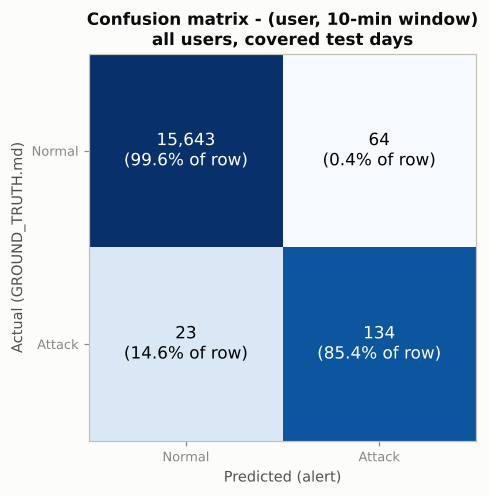


where the actual-attack row comes from:


,malicious_cells,TP,FN
category,,,
spray,7,7,0
timeline,150,127,23
TOTAL,157,134,23


naive 'timeline timestamps only' count : 163
  + beacon windows the file declares by duration : 0
  - cells in the naive count that are not malicious : 6


      ananya.sharma  08-04 22:40  events=0   sprayed account received no attempt in this window
      kavya.reddy    08-04 22:40  events=1   sprayed account received no attempt in this window
      rahul.verma    08-04 22:40  events=8   sprayed account received no attempt in this window
      sneha.patel    08-04 22:40  events=18  sprayed account received no attempt in this window
      vikram.nair    08-04 22:40  events=1   sprayed account received no attempt in this window
      vikram.nair    08-08 04:20  events=0   'no evidence emitted' row
  = malicious cells used here : 157


In [47]:
%%requires_ground_truth
from sklearn.metrics import confusion_matrix


def cm_counts(y_true, y_pred):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[False, True]).ravel()
    p, r = tp / max(tp + fp, 1), tp / max(tp + fn, 1)
    return {"TP": int(tp), "FP": int(fp), "FN": int(fn), "TN": int(tn),
            "precision": p, "recall": r, "specificity": tn / max(tn + fp, 1),
            "F1": 0 if p + r == 0 else 2 * p * r / (p + r), "accuracy": (tp + tn) / (tp + tn + fp + fn)}


y_true_cm = TE.is_attack.to_numpy(bool)
y_pred_cm = TE.alert.to_numpy(bool)
CM = confusion_matrix(y_true_cm, y_pred_cm, labels=[False, True])
CMR = cm_counts(y_true_cm, y_pred_cm)

# guard rails - a stale or mismatched matrix stops the notebook here
assert CM.sum() == len(TE), "confusion matrix does not cover every scored window"
assert CMR["TP"] + CMR["FN"] == len(CELLS), "positives in the matrix != malicious cells in the label"
assert all(CMR[k] == OP[k] for k in ("TP", "FP", "FN", "TN")), (CMR, OP)

print("=" * 70)
print("CONFUSION MATRIX - all users, (user, 10-minute window), covered test windows")
print("=" * 70)
print(f"                     predicted Normal   predicted Attack")
print(f"actual Normal        {CMR['TN']:>14,}   {CMR['FP']:>16,}")
print(f"actual Attack        {CMR['FN']:>14,}   {CMR['TP']:>16,}")
print()
for k in ["precision", "recall", "specificity", "F1", "accuracy"]:
    print(f"  {k:<12} {CMR[k]:.4f}")
print(f"  FP per user-day {CMR['FP'] / N_USER_DAYS_TEST:.3f}   (budget {FP_BUDGET_PER_USER_DAY})")
print(f"  windows: {len(TE):,}   malicious cells: {len(CELLS)}   alerts: {int(y_pred_cm.sum())}")

fig, ax = plt.subplots(figsize=(5.6, 4.6))
row_tot = CM.sum(axis=1, keepdims=True)
ax.imshow(CM / row_tot, cmap="Blues", vmin=0, vmax=1); ax.grid(False)
for a in range(2):
    for b in range(2):
        frac = CM[a, b] / row_tot[a, 0]
        ax.text(b, a, f"{CM[a, b]:,}\n({frac:.1%} of row)", ha="center", va="center",
                color="white" if frac > 0.5 else "black", fontsize=11)
ax.set_xticks([0, 1], ["Normal", "Attack"]); ax.set_yticks([0, 1], ["Normal", "Attack"])
ax.set_xlabel("Predicted (alert)"); ax.set_ylabel("Actual (GROUND_TRUTH.md)")
ax.set_title("Confusion matrix - (user, 10-min window)\nall users, covered test days")
plt.tight_layout(); plt.show()

# ---- per-source breakdown: where the positives come from, and which were caught ------------------
src_tab = (GTW.groupby("category")
           .agg(malicious_cells=("detected", "size"),
                TP=("detected", lambda x: int((x == "YES").sum())),
                FN=("detected", lambda x: int((x == "no").sum()))))
src_tab.loc["TOTAL"] = src_tab.sum()
print("\nwhere the actual-attack row comes from:")
display(src_tab)

# ---- the naive count (timeline timestamps only, spray spread over every victim x window) --------
naive = set()
for k, r in TL.iterrows():
    if spray_mask.loc[k]:
        victims, end = spray_extent(r.ts)
        for w in pd.date_range(r.ts.floor(WINDOW), end.floor(WINDOW), freq=WINDOW, tz=TZ):
            naive |= {(u, w) for u in victims if u in PRINCIPALS}
    elif r.actor in PRINCIPALS:
        naive.add((r.actor, r.ts.floor(WINDOW)))
real = set(zip(CELLS.user, CELLS.win))
print(f"naive 'timeline timestamps only' count : {len(naive)}")
print(f"  + beacon windows the file declares by duration : {len(real - naive)}")
print(f"  - cells in the naive count that are not malicious : {len(naive - real)}")
for (u, w) in sorted(naive - real, key=lambda x: (x[1], x[0])):
    t = TE[(TE.user == u) & (TE.win == w)]
    why = ("'no evidence emitted' row" if any(SKIP_RE.search(str(d)) for d in
           TL[(TL.actor == u) & (TL.ts.dt.floor(WINDOW) == w)].details)
           else "sprayed account received no attempt in this window")
    print(f"      {u:<14} {w:%m-%d %H:%M}  events={int(t.event_count.iloc[0]) if len(t) else 0:<3} {why}")
print(f"  = malicious cells used here : {len(real)}")


### 20.8 What the remaining false positives are made of

Every alerting window that carries no attack evidence, broken down by the signal that contributes most to its
risk (`weight x signal`) and by how many signals agree. Single-signal false positives are the target for a
corroboration rule; planted red herrings are the target for an allow-list.

In [48]:
%%requires_ground_truth
SIGS = {"s_stat": W_STAT, "s_nov": W_NOV, "s_rare": W_RARE, "s_act": W_ACT, "s_ml": W_ML, "s_temp": W_TEMP}
fpw = TE[TE.alert & ~TE.is_attack].copy()
contrib = fpw[list(SIGS)].mul(pd.Series(SIGS))
fpw["driver"] = contrib.idxmax(axis=1)
fpw["n_signals"] = (contrib > 0.05).sum(axis=1)
fpw["kind"] = np.where(fpw.is_red_herring, "planted red herring", "unexplained")
print(f"false-positive windows: {len(fpw)}  "
      f"({int(fpw.is_red_herring.sum())} planted red herrings, {int((~fpw.is_red_herring).sum())} other)")
display(fpw.groupby(["driver", "n_signals"]).size().unstack(fill_value=0))
print("\nby hour of day (UTC):")
print(fpw.hour.value_counts().sort_index().to_string())
print("\nthe false-positive windows, with their top reason:")
rows = []
for _, r in fpw.sort_values("risk", ascending=False).iterrows():
    _, reasons = explain(r.user, r.win, max_reasons=1)
    rows.append({"user": r.user, "win": f"{r.win:%m-%d %H:%M}", "risk": round(r.risk, 3),
                 "threshold": round(r.threshold, 3), "driver": r.driver, "n_signals": r.n_signals,
                 "kind": r.kind, "top_reason": (reasons[0].get("text", "") if reasons else "")[:90]})
display(pd.DataFrame(rows))


false-positive windows: 64  (3 planted red herrings, 61 other)


n_signals,1,2,3,4
driver,,,,
s_act,0,7,2,0
s_nov,3,50,1,1



by hour of day (UTC):
hour
0     1
1     1
2     2
3     1
4     2
5     6
6     8
7     6
8     6
9     4
10    1
11    3
12    3
13    2
14    1
15    3
16    3
17    2
18    1
19    2
20    2
21    1
22    1
23    2

the false-positive windows, with their top reason:


,user,win,risk,threshold,driver,n_signals,kind,top_reason
0,kavya.reddy,08-07 11:10,0.900,0.568,s_nov,2,unexplained,new destination IP: 198.51.100.164 (never seen anywhere in the ba...
1,sneha.patel,08-05 04:30,0.886,0.515,s_nov,2,planted red herring,first occurrence for sneha.patel: discovery-tool executions = 2 (z...
2,arjun.iyer,08-07 07:30,0.853,0.515,s_act,2,unexplained,first occurrence for arjun.iyer: shell/LOLBin connections to exter...
3,arjun.iyer,08-07 05:30,0.852,0.563,s_act,2,unexplained,first occurrence for arjun.iyer: shell/LOLBin connections to exter...
4,arjun.iyer,08-07 08:30,0.849,0.575,s_act,2,unexplained,first occurrence for arjun.iyer: shell/LOLBin connections to exter...
...,...,...,...,...,...,...,...,...
59,rahul.verma,08-13 13:30,0.577,0.515,s_act,2,unexplained,first occurrence for rahul.verma: encoded command lines = 1 (zero ...
60,kavya.reddy,08-06 11:50,0.574,0.568,s_nov,2,unexplained,new host / logon-type: PC-005/2 (seen 54x elsewhere in the baseli...
61,priya.menon,08-17 16:30,0.567,0.515,s_act,3,unexplained,first occurrence for priya.menon: shells spawned by a service/WMI ...
62,rahul.verma,08-06 09:30,0.530,0.515,s_nov,1,planted red herring,new host / logon-type: PC-001/10 (seen 7x elsewhere in the baseli...


In [49]:
%%requires_ground_truth
# ---- the malicious windows that did NOT alert, with what drove their (too low) score -------------------
fnw = TE[~TE.alert & TE.is_attack].copy()
contrib = fnw[list(SIGS)].mul(pd.Series(SIGS))
fnw["driver"] = np.where(contrib.max(axis=1) > 0, contrib.idxmax(axis=1), "none")
fnw["n_signals"] = (contrib > 0.05).sum(axis=1)
print(f"missed malicious windows: {len(fnw)}")
display(fnw.assign(win=fnw.win.dt.strftime("%m-%d %H:%M"), risk=fnw.risk.round(3),
                   threshold=fnw.threshold.round(3), s_temp=fnw.s_temp.round(2))
        [["user", "win", "day_type", "risk", "threshold", "driver", "n_signals", "s_temp", "event_count"]])


missed malicious windows: 23


,user,win,day_type,risk,threshold,driver,n_signals,s_temp,event_count
805,ananya.sharma,08-09 14:10,weekend,0.039,0.515,s_temp,0,0.39,11.0
2382,arjun.iyer,08-06 18:30,weekday,0.000,0.515,none,0,0.00,0.0
2396,arjun.iyer,08-06 20:50,weekday,0.030,0.515,s_temp,0,0.30,2.0
2438,arjun.iyer,08-07 03:50,weekday,0.193,0.515,s_nov,1,0.40,6.0
2479,arjun.iyer,08-07 10:40,weekday,0.004,0.591,s_temp,0,0.04,20.0
2601,arjun.iyer,08-08 07:00,weekend,0.039,0.515,s_temp,0,0.39,3.0
3026,arjun.iyer,08-11 05:50,weekday,0.033,0.563,s_temp,0,0.33,2.0
3027,arjun.iyer,08-11 06:00,weekday,0.232,0.515,s_nov,1,0.33,5.0
4413,kavya.reddy,08-07 02:30,weekday,0.340,0.515,s_nov,1,0.17,29.0
4943,kavya.reddy,08-10 18:50,weekday,0.262,0.515,s_nov,1,0.12,32.0


## 20.6 Targeted feature audit for the 23 missed windows (threshold unchanged)

This section is **diagnostic only**: it does not alter `risk`, `THRESH`, `TE.alert`, or the operating threshold. It measures whether targeted features contain evidence that the current registrable-domain novelty and per-window scoring miss:

1. full-FQDN novelty (the existing inventory uses registrable domains, which can hide unusual subdomains);
2. DNS + network connection co-occurrence in the same user/window;
3. nearby alert context for the same user (a possible temporal-chain feature, not an automatic promotion rule).

All novelty inventories are fitted on `TRAIN_DATES` only. Run this after section 20.3 has created `TE`, `ev`, `TRAIN_DATES`, and `TEST_DATES`. Review both missed attack windows and false-positive windows before promoting any feature into the risk model.

In [ ]:
# ---- 20.6 candidate feature audit: no threshold changes and no alerts are modified ----
# Full FQDN inventory: current categorical domain inventory uses reg_domain, which
# intentionally folds subdomains together. This diagnostic preserves the full query name.
_dns = ev[(ev.EventID == 22) & ev.domain.notna()].copy()
_dns["domain"] = _dns.domain.astype(str).str.strip(".").str.lower()
_dns = _dns[_dns.domain.ne("")]
_known_fqdn = set(zip(
    _dns.loc[_dns.date.isin(TRAIN_DATES), "user"],
    _dns.loc[_dns.date.isin(TRAIN_DATES), "domain"]
))
_dns_test = _dns[_dns.date.isin(TEST_DATES)].copy()
_dns_test["fqdn_is_new"] = [
    (u, d) not in _known_fqdn for u, d in zip(_dns_test.user, _dns_test.domain)
]
fqdn_win = (_dns_test.groupby(["user", "win"])
            .agg(dns_queries=("domain", "size"),
                 fqdn_unique=("domain", "nunique"),
                 fqdn_new_count=("fqdn_is_new", "sum"),
                 fqdn_new_unique=("domain", lambda s: s[_dns_test.loc[s.index, "fqdn_is_new"]].nunique()))
            .reset_index())

# Destination novelty, fitted only on the seven baseline days.
_net = ev[ev.EventID.isin([3, 5156]) & ev.dst_ip.notna()].copy()
_net["dst_ip"] = _net.dst_ip.astype(str)
_known_dst = set(zip(
    _net.loc[_net.date.isin(TRAIN_DATES), "user"],
    _net.loc[_net.date.isin(TRAIN_DATES), "dst_ip"]
))
_net_test = _net[_net.date.isin(TEST_DATES)].copy()
_net_test["dst_is_new"] = [
    (u, d) not in _known_dst for u, d in zip(_net_test.user, _net_test.dst_ip)
]
net_win = (_net_test.groupby(["user", "win"])
           .agg(net_events=("dst_ip", "size"),
                dst_unique=("dst_ip", "nunique"),
                dst_new_count=("dst_is_new", "sum"),
                dst_new_unique=("dst_ip", lambda s: s[_net_test.loc[s.index, "dst_is_new"]].nunique()))
           .reset_index())

cand = TE[["user", "win", "event_count", "risk", "threshold", "risk_ratio",
           "alert", "is_attack"]].copy()
cand = cand.merge(fqdn_win, on=["user", "win"], how="left")
cand = cand.merge(net_win, on=["user", "win"], how="left")
for c in ["dns_queries", "fqdn_unique", "fqdn_new_count", "fqdn_new_unique",
          "net_events", "dst_unique", "dst_new_count", "dst_new_unique"]:
    cand[c] = cand[c].fillna(0)

# Same-user neighboring context is descriptive only; it does not automatically alert a window.
cand = cand.sort_values(["user", "win"])
cand["prev_risk_ratio"] = cand.groupby("user").risk_ratio.shift(1).fillna(0)
cand["next_risk_ratio"] = cand.groupby("user").risk_ratio.shift(-1).fillna(0)
cand["prev_alert"] = cand.groupby("user").alert.shift(1).fillna(False).astype(bool)
cand["next_alert"] = cand.groupby("user").alert.shift(-1).fillna(False).astype(bool)
cand["adjacent_alert"] = cand.prev_alert | cand.next_alert
cand["dns_net_chain"] = (
    (cand.fqdn_new_unique > 0) & (cand.dst_new_unique > 0) &
    (cand.dns_queries > 0) & (cand.net_events > 0)
)

miss = cand[cand.is_attack & ~cand.alert].copy()
benign = cand[~cand.is_attack].copy()
fp = cand[~cand.is_attack & cand.alert].copy()

print("DIAGNOSTIC ONLY — original threshold and alert decisions are unchanged")
print(f"Original operating point: TP={int((cand.alert & cand.is_attack).sum())}, "
      f"FP={len(fp)}, FN={len(miss)}")
print("\nCandidate-feature coverage")
for name, mask in [
    ("full-FQDN novelty", cand.fqdn_new_unique > 0),
    ("new destination IP", cand.dst_new_unique > 0),
    ("new FQDN + new destination in same window", cand.dns_net_chain),
    ("adjacent same-user window already alerted", cand.adjacent_alert),
]:
    print(f"  {name:48s} all={int(mask.sum()):4d} | "
          f"missed attacks={int((mask & cand.is_attack & ~cand.alert).sum()):2d} | "
          f"normal windows={int((mask & ~cand.is_attack).sum()):4d} | "
          f"current FPs={int((mask & ~cand.is_attack & cand.alert).sum()):2d}")

print("\nMissed windows with candidate evidence (highest-priority review first)")
display(miss.loc[
    (miss.fqdn_new_unique > 0) | (miss.dst_new_unique > 0) |
    miss.adjacent_alert | miss.dns_net_chain,
    ["user", "win", "event_count", "risk", "threshold", "fqdn_new_unique",
     "dst_new_unique", "dns_net_chain", "prev_risk_ratio", "next_risk_ratio",
     "adjacent_alert"]
].sort_values(["dns_net_chain", "fqdn_new_unique", "dst_new_unique"], ascending=False)
 .assign(win=lambda d: d.win.dt.strftime("%Y-%m-%d %H:%M"),
         risk=lambda d: d.risk.round(3), threshold=lambda d: d.threshold.round(3),
         prev_risk_ratio=lambda d: d.prev_risk_ratio.round(2),
         next_risk_ratio=lambda d: d.next_risk_ratio.round(2)))

print("\nFalse-positive windows carrying the same candidate signals")
display(fp.loc[
    (fp.fqdn_new_unique > 0) | (fp.dst_new_unique > 0) |
    fp.adjacent_alert | fp.dns_net_chain,
    ["user", "win", "risk", "threshold", "fqdn_new_unique",
     "dst_new_unique", "dns_net_chain", "adjacent_alert"]
].sort_values("risk", ascending=False)
 .assign(win=lambda d: d.win.dt.strftime("%Y-%m-%d %H:%M"),
         risk=lambda d: d.risk.round(3), threshold=lambda d: d.threshold.round(3)))


In [50]:
%%requires_ground_truth
# ---- per-episode detection + latency ------------------------------------------------
det_rows = []
for _, r in EP.iterrows():
    m = TE.user.isin(r.users) & (TE.win < r.end) & (TE.win_end > r.start)
    sub = TE[m]
    hits = sub[sub.alert].sort_values("win")
    first = hits.win.min() if len(hits) else pd.NaT
    lat = (first + pd.Timedelta(WINDOW) - r.start).total_seconds() / 60 if len(hits) else np.nan
    det_rows.append({
        "step": r.step, "actors": ", ".join(r.users)[:40], "activity": r.desc[:42],
        "events_in_dataset": int(sub.event_count.sum()),
        "best_risk": round(float(sub.risk.max()) if len(sub) else 0.0, 3),
        "level": band(float(sub.risk.max()) if len(sub) else 0.0),
        "detected": "YES" if len(hits) else "no",
        "latency_min": round(lat, 1) if not np.isnan(lat) else None,
        "gt_evidence_events": episode_evidence[int(r.step)]})
DET = pd.DataFrame(det_rows)
display(DET.set_index("step"))
n_det = int((DET.detected == "YES").sum())
print(f"\nATTACK-STEP DETECTION RATE: {n_det}/{len(DET)} = {n_det/len(DET):.0%}"
      f"   (median latency {DET.latency_min.median():.0f} min - i.e. within the first window)")

,actors,activity,events_in_dataset,best_risk,level,detected,latency_min,gt_evidence_events
step,,,,,,,,
1,ananya.sharma,Logon,3,0.868,CRITICAL,YES,5.3,1
2,ananya.sharma,Connection; Process,22,0.905,CRITICAL,YES,9.3,4
3,arjun.iyer,Logon,9,0.826,CRITICAL,YES,1.0,1
4,arjun.iyer,Process,25,0.874,CRITICAL,YES,5.3,5
5,"ananya.sharma, kavya.reddy, rahul.verma,",Credential Spray,47,0.830,CRITICAL,YES,5.5,7
...,...,...,...,...,...,...,...,...
140,vikram.nair,Explicit Credentials; Logon; Process,12,0.902,CRITICAL,YES,9.7,3
141,priya.menon,Connection; Process; Scheduled Task Create,15,0.984,CRITICAL,YES,9.7,3
142,sneha.patel,Connection; Process; Service Installed,59,0.969,CRITICAL,YES,9.6,3



ATTACK-STEP DETECTION RATE: 126/144 = 88%   (median latency 9 min - i.e. within the first window)


### 20.3 The steps that were not detected

Each missed step is listed with the evidence that was actually present in its window, so a miss
can be read as either a scoring failure or an evidence gap.

In [51]:
%%requires_ground_truth
for _, r in DET[DET.detected != "YES"].iterrows():
    ep = EP[EP.step == r.step].iloc[0]
    print("-" * 92)
    print(f"STEP {r.step}: {ep.desc}  ({', '.join(ep.users)} on {', '.join(ep.systems)})")
    print(f"  window            : {ep.start:%Y-%m-%d %H:%M} -> {ep.end:%H:%M} ({TZ})")
    print(f"  best risk reached : {r.best_risk}  ({r.level})")
    sub = ev[ev.user.isin(ep.users) & ev.ts.between(ep.start, ep.end)]
    print(f"  attributable events in that window: {len(sub)}")
    if len(sub):
        print("     " + ", ".join(f"{k}x{v}" for k, v in sub.EventID.value_counts().head(6).items()))
    nv = NOV_TE[NOV_TE.user.isin(ep.users) &
                (NOV_TE.win >= ep.start.floor(WINDOW)) & (NOV_TE.win <= ep.end)]
    if len(nv):
        print("  behavioural novelty found: " +
              ", ".join(f"{r2.itype}={r2.value[:38]}" for _, r2 in nv.nlargest(3, "w").iterrows()))
    else:
        print("  behavioural novelty found: none - every value in the window is already in the "
              "user's baseline")
print("-" * 92)

--------------------------------------------------------------------------------------------
STEP 6: Logon  (rahul.verma on FILE-01)
  window            : 2026-08-04 23:09 -> 23:10 (UTC)
  best risk reached : 0.028  (NORMAL)
  attributable events in that window: 2
     4624x1, 4769x1
  behavioural novelty found: none - every value in the window is already in the user's baseline
--------------------------------------------------------------------------------------------
STEP 14: Connection; Dns Query  (sneha.patel on PC-008)
  window            : 2026-08-05 13:50 -> 13:52 (UTC)
  best risk reached : 0.0  (NORMAL)
  attributable events in that window: 0
  behavioural novelty found: none - every value in the window is already in the user's baseline
--------------------------------------------------------------------------------------------
STEP 33: Connection; Dns Query  (arjun.iyer on PC-003)
  window            : 2026-08-06 18:30 -> 18:31 (UTC)
  best risk reached : 0.0  (NORMAL)
  attr

  attributable events in that window: 0
  behavioural novelty found: none - every value in the window is already in the user's baseline
--------------------------------------------------------------------------------------------
STEP 134: Connection; Dns Query  (sneha.patel on PC-008)
  window            : 2026-08-16 07:50 -> 07:52 (UTC)
  best risk reached : 0.053  (NORMAL)
  attributable events in that window: 0
  behavioural novelty found: none - every value in the window is already in the user's baseline
--------------------------------------------------------------------------------------------


### 20.4 Red herrings

The scenario plants four benign activities designed to look malicious. Whether the system stays quiet on
them is a better test of the design than the detection rate is.

In [52]:
%%requires_ground_truth
rh_rows = []
for _, r in RH.drop_duplicates(subset=["user", "activity"]).iterrows():
    m = (TE.user == r.user) & (TE.win <= r.ts + pd.Timedelta("30min")) & \
        (TE.win_end > r.ts - pd.Timedelta("5min"))
    sub = TE[m]
    best = float(sub.risk.max()) if len(sub) else 0.0
    ratio = float(sub.risk_ratio.max()) if len(sub) else 0.0
    rh_rows.append({"user": r.user, "when": r.ts.strftime("%m-%d %H:%M"),
                    "planted activity": r.activity[:56],
                    "best_risk": round(best, 3), "threshold": round(float(sub.threshold.min()), 3)
                    if len(sub) else np.nan, "risk_ratio": round(ratio, 2), "level": band(best),
                    "alerted": "ALERT" if (len(sub) and sub.alert.any()) else "silent"})
display(pd.DataFrame(rh_rows))

RHT = pd.DataFrame(rh_rows)
n_alert = int((RHT.alerted == "ALERT").sum())
print()
print(f"{len(RHT) - n_alert} of the {len(RHT)} planted activities stay below their own "
      f"cell threshold; {n_alert} alert.")
print()
print(textwrap.fill(
    "The two the brief calls out as the hardest are the two that stay quietest. The executive's "
    "pre-dawn sign-in scores 0.000: the hour-specific baseline already knows that hour exists for him "
    "and nothing in the window is new, so the model is not a 'late = suspicious' rule. The Sunday "
    "maintenance window lands in the LOW band because the baseline is deliberately day-of-week "
    "independent - a Sunday at 11:00 is compared against every other day at 11:00 rather than against "
    "'weekdays', which is exactly the false positive a weekday-aware daily baseline would raise.", 100))
print()
print(textwrap.fill(
    "The security analyst's authorised domain-enumeration run does alert, and so does the first of the "
    "help-desk sessions. Neither is a bug: she genuinely ran two domain-reconnaissance binaries she had "
    "not run in seven days, and the help-desk account genuinely reached a host it had not reached before. "
    "A behavioural model is supposed to say that. What matters operationally is that the explanation "
    "names the exact executables and hosts, so an analyst closes them against a change record in seconds "
    "- and that they are single-window, single-signal events, whereas every attack incident above them "
    "is corroborated by two or more independent signals or spans several windows.", 100))

,user,when,planted activity,best_risk,threshold,risk_ratio,level,alerted
0,sneha.patel,08-05 04:35,Security analyst runs domain enumeration tooling during,0.886,0.515,1.72,CRITICAL,ALERT
1,rahul.verma,08-06 09:34,Help desk remote session to troubleshoot a finance works,0.530,0.515,1.03,MEDIUM,ALERT
2,rahul.verma,08-06 09:55,Help desk remote session to troubleshoot a developer wor,0.530,0.515,1.03,MEDIUM,ALERT
3,rahul.verma,08-06 10:19,Help desk remote session to troubleshoot the executive w,0.424,0.515,0.82,LOW,silent
4,vikram.nair,08-07 00:09,Executive signs in before dawn to clear mail ahead of a,0.041,0.515,0.08,NORMAL,silent
5,priya.menon,08-09 05:30,Sunday maintenance window - administrator patches the fi,0.460,0.515,0.89,MEDIUM,silent



3 of the 6 planted activities stay below their own cell threshold; 3 alert.

The two the brief calls out as the hardest are the two that stay quietest. The executive's pre-dawn
sign-in scores 0.000: the hour-specific baseline already knows that hour exists for him and nothing
in the window is new, so the model is not a 'late = suspicious' rule. The Sunday maintenance window
lands in the LOW band because the baseline is deliberately day-of-week independent - a Sunday at
11:00 is compared against every other day at 11:00 rather than against 'weekdays', which is exactly
the false positive a weekday-aware daily baseline would raise.

The security analyst's authorised domain-enumeration run does alert, and so does the first of the
help-desk sessions. Neither is a bug: she genuinely ran two domain-reconnaissance binaries she had
not run in seven days, and the help-desk account genuinely reached a host it had not reached before.
A behavioural model is supposed to say that. What matters opera

In [53]:
%%requires_ground_truth
# ---- component ablation ---------------------------------------------------------------
def fuse_custom(d, ws):
    out = np.ones(len(d))
    for c, w in ws.items():
        out = out * (1 - w * d[c].to_numpy())
    return 1 - out


abl = []
for drop in [None] + list(FULL_W):
    ws = {k: v for k, v in FULL_W.items() if k != drop}
    # rebuild the threshold surface for THIS configuration, exactly as section 18 does,
    # so each row is a fair end-to-end comparison rather than a re-used cut
    tr_c = TR.copy(); tr_c["risk"] = fuse_custom(TR, ws)
    surf_c, _, _ = build_threshold_surface(tr_c)
    tmp = TE.copy(); tmp["risk"] = fuse_custom(TE, ws)
    tmp = attach_threshold(tmp, surf_c)
    act_c = tmp.loc[ACTIVE.index]
    al = act_c.alert.to_numpy()
    tp = int((al & y).sum()); fp = int((al & ~y).sum())
    det = sum(1 for _, e in EP.iterrows()
              if ((tmp.user.isin(e.users)) & (tmp.win < e.end) & (tmp.win_end > e.start) &
                  tmp.alert).any())
    abl.append({"configuration": "FULL model" if drop is None else f"without {drop}",
                "PR-AUC": average_precision_score(y, act_c.risk_ratio), "alerts": int(al.sum()),
                "TP": tp, "FP": fp, "steps_detected": det})
display(pd.DataFrame(abl).set_index("configuration").round(4))
print("Option 2 is isolated by the 'without s_temp' row; W_TEMP is not tuned on test labels.")
print(textwrap.fill(
    "Removing the ML term costs nothing measurable, which is the honest finding: with 42 observations per "
    "user-hour, a feature space that is ~70% zeros, and attack evidence that is overwhelmingly categorical "
    "(a binary never run before, an address never contacted before), an unsupervised density model has very "
    "little to add over an explicit per-user novelty model - and it cannot explain itself. It is kept in the "
    "fusion at a deliberately small weight (0.12) as a safety net for multivariate shapes the four "
    "hand-specified signals do not cover, not as a primary detector.", 100))

,PR-AUC,alerts,TP,FP,steps_detected
configuration,,,,,
FULL model,0.8210,198,134,64,126
without s_stat,0.8215,197,134,63,126
without s_nov,0.7601,200,127,73,120
without s_rare,0.7915,198,134,64,126
without s_act,0.8088,188,126,62,124
without s_ml,0.8212,199,134,65,126
without s_temp,0.8199,198,134,64,126


Option 2 is isolated by the 'without s_temp' row; W_TEMP is not tuned on test labels.
Removing the ML term costs nothing measurable, which is the honest finding: with 42 observations per
user-hour, a feature space that is ~70% zeros, and attack evidence that is overwhelmingly
categorical (a binary never run before, an address never contacted before), an unsupervised density
model has very little to add over an explicit per-user novelty model - and it cannot explain itself.
It is kept in the fusion at a deliberately small weight (0.12) as a safety net for multivariate
shapes the four hand-specified signals do not cover, not as a primary detector.


### 20.5 Threshold-shape sensitivity

The surface is re-derived for a grid of shrinkage constants and clamps, and re-measured. This notebook uses the
per user x hour surface (clamp 0.70-1.60); the row `clamp 1.00-1.00` is the flat alternative. **This table is computed on the scored
days**, so it is a diagnostic of the design choice, not a tuning loop: every configuration is
calibrated to the same baseline FP budget, and only the shape of the threshold differs.

In [54]:
%%requires_ground_truth
sens = []
for kc in [40, 80, 120, 200]:
    for lo, hi in [(0.55, 1.90), (0.70, 1.60), (0.85, 1.40), (1.00, 1.00)]:
        surf, ref, _ = build_threshold_surface(TR, k_cell=kc, lo=lo, hi=hi)
        t = attach_threshold(TE.copy(), surf)
        a = t.loc[ACTIVE.index]
        al = a.alert.to_numpy()
        tp = int((al & y).sum()); fp = int((al & ~y).sum())
        prec = tp / max(int(al.sum()), 1); rec = tp / max(int(y.sum()), 1)
        det = sum(1 for _, e in EP.iterrows()
                  if ((t.user.isin(e.users)) & (t.win < e.end) & (t.win_end > e.start) &
                      t.alert).any())
        sens.append({"K_CELL": kc, "clamp": f"{lo:.2f}-{hi:.2f}",
                     "thr_min": round(float(surf.min()), 3), "thr_max": round(float(surf.max()), 3),
                     "alerts": int(al.sum()), "TP": tp, "FP": fp,
                     "precision": round(prec, 3), "recall": round(rec, 3),
                     "F1": round(0 if prec + rec == 0 else 2 * prec * rec / (prec + rec), 3),
                     "steps": f"{det}/{len(EP)}", "FP/user/day": round(fp / N_USER_DAYS_TEST, 3)})
SENS = pd.DataFrame(sens)
display(SENS.set_index(["K_CELL", "clamp"]))
flat = SENS[SENS.clamp == "1.00-1.00"]
adap = SENS[SENS.clamp != "1.00-1.00"]
print(f"adaptive surface : F1 {adap.F1.min():.3f} - {adap.F1.max():.3f} "
      f"(precision {adap.precision.min():.3f} - {adap.precision.max():.3f})")
print(f"flat threshold   : F1 {flat.F1.min():.3f} - {flat.F1.max():.3f} "
      f"(precision {flat.precision.min():.3f} - {flat.precision.max():.3f})")
print()
same_tp = SENS.groupby("clamp")[["TP", "FP"]].mean().round(1)
print("mean TP / FP per clamp (averaged over K_CELL):")
display(same_tp)


thr_min  thr_max  alerts   TP  FP  precision  recall     F1    steps  FP/user/day
K_CELL clamp                                                                                       
40     0.55-1.90    0.365    0.642     224  133  91      0.594   0.847  0.698  125/144        0.826
       0.70-1.60    0.449    0.622     203  133  70      0.655   0.847  0.739  125/144        0.635
       0.85-1.40    0.539    0.613     195  134  61      0.687   0.854  0.761  126/144        0.554
       1.00-1.00    0.578    0.578     192  133  59      0.693   0.847  0.762  126/144        0.536
80     0.55-1.90    0.348    0.614     213  134  79      0.629   0.854  0.724  126/144        0.717
       0.70-1.60    0.435    0.614     204  134  70      0.657   0.854  0.742  126/144        0.635
       0.85-1.40    0.515    0.598     198  134  64      0.677   0.854  0.755  126/144        0.581
       1.00-1.00    0.578    0.578     192  133  59      0.693   0.847  0.762  126/144        0.536
120    0.55-1.90    0.376    0.606     206  134  72      0.650   0.854  0.738  126/144        0.654
       0.70-1.60    0.425    0.606     202  134  68      0.663   0.854  0.747  126/144        0.617
       0.85-1.40    0.508    0.597     198  134  64      0.677   0.854  0.755  126/144        0.581
       1.00-1.00    0.578    0.578     192  133  59      0.693   0.847  0.762  126/144        0.536
200    0.55-1.90    0.403    0.597     204  134  70      0.657   0.854  0.742  126/144        0.635
       0.70-1.60    0.415    0.597     203  134  69      0.660   0.854  0.744  126/144        0.626
       0.85-1.40    0.504    0.597     198  134  64      0.677   0.854  0.755  126/144        0.581
       1.00-1.00    0.578    0.578     192  133  59      0.693   0.847  0.762  126/144        0.536

adaptive surface : F1 0.698 - 0.761 (precision 0.594 - 0.687)
flat threshold   : F1 0.762 - 0.762 (precision 0.693 - 0.693)

mean TP / FP per clamp (averaged over K_CELL):


,TP,FP
clamp,,
0.55-1.90,133.8,78.0
0.70-1.60,133.8,69.2
0.85-1.40,134.0,63.2
1.00-1.00,133.0,59.0


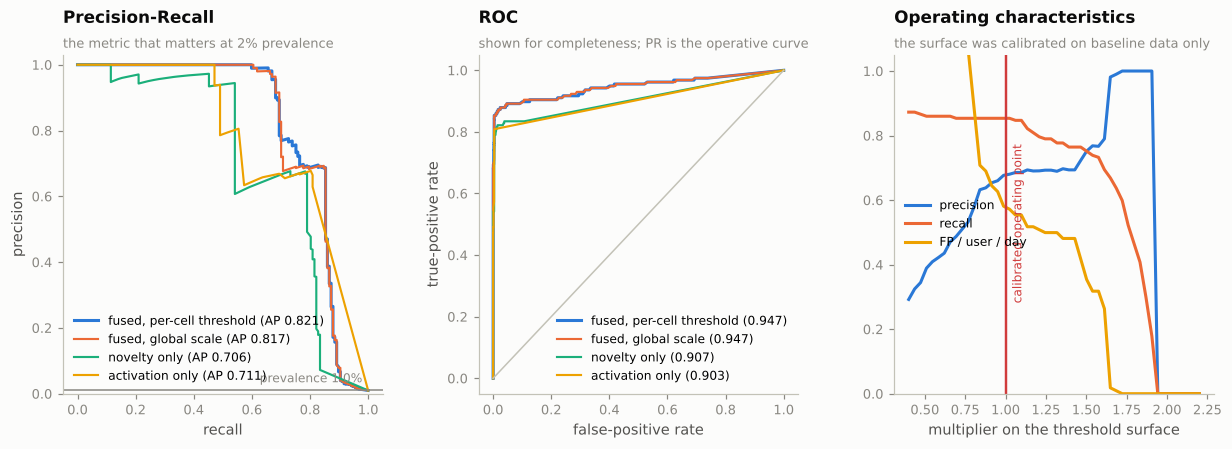

In [55]:
%%requires_ground_truth
fig = plt.figure(figsize=(13.5, 4.0))
gs = fig.add_gridspec(1, 3, wspace=0.3)

# PR curve
ax = fig.add_subplot(gs[0, 0])
for i, (c, lab) in enumerate([("risk_ratio", "fused, per-cell threshold"),
                              ("risk", "fused, global scale"),
                              ("s_nov", "novelty only"), ("s_act", "activation only")]):
    p, rr, _ = precision_recall_curve(y, ACTIVE[c])
    ax.plot(rr, p, color=CAT[i], label=f"{lab} (AP {average_precision_score(y, ACTIVE[c]):.3f})",
            lw=2.0 if c == "risk_ratio" else 1.4)
ax.axhline(y.mean(), color=MUTED, lw=1.0)
ax.text(0.98, y.mean() + 0.025, f"prevalence {y.mean():.1%}", color=MUTED, fontsize=8, ha="right")
finish(ax, "Precision-Recall", "the metric that matters at 2% prevalence",
       xlabel="recall", ylabel="precision")
ax.set_ylim(0, 1.03); ax.legend(loc="lower left", fontsize=8)

# ROC
ax = fig.add_subplot(gs[0, 1])
for i, (c, lab) in enumerate([("risk_ratio", "fused, per-cell threshold"),
                              ("risk", "fused, global scale"),
                              ("s_nov", "novelty only"), ("s_act", "activation only")]):
    fpr, tpr, _ = roc_curve(y, ACTIVE[c])
    ax.plot(fpr, tpr, color=CAT[i], label=f"{lab} ({roc_auc_score(y, ACTIVE[c]):.3f})",
            lw=2.0 if c == "risk_ratio" else 1.4)
ax.plot([0, 1], [0, 1], color=AXIS, lw=1.0)
finish(ax, "ROC", "shown for completeness; PR is the operative curve",
       xlabel="false-positive rate", ylabel="true-positive rate")
ax.legend(loc="lower right", fontsize=8)

# precision / recall / alert volume vs threshold
ax = fig.add_subplot(gs[0, 2])
ths = np.linspace(0.4, 2.2, 50)
sws = [sweep(t) for t in ths]
ax.plot(ths, [s["precision"] for s in sws], color=CAT[0], label="precision")
ax.plot(ths, [s["recall"] for s in sws], color=CAT[1], label="recall")
ax.plot(ths, [s["FP/user/day"] for s in sws], color=CAT[3], label="FP / user / day")
ax.axvline(1.0, color=STATUS["critical"], lw=1.6)
ax.text(1.04, 0.28, "calibrated operating point", color=STATUS["critical"], fontsize=8,
        rotation=90, va="bottom")
finish(ax, "Operating characteristics",
       "the surface was calibrated on baseline data only",
       xlabel="multiplier on the threshold surface")
ax.set_ylim(0, 1.05); ax.legend(loc="center left", fontsize=8)
plt.show()

---
## 21. Visualisation

findfont: Failed to find font weight 600 for DejaVu Sans, now using 700.


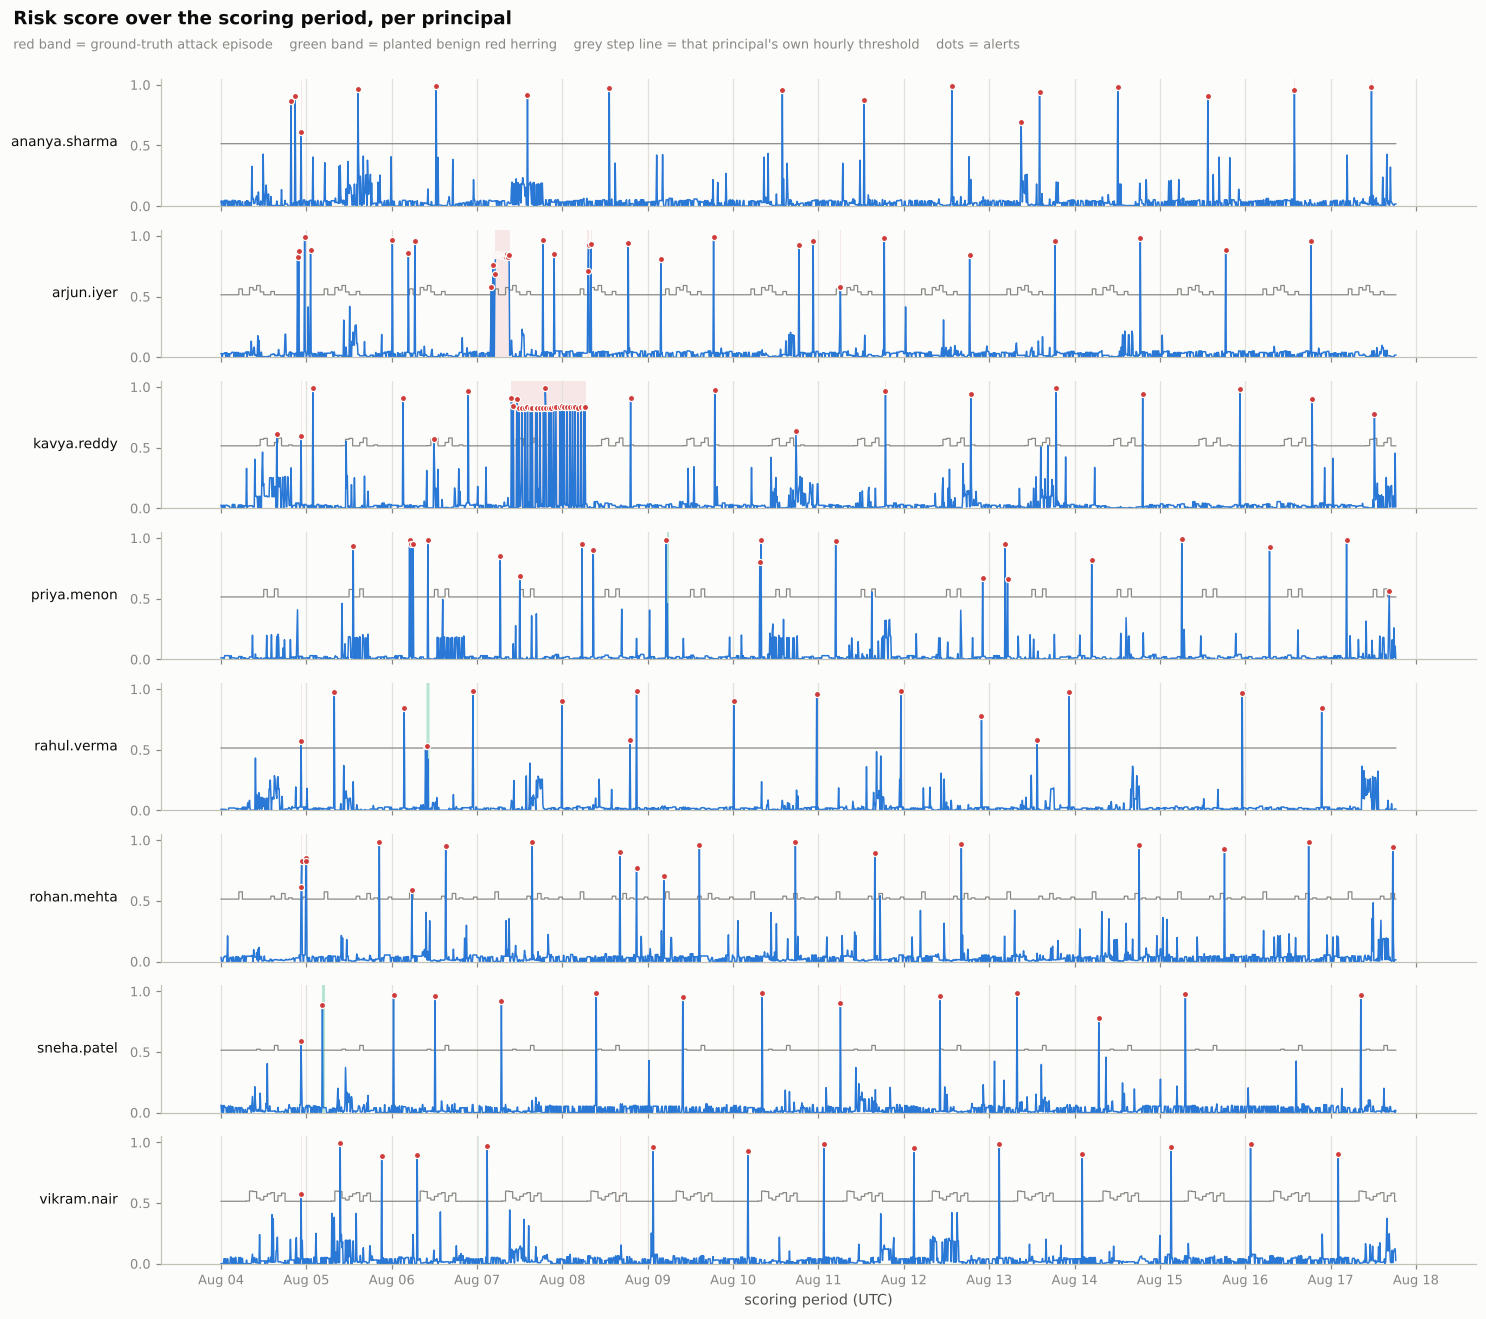

In [56]:
BAND_COLOR = {"NORMAL": "#cde2fb", "LOW": CAT[0], "MEDIUM": STATUS["warning"],
              "HIGH": STATUS["serious"], "CRITICAL": STATUS["critical"]}

fig, axes = plt.subplots(len(PRINCIPALS), 1, figsize=(13.6, 1.5 * len(PRINCIPALS)), sharex=True)
day_edges = [pd.Timestamp(d + " 00:00", tz=TZ) for d in TEST_DATES] + \
            [pd.Timestamp(TEST_DATES[-1] + " 23:50", tz=TZ) + pd.Timedelta(WINDOW)]

for i, u in enumerate(PRINCIPALS):
    ax = axes[i]
    d = TE[TE.user == u].sort_values("win")
    # attack episodes for this principal
    for _, e in (EP.iterrows() if HAS_GT else []):
        if u in e.users:
            ax.axvspan(e.start, e.end, color=STATUS["critical"], alpha=0.10, lw=0, zorder=0)
    # red herrings
    for _, r in (RH.iterrows() if HAS_GT else []):
        if r.user == u:
            ax.axvspan(r.ts - pd.Timedelta("5min"), r.ts + pd.Timedelta("30min"),
                       color=CAT[2], alpha=0.16, lw=0, zorder=0)
    ax.plot(d.win, d.risk, color=CAT[0], lw=1.0, zorder=2)
    hi = d[d.alert]
    ax.scatter(hi.win, hi.risk, s=16, color=STATUS["critical"], zorder=3,
               edgecolor=SURFACE, linewidth=0.8)
    # this principal's own threshold, which steps with the hour of day
    ax.step(d.win, d.threshold, color=MUTED, lw=0.8, where="post", zorder=1)
    for de in day_edges:
        ax.axvline(de, color=GRID, lw=0.8, zorder=0)
    ax.set_ylim(0, 1.05); ax.set_yticks([0, 0.5, 1])
    ax.set_ylabel(u, rotation=0, ha="right", va="center", fontsize=9, color=INK, labelpad=8)
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)
    ax.grid(axis="y"); ax.grid(axis="x", visible=False)

axes[-1].xaxis.set_major_locator(mpl.dates.DayLocator(tz=TZ))
axes[-1].xaxis.set_major_formatter(mpl.dates.DateFormatter("%b %d", tz=TZ))
axes[-1].set_xlabel(f"scoring period ({TZ})")
fig.tight_layout(rect=[0, 0, 1, 0.955])
fig.suptitle("Risk score over the scoring period, per principal", x=0.012, y=0.995,
             ha="left", fontsize=12, color=INK, weight="600")
fig.text(0.012, 0.966, "red band = ground-truth attack episode    green band = planted benign "
                       "red herring    grey step line = that principal's own hourly threshold    "
                       "dots = alerts", ha="left", color=MUTED, fontsize=8.5)
plt.show()

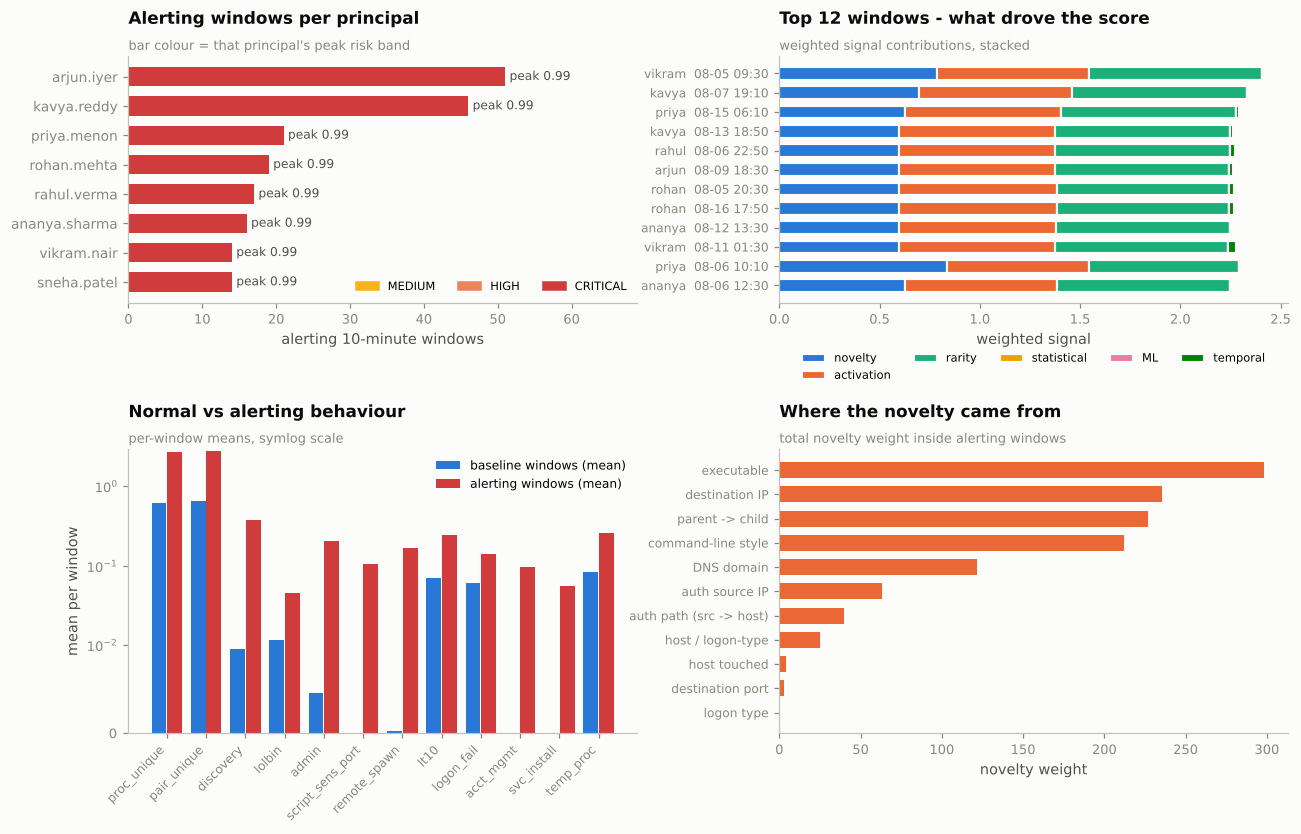

In [57]:
fig = plt.figure(figsize=(13.6, 8.0))
gs = fig.add_gridspec(2, 2, height_ratios=[1, 1.15], hspace=0.55, wspace=0.28)

# (1) top anomalous users
ax = fig.add_subplot(gs[0, 0])
byu = (TE.groupby("user")
       .agg(alerts=("alert", "sum"), peak=("risk", "max"))
       .reindex(PRINCIPALS).sort_values("alerts"))
ax.barh(range(len(byu)), byu.alerts.values,
        color=[BAND_COLOR[band(p)] for p in byu.peak.values], height=0.66)
for i, (a, p) in enumerate(zip(byu.alerts.values, byu.peak.values)):
    ax.text(a + 0.6, i, f"peak {p:.2f}", va="center", fontsize=8, color=INK2)
ax.set_yticks(range(len(byu))); ax.set_yticklabels(byu.index, fontsize=9)
ax.set_xlim(right=byu.alerts.max() * 1.35)
finish(ax, "Alerting windows per principal", "bar colour = that principal's peak risk band",
       xlabel="alerting 10-minute windows", xgrid=True)
ax.legend(handles=[Patch(color=BAND_COLOR[b], label=b) for b in ["MEDIUM", "HIGH", "CRITICAL"]],
          loc="lower right", ncols=3, fontsize=7.5)

# (2) top anomalous windows
ax = fig.add_subplot(gs[0, 1])
tw = TE.nlargest(12, "risk").sort_values("risk")
labels = [f"{r.user.split('.')[0]}  {r.win:%m-%d %H:%M}" for _, r in tw.iterrows()]
left = np.zeros(len(tw))
for i, (c, w, lab) in enumerate([("s_nov", W_NOV, "novelty"), ("s_act", W_ACT, "activation"),
                                 ("s_rare", W_RARE, "rarity"), ("s_stat", W_STAT, "statistical"),
                                 ("s_ml", W_ML, "ML"), ("s_temp", W_TEMP, "temporal")]):
    vals = (w * tw[c]).to_numpy()
    ax.barh(range(len(tw)), vals, left=left, color=CAT[i], height=0.66, label=lab,
            linewidth=1.4, edgecolor=SURFACE)
    left += vals
ax.set_yticks(range(len(tw))); ax.set_yticklabels(labels, fontsize=8)
finish(ax, "Top 12 windows - what drove the score", "weighted signal contributions, stacked",
       xlabel="weighted signal", xgrid=True)
ax.legend(ncols=5, fontsize=7.5, loc="upper center", bbox_to_anchor=(0.5, -0.16))

# (3) normal vs anomalous behavioural profile
ax = fig.add_subplot(gs[1, 0])
show = ["proc_unique", "pair_unique", "discovery_count", "lolbin_count", "admin_count",
        "script_sens_port_count", "remote_spawn_count", "lt10_count", "logon_fail_count",
        "acct_mgmt_count", "svc_install_count", "temp_proc_count"]
norm = W[W.is_train & W.has_telemetry][show].mean()
anom = W.loc[W.wid.isin(TE[TE.alert].wid), show].mean()
xx = np.arange(len(show))
ax.bar(xx - 0.2, norm.values, width=0.38, color=CAT[0], label="baseline windows (mean)")
ax.bar(xx + 0.2, anom.values, width=0.38, color=STATUS["critical"], label="alerting windows (mean)")
ax.set_xticks(xx); ax.set_xticklabels([s.replace("_count", "") for s in show],
                                       rotation=45, ha="right", fontsize=8)
ax.set_yscale("symlog", linthresh=0.01)
finish(ax, "Normal vs alerting behaviour", "per-window means, symlog scale", ylabel="mean per window")
ax.legend(fontsize=8)

# (4) which behavioural dimensions produced the novelty that mattered
ax = fig.add_subplot(gs[1, 1])
alert_wins = set(map(tuple, TE.loc[TE.alert, ["user", "win"]].to_numpy()))
nv = NOV_TE[[tuple(x) in alert_wins for x in NOV_TE[["user", "win"]].to_numpy()]]
bydim = nv.groupby("itype").w.sum().sort_values()
ax.barh(range(len(bydim)), bydim.values, color=CAT[1], height=0.66)
SHORT_LABEL = {"process": "executable", "cmd_sig": "command-line style", "pair": "parent -> child",
               "src_ip": "auth source IP", "auth_path": "auth path (src -> host)",
               "logon_host_type": "host / logon-type", "logon_type": "logon type",
               "dst_ip": "destination IP", "dst_port": "destination port", "domain": "DNS domain",
               "computer": "host touched"}
ax.set_yticks(range(len(bydim)))
ax.set_yticklabels([SHORT_LABEL[i] for i in bydim.index], fontsize=8)
finish(ax, "Where the novelty came from", "total novelty weight inside alerting windows",
       xlabel="novelty weight", xgrid=True)
plt.show()

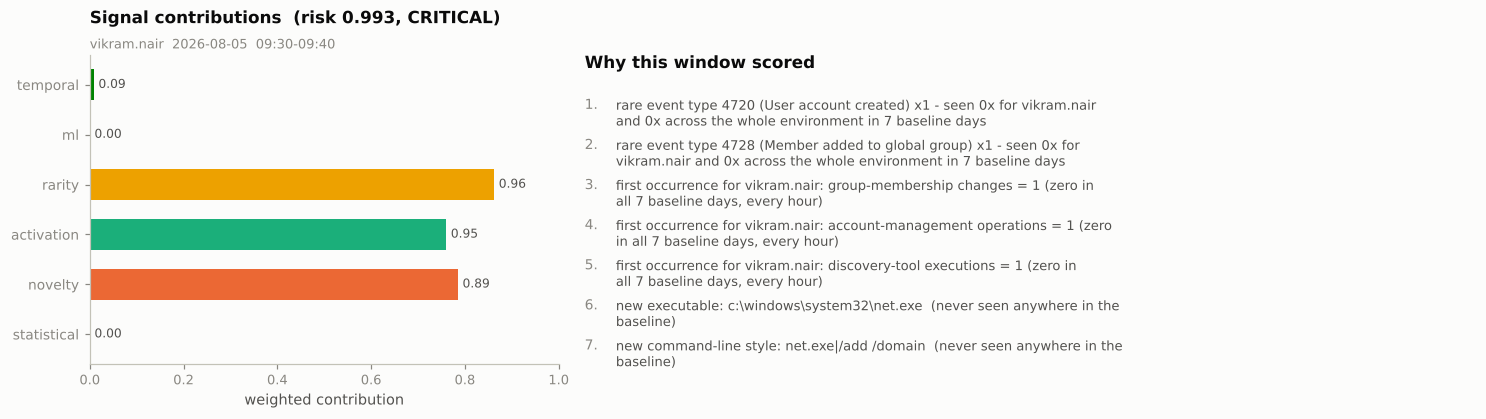

In [58]:
# ---- one alert, fully unpacked --------------------------------------------------------
peak = TE.nlargest(1, "risk").iloc[0]
h, rs = explain(peak.user, peak.win, max_reasons=7)

fig, (axl, axr) = plt.subplots(1, 2, figsize=(13.6, 3.9), gridspec_kw={"width_ratios": [1, 1.9]})

sig = h["signals"]
caps = {"statistical": W_STAT, "novelty": W_NOV, "activation": W_ACT, "rarity": W_RARE, "ml": W_ML, "temporal": W_TEMP}
names = list(sig)
vals = [caps[k] * sig[k] for k in names]
axl.barh(range(len(names)), vals, color=CAT[:len(names)], height=0.62)
for i, (k, v) in enumerate(zip(names, vals)):
    axl.text(v + 0.01, i, f"{sig[k]:.2f}", va="center", fontsize=8, color=INK2)
axl.set_yticks(range(len(names))); axl.set_yticklabels(names, fontsize=9)
axl.set_xlim(0, 1.0)
finish(axl, f"Signal contributions  (risk {h['risk_score']}, {h['risk_level']})",
       f"{h['user']}  {h['date']}  {h['window']}", xlabel="weighted contribution", xgrid=True)

axr.axis("off")
axr.text(0, 1.0, "Why this window scored", fontsize=11, color=INK, weight="600", va="top")
yy = 0.86
for i, r in enumerate(rs, 1):
    axr.text(0, yy, f"{i}.", fontsize=9, color=MUTED, va="top")
    axr.text(0.035, yy, textwrap.fill(r["text"], 74), fontsize=8.6, color=INK2, va="top")
    yy -= 0.075 + 0.055 * (len(textwrap.wrap(r["text"], 74)) - 1)
plt.tight_layout(); plt.show()

---
## 22. Results

### Alerts, and the incidents they roll up into

A stream of alerting windows is not a stream of things for an analyst to look at. Consecutive or nearby alerting
windows for the same principal are the same activity, so they are grouped into **incidents**. The gap
tolerance is **90 minutes**, chosen because a slow C2 implant beacons on an interval measured in tens of
minutes - a 30-minute tolerance would shatter one 21-hour implant into two dozen separate tickets. This is
what the queue actually looks like.

In [59]:
TE["win_end"] = TE.win + pd.Timedelta(WINDOW)   # needed with or without labels
if not HAS_GT:   # no labels: incidents are listed without a verdict
    TE["is_attack"], TE["is_red_herring"] = False, False
    TE["attack_steps"] = [[] for _ in range(len(TE))]

INCIDENT_GAP = pd.Timedelta("90min")   # a slow implant beacons every ~40 min by design
ALERTS = TE[TE.alert].sort_values(["user", "win"]).copy()
ALERTS["gap"] = ALERTS.groupby("user").win.diff()
ALERTS["new_incident"] = (ALERTS.gap.isna()) | (ALERTS.gap > INCIDENT_GAP)
ALERTS["incident_id"] = ALERTS.new_incident.cumsum()

INC = (ALERTS.groupby("incident_id")
       .agg(user=("user", "first"), start=("win", "min"), end=("win_end", "max"),
            windows=("win", "size"), peak_risk=("risk", "max"), events=("event_count", "sum"),
            is_attack=("is_attack", "any"), is_rh=("is_red_herring", "any"),
            steps=("attack_steps", lambda s: sorted({x for l in s for x in l})))
       .sort_values("peak_risk", ascending=False).reset_index(drop=True))
INC["level"] = INC.peak_risk.map(band)
INC["verdict"] = (np.where(INC.is_attack, "ground-truth attack",
                           np.where(INC.is_rh, "planted red herring", "not in ground truth"))
                  if HAS_GT else "unlabelled")
INC.insert(0, "incident", ["INC-%03d" % (i + 1) for i in range(len(INC))])

n_user_days_test = len(TE) / WINDOWS_PER_DAY
print(f"{len(ALERTS)} alerting windows  ->  {len(INC)} incidents "
      f"over {n_user_days_test:.1f} user-days ({len(PRINCIPALS)} principals x "
      f"{n_user_days_test / len(PRINCIPALS):.1f} days)")
print(f"   = {len(INC) / n_user_days_test:.2f} incidents per user per day")
print()
display(INC.assign(start=INC.start.dt.strftime("%m-%d %H:%M"), end=INC.end.dt.strftime("%m-%d %H:%M"),
                   peak_risk=INC.peak_risk.round(3),
                   steps=INC.steps.map(lambda s: ",".join(map(str, s)) if s else "-"))
        [["incident", "user", "start", "end", "windows", "events", "peak_risk", "level",
          "steps", "verdict"]])

198 alerting windows  ->  131 incidents over 110.2 user-days (8 principals x 13.8 days)
   = 1.19 incidents per user per day



,incident,user,start,end,windows,events,peak_risk,level,steps,verdict
0,INC-001,vikram.nair,08-05 09:30,08-05 09:40,1,45.0,0.993,CRITICAL,12,ground-truth attack
1,INC-002,kavya.reddy,08-07 09:40,08-08 06:30,30,666.0,0.991,CRITICAL,44,ground-truth attack
2,INC-003,priya.menon,08-15 06:10,08-15 06:20,1,36.0,0.990,CRITICAL,125,ground-truth attack
3,INC-004,kavya.reddy,08-13 18:50,08-13 19:00,1,15.0,0.989,CRITICAL,114,ground-truth attack
4,INC-005,rahul.verma,08-06 22:50,08-06 23:00,1,24.0,0.989,CRITICAL,36,ground-truth attack
...,...,...,...,...,...,...,...,...,...,...
126,INC-127,rahul.verma,08-13 13:30,08-13 13:40,1,15.0,0.577,MEDIUM,-,not in ground truth
127,INC-128,kavya.reddy,08-06 11:50,08-06 12:00,1,308.0,0.574,MEDIUM,-,not in ground truth
128,INC-129,rahul.verma,08-04 22:30,08-04 22:40,1,4.0,0.573,MEDIUM,5,ground-truth attack
129,INC-130,priya.menon,08-17 16:30,08-17 16:40,1,378.0,0.567,MEDIUM,-,not in ground truth


In [60]:
print("=" * 92)
print("TOP INCIDENTS - full explanation of the peak window of each")
print("=" * 92)
for _, inc in INC.head(6).iterrows():
    w = ALERTS[(ALERTS.user == inc.user) & (ALERTS.win >= inc.start) &
               (ALERTS.win_end <= inc.end)].nlargest(1, "risk").iloc[0]
    print(f"\n### {inc.incident}   {inc.user}   {inc.start:%Y-%m-%d %H:%M} -> {inc.end:%H:%M}   "
          f"{inc.windows} window(s)   verdict: {inc.verdict}")
    print_alert(w.user, w.win, max_reasons=5)

TOP INCIDENTS - full explanation of the peak window of each

### INC-001   vikram.nair   2026-08-05 09:30 -> 09:40   1 window(s)   verdict: ground-truth attack
User: vikram.nair    Date: 2026-08-05    Window: 09:30-09:40 (UTC)
Anomaly signals: statistical=0.0  novelty=0.892  activation=0.95  rarity=0.958  ml=0.0  temporal=0.085
Risk Score: 0.993    Risk Level: CRITICAL    Events in window: 45
--------------------------------------------------------------------------------------------
Reasons:
  1. [rarity     ] rare event type 4720 (User account created) x1 - seen 0x for vikram.nair and 0x across
     the whole environment in 7 baseline days
  2. [rarity     ] rare event type 4728 (Member added to global group) x1 - seen 0x for vikram.nair and
     0x across the whole environment in 7 baseline days
  3. [activation ] first occurrence for vikram.nair: group-membership changes = 1 (zero in all 7 baseline
     days, every hour)
  4. [activation ] first occurrence for vikram.nair: account-

In [61]:
# ---- the attack story, reconstructed from alerts alone ---------------------------------
print("=" * 92)
print("KILL-CHAIN VIEW - what an analyst would have seen, in order")
print("=" * 92)
story = INC[INC.is_attack].sort_values("start") if HAS_GT else INC.iloc[:0]
if not HAS_GT:
    print("  (no ground truth - attack episodes cannot be named; see the incident table above)")
for _, inc in story.iterrows():
    steps = ", ".join(f"step {s}" for s in inc.steps) if inc.steps else ""
    desc = "; ".join(EP[EP.step.isin(inc.steps)].desc.tolist())[:70] if inc.steps else ""
    print(f"{inc.start:%m-%d %H:%M}  {inc.user:<14} {inc.level:<9} risk {inc.peak_risk:.2f}   "
          f"{desc}  [{steps}]")

print()
print("-" * 92)
print("UNBASELINED PRINCIPALS - activity that could not be scored (reported, never silently dropped)")
print("-" * 92)
lowd = raw[raw.in_scope & raw.attr_user.isin(LOW_DATA) & raw.date.isin(TEST_DATES)]
if len(lowd):
    t = (lowd.groupby(["attr_user", "date"]).size().rename("events").reset_index()
         .pivot(index="attr_user", columns="date", values="events").fillna(0).astype(int))
    display(t)
    print("  These accounts have no usable user x hour baseline (see section 09), so no risk score is")
    print("  produced for them. They appear almost exclusively as failed-authentication targets and are")
    print("  surfaced here for manual review instead.")
else:
    print("  none active during the scoring period")

KILL-CHAIN VIEW - what an analyst would have seen, in order
08-04 19:40  ananya.sharma  CRITICAL  risk 0.91   Logon; Connection; Process  [step 1, step 2]
08-04 21:30  arjun.iyer     CRITICAL  risk 0.87   Logon; Process  [step 3, step 4]
08-04 22:30  rahul.verma    MEDIUM    risk 0.57   Credential Spray  [step 5]
08-04 22:30  sneha.patel    MEDIUM    risk 0.59   Credential Spray  [step 5]
08-04 22:30  kavya.reddy    MEDIUM    risk 0.60   Credential Spray  [step 5]
08-04 22:30  ananya.sharma  HIGH      risk 0.61   Credential Spray  [step 5]
08-04 22:30  rohan.mehta    CRITICAL  risk 0.85   Credential Spray; Connection; Logon; Process  [step 5, step 8]
08-04 22:30  vikram.nair    MEDIUM    risk 0.58   Credential Spray  [step 5]
08-04 23:30  arjun.iyer     CRITICAL  risk 0.99   Create Remote Thread; Process  [step 7]
08-05 01:10  arjun.iyer     CRITICAL  risk 0.88   Explicit Credentials; Logon; Process  [step 9]
08-05 01:50  kavya.reddy    CRITICAL  risk 0.99   Connection; Process; Schedu

date,2026-08-04,2026-08-05,2026-08-06,2026-08-07,2026-08-08,2026-08-09,2026-08-10,2026-08-11,2026-08-12,2026-08-13,2026-08-14,2026-08-15,2026-08-16,2026-08-17
attr_user,,,,,,,,,,,,,,
meera.joshi,9,13,7,10,10,9,6,10,7,3,9,10,8,5
svc-print-old,7,5,9,9,10,4,6,8,9,4,4,11,8,7
svc_mgmt,4,8,4,4,0,0,4,0,8,4,4,0,0,0
svc_patch,18,14,15,20,18,15,23,14,19,17,22,16,17,16


  These accounts have no usable user x hour baseline (see section 09), so no risk score is
  produced for them. They appear almost exclusively as failed-authentication targets and are
  surfaced here for manual review instead.


In [62]:
print("=" * 92)
print("SUMMARY")
print("=" * 92)
print(f"""
Corpus                 {len(raw):,} events, {len(ALL_DATES)} UTC days, {raw.Computer.nunique()} hosts, {raw.EventID.nunique()} Event IDs
Attributed             {int(raw.attr_user.notna().sum()):,} events ({raw.attr_user.notna().mean():.0%}) - {int((raw.attr_method=='B_5156_proc_lifetime').sum()):,} of them by process-lifetime correlation
Scored principals      {len(PRINCIPALS)} ({', '.join(PRINCIPALS)})
Windows                {len(W):,} = {len(PRINCIPALS)} users x {len(ALL_DATES)} days x {WINDOWS_PER_DAY} windows
                       {int(W.has_telemetry.sum()):,} inside sensor coverage; empty windows retained
Features               {len(FEATS)} numeric per window + {len(ITEM_DEF)} categorical behaviour dimensions
Baseline               {len(BASELINE['num']['med_h'])} user x hour cells, {'/'.join(str(int(v)) for v in sorted(obs.n_obs.unique()))} observations each
                       fitted on {TRAIN_DATES[0]} .. {TRAIN_DATES[-1]} only

Threshold              {THRESH.min():.3f}-{THRESH.max():.3f}  (user x hour clamp {SHAPE_LO:.2f}-{SHAPE_HI:.2f})
                       (reference level {ALERT_THRESHOLD}), calibrated on the leave-one-day-out
                       baseline null at a {FP_BUDGET_PER_USER_DAY} alert/user/day budget
Analyst queue          {len(INC)} incidents ({len(INC)/(len(TE)/WINDOWS_PER_DAY):.2f} per user per day)
""")
if HAS_GT:
    print(f"""PR-AUC                 {average_precision_score(y, ACTIVE.risk):.3f}   (prevalence {y.mean():.2%})
ROC-AUC                {roc_auc_score(y, ACTIVE.risk):.3f}
Precision / Recall     {OP['precision']:.3f} / {OP['recall']:.3f}   (F1 {OP['F1']:.3f})
Accuracy / balanced    {OP['accuracy']:.4f} / {OP['balanced_acc']:.4f}
Attack steps detected  {n_det}/{len(EP)}   (misses itemised in 20.3)
False positives        {OP['FP']} windows over {N_USER_DAYS_TEST:.0f} user-days = {OP['FP/user/day']:.2f} per user per day
Confusion matrix       TP {CMR['TP']}  FP {CMR['FP']}  FN {CMR['FN']}  TN {CMR['TN']:,}   (user x 10-min window, GROUND_TRUTH.md label)
Malicious cells        {len(CELLS)} from GROUND_TRUTH.md  ({hit} alerted; timeline {int((core.detected=='YES').sum())}/{len(core)})
""")
else:
    print("Evaluation             skipped - no ground-truth file; no confusion matrix can be computed without labels")


SUMMARY

Corpus                 1,526,857 events, 21 UTC days, 12 hosts, 31 Event IDs
Attributed             922,390 events (60%) - 48,445 of them by process-lifetime correlation
Scored principals      8 (ananya.sharma, arjun.iyer, kavya.reddy, priya.menon, rahul.verma, rohan.mehta, sneha.patel, vikram.nair)
Windows                24,192 = 8 users x 21 days x 144 windows
                       23,040 inside sensor coverage; empty windows retained
Features               72 numeric per window + 11 categorical behaviour dimensions
Baseline               192 user x hour cells, 36/39/42 observations each
                       fitted on 2026-07-28 .. 2026-08-03 only

Threshold              0.515-0.598  (user x hour clamp 0.85-1.40)
                       (reference level 0.605), calibrated on the leave-one-day-out
                       baseline null at a 0.2 alert/user/day budget
Analyst queue          131 incidents (1.19 per user per day)

PR-AUC                 0.817   (prevalence 0.99%)

---
## 23. Save Baseline / Model

Everything needed to score a *new* day without re-reading the raw log is written out: the numeric baseline,
the behavioural inventories, the rarity tables, the fitted IsolationForest, and the configuration that ties
them together.

In [63]:
import pickle

BASELINE_TABLE.to_parquet(os.path.join(OUT_DIR, "baseline_user_hour.parquet"), index=False)
BASELINE["known"].to_parquet(os.path.join(OUT_DIR, "baseline_inventories.parquet"), index=False)
BASELINE["gcnt"].to_parquet(os.path.join(OUT_DIR, "baseline_global_rarity.parquet"), index=False)
BASELINE["eid_ucnt"].to_parquet(os.path.join(OUT_DIR, "baseline_eventid_rarity.parquet"), index=False)
BASELINE["act_max"].reset_index().to_parquet(os.path.join(OUT_DIR, "baseline_activation.parquet"),
                                             index=False)
THRESH.reset_index().to_parquet(os.path.join(OUT_DIR, "threshold_surface.parquet"), index=False)
W.to_parquet(os.path.join(OUT_DIR, "window_features.parquet"), index=False)
ev[EVENT_TABLE_COLS].to_parquet(os.path.join(OUT_DIR, "attributed_events.parquet"), index=False)
TE.drop(columns=["attack_steps"]).to_parquet(os.path.join(OUT_DIR, "scored_test_windows.parquet"),
                                             index=False)
TR.to_parquet(os.path.join(OUT_DIR, "scored_baseline_windows_lodo.parquet"), index=False)
(INC.assign(steps=INC.steps.map(lambda s: ",".join(map(str, s))))
    .to_csv(os.path.join(OUT_DIR, "incidents.csv"), index=False))
ALERTS.drop(columns=["attack_steps"]).to_csv(os.path.join(OUT_DIR, "alerts.csv"), index=False)
if HAS_GT:
    DET.to_csv(os.path.join(OUT_DIR, "attack_step_detection.csv"), index=False)

MODEL = {
    "config": {"local_tz": TZ, "window": WINDOW, "train_dates": TRAIN_DATES,
               "principals": PRINCIPALS, "stat_features": STAT_FEATURES,
               "act_features": ACT_FEATURES, "act_weights": ACT_WEIGHTS,
               "item_def": [d[0] for d in ITEM_DEF], "base_w": BASE_W, "gnov_w": GNOV_W,
               "Z0": Z0, "Z1": Z1, "K_STAT": K_STAT, "K_NOV": K_NOV, "K_RARE": K_RARE,
               "K_ACT": K_ACT, "weights": FULL_W, "alert_threshold": ALERT_THRESHOLD,
               "risk_bands": RISK_BANDS},
    "numeric_baseline": BASELINE["num"],
    "threshold_surface": THRESH,
    "isolation_forest": iso,
}
with open(os.path.join(OUT_DIR, "model.pkl"), "wb") as fh:
    pickle.dump(MODEL, fh)

for f in sorted(os.listdir(OUT_DIR)):
    print(f"  {f:<44} {os.path.getsize(os.path.join(OUT_DIR, f)) / 1024:9.1f} KB")
print(f"\nartifacts written to {OUT_DIR}")

  alerts.csv                                        69.1 KB
  attack_step_detection.csv                          9.9 KB
  attributed_events.parquet                       2775.1 KB
  baseline_activation.parquet                       24.5 KB
  baseline_eventid_rarity.parquet                    3.1 KB
  baseline_global_rarity.parquet                    11.1 KB
  baseline_inventories.parquet                      14.6 KB
  baseline_user_hour.parquet                        63.5 KB
  incidents.csv                                     18.1 KB
  model.pkl                                       5060.8 KB
  scored_baseline_windows_lodo.parquet             160.6 KB
  scored_test_windows.parquet                      310.0 KB
  threshold_surface.parquet                          2.8 KB
  window_features.parquet                          444.4 KB

artifacts written to /home/claude/work/run20/baseline_output2


---
## 24. Assumptions, Limitations and Warnings

Collected in one place rather than scattered through the notebook.

### Attribution

* **39% of the corpus is never attributed.** Almost all of it is Security `5156` whose owning PID belongs to
  a process the Sysmon sensor never saw start - long-running `lsass.exe`, `svchost.exe`, `dns.exe`, `System`.
  These are machine-level rather than user-level flows. All 44,353 `5156` records belonging to processes
  the Sysmon sensor saw start did resolve, so the loss is not silently distorting user behaviour, but the exclusion is real
  and is why the network features lean on Sysmon 3.
* **The `LogonId + Computer + time` correlation asked for in the brief was built and then measured against
  Sysmon's own `User` field.** It agrees on the overwhelming majority of joinable events, but it is
  *strictly worse coverage* than the direct field, so the direct field is used for attribution and the
  session table is used for authentication features. That choice is evidence-based, not assumed.
* Sysmon `8`/`10` are attributed to `SourceUser` (the actor), not `TargetUser` (the victim process owner).
* Security `4625` is attributed to `TargetUserName`, so a password spray appears as an anomaly on **each
  sprayed account** rather than on the attacker. That is the correct per-user framing, but it means a spray
  produces several low-volume alerts rather than one loud one.
* **`SYSTEM`, `LOCAL SERVICE`, `NETWORK SERVICE`, `ANONYMOUS LOGON` and machine accounts are excluded from
  scoring.** Their volume is machine-driven and would dominate the model. They remain in the event table.
* Four principals (`meera.joshi`, `svc-print-old`, `svc_batch`, `svc_mgmt`) have too little baseline data
  to support 24 hourly profiles and are reported separately instead of being scored.

### Ground truth and evaluation

* **Missed steps are itemised with their evidence in section 20.3**, generated from the data rather than
  written by hand. On this dataset they are logons and sessions whose host, source and logon type are
  already in the user's baseline, plus a spray fan-out whose per-account cells hold one failed logon.
* **The label (20.0) comes only from `GROUND_TRUTH.md`:** timeline timestamps, the spray's real victim
  windows, and beacon windows inside each beacon's declared duration. The naive timestamp-only count is
  printed in 20.7 with every cell that differs, so the two numbers can be reconciled by hand.

### Method

* `risk_score` is a **behavioural-deviation** score, not a probability of maliciousness. No calibrated
  probabilistic model was fitted, so no such claim is made. Bands are `NORMAL / LOW / MEDIUM / HIGH /
  CRITICAL`.
* The fusion weights are hand-set from each signal's baseline profile (section 17) rather than learned -
  learning them would require labelled attacks, which would defeat the unsupervised premise. Section 20's
  ablation shows what each one is worth.
* With 42 observations per `user x hour` cell, a cell's own MAD is frequently 0. The shrunk scale
  (cell MAD -> user all-hours MAD -> absolute floor) is what makes the z-score usable; it is a deliberate
  bias-variance trade, and it does make the statistical signal conservative.
* The tool taxonomies (LOLBins, discovery utilities, admin tools, script hosts) are general Windows security
  knowledge. No scenario-specific indicator - no attacker address, no malicious filename, no ground-truth
  command line - is used anywhere in the detection path. Those strings appear only inside section 20, which
  is evaluation.
* A single 10-day scored scenario with one attack chain and eight users cannot establish generalisation. The
  numbers here describe this dataset.

### If this went to production

1. Re-fit the baseline on a rolling 30-day window rather than a fixed 7 days, so seasonality and role changes
   are absorbed.
2. Feed the incident table an allow-list keyed on change-management records - the authorised-enumeration red
   herring is exactly the case that closes automatically once a change ticket is joinable.
3. Add a peer-group signal ("normal for a help-desk account") next to the per-user signal, to give accounts
   with thin history something to be compared against.
4. Track score stability: a feature whose baseline drifts week over week should lose weight automatically.